# Cosmic veto from a dimuon-vertex fit, and what is left in the DSA-muon high-pT tail

This study tests a new cosmic-muon veto for the 1-LJ control region, then characterizes the
high-momentum DSA muons that survive the current veto. Terms used throughout:

- A **lepton jet (LJ)** is a cluster of collimated leptons or photons; a **mu-type LJ** contains
  muons. The **1-LJ control region** (`cr_1egmOr1mu_lj`) holds events with one LJ
  (`= 1 muLj or 1 egmLJ`).
- **DSA muons** are displaced standalone muons, reconstructed in the muon chambers alone;
  **PF muons** are the particle-flow muons.
- **`vtx_chi2`** (`mu_ljs.vtx_chi2`) is the smallest normalized chi2 of any stored dimuon vertex
  whose two muons both belong to the LJ (section 1). The **vertex veto** keeps an LJ with
  `0 <= vtx_chi2 < 5`.
- The **Spread veto** is the existing cosmic veto: four `*Spread_*` cuts on how far apart the
  LJ's muons are in impact parameter and vertex position, together with the **cosAlpha** event
  cut. That cut rejects events with a back-to-back muon pair (`cosAlpha`, the cosine of the
  opening angle between two muons, at or below -0.99), the signature of a cosmic muon crossing
  the detector.
- The **tail** is the DSA muons inside mu-type LJs with `pT >= 200` GeV; the **bulk** is the
  low-pT reference (section 5). **nHits** is the number of DT plus CSC hits on the DSA track.
- The **full background stack** is the 2018 background MC used for the control region
  (TTJets, Drell-Yan, eleven QCD pT bins, WW/WZ/ZZ; listed in `README.md`). The **eight-sample tail
  set** is the eight of its samples that populate the tail; it is the only MC with the
  two-dimensional histograms used from section 5 on.

**What was done.** `vtx_chi2` was built from the LLPNanoAOD dimuon-vertex tables as an
alternative to the Spread veto, and tested on 2018C `DoubleMuon` data, the 2018 background stack
and the full 180-sample v10 signal grid. The study has two halves.

**The veto comparison.** The vertex veto tags the same cosmics as the Spread veto: it removes
98% of the mu-type LJs in the spread-inverted cosmic region (section 2b). It is a tighter cut with
no additional data-versus-MC separating power and a higher signal cost. Averaged over the grid it
keeps 0.690 of the signal LJs against 0.961 for the Spread veto. Above 200 GeV in DSA-muon pT it
leaves the same residual data/MC ratio (2.38 against 2.31 on the same background stack). The
Spread veto with the cosAlpha cut, `main`'s baseline since PR #56, therefore stays, and the
vertex veto is not adopted. The signal efficiencies are for the Spread veto in its as-run
`vxySpread` form; `main`'s `dxySpread` form was not run on signal. The vertex veto keeps more
signal only in one corner of the grid: `m_Zd = 5` GeV, mediator mass 100-150 GeV,
`ctau >= 130` mm.

**What survives the veto.** The Spread veto with the cosAlpha cut removes 87% of the >= 200 GeV
DSA-muon tail in 2018C data (2414 -> 309). In MC it removes 54% of the **full background
stack's** tail (293.6 -> 133.7) and only 3% of the tail of the **eight-sample tail set** used
from section 5 on (133.7 -> 129.5). The difference is one high-weight `QCD_Pt30To50` event that
the veto removes; every MC tail number below is quoted with the name of the set it came from.
The removed component is unambiguously cosmic. What survives stays as sections 5-8 leave it:
not cosmic (below 6.2% at 95% CL), and of the size DSA momentum mismeasurement would produce at
roughly factor-1.5 precision. It exceeds MC by 2.4 +/- 0.4 (eight-sample tail set), but that raw
ratio carries the control region's normalization mismatch (section 3.1). A ratio of rates
cancels the mismatch. The **feed-up** rate is the rate at which a muon with PF pT below 100 GeV
is reconstructed as a DSA muon at or above 200 GeV, measured in a control sample of DSA muons
matched to PF muons (section 8). The post-veto tail rate divided by the feed-up rate is
0.95 +/- 0.06 in data and 0.99 +/- 0.18 in MC.

Sections 5 to 9 work through the evidence, the candidate handles and the caveats. Section 10
tests a **transfer factor**: the probability, measured on DSA muons matched to PF muons (section 10 uses the
PF muon the cross-cleaning pairs each DSA muon with), that a muon of a
given true pT is measured at a given DSA pT. It is **folded** onto the LJs' own low-pT DSA
spectrum: each low-pT bin is spread over the measured-pT bins with these probabilities and the
results are summed, which predicts the tail. The prediction fails: in MC alone the fold
over-predicts the tail of the `nHits < 20` slice by a factor 2.45 with the Spread veto, and in
data it over-predicts the 100-200 GeV sideband of that slice by 7.7 statistical standard
deviations. Nothing from section 10 is applied. Section 11 concludes.

Inputs are the `.coffea` outputs of the ten run notebooks in this directory (under
`RunOutputFiles/`) and the three transfer-factor JSON records in `transfer_factor/`. `README.md`
says what each run notebook runs and in what order.

In [1]:
import os, sys, glob, json, math
import numpy as np
import coffea.util
import matplotlib.pyplot as plt
import mplhep as hep

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities
utilities.set_plot_style()
%matplotlib inline

# No p-values are printed for the shape tests below. They use diagonal-only errors on bins
# tied by a shared normalization and their value moves by a factor of about 4 with the
# definition, so a two-significant-figure tail probability would be false precision;
# chi2 per degree of freedom, with its definition attached, is the statement.

# DoubleMuon 2018C / full-2018 lumi; the MC histograms are lumi-weighted to 59.83/fb
LUMI_DATA, LUMI_MC = 6.97, 59.830
ratio = LUMI_DATA / LUMI_MC
print(f"MC scale factor {LUMI_DATA}/{LUMI_MC} = {ratio:.5f}")

MC scale factor 6.97/59.83 = 0.11650


## Selections used in this study

**Where the outputs come from.** The outputs read below were produced between 2026-08-25 and
2026-09-05 on the fork `murtaza-safdari/SIDM`, branch `vertex-cosmic-veto-data2018` (kept for
provenance). That was before the cosmic-veto baseline of PR #56 was merged into `main`. The
commits named below are on that branch. The 2018C, background and signal runs did not record
their commit: their `.meta.yaml` provenance sidecars were written afterwards and carry
`sidm_commit: null`. The four full-2018 response runs of section 10 record commit `f6e23f1`,
from a working tree that already contained the histogram collections committed in `5aa6988`.

**The channel definitions were the same for all runs.** `selections.yaml` did not change on that
branch between `defc8a0` and its tip `26c6d1c`, and the run-time sidecars of the four full-2018
output directories record the same definitions. The six back-filled sidecars (written after the
runs, see `README.md`) take their channel list from each output's cutflow and the definitions
from that branch's `selections.yaml` at the time they were written. They therefore agree with it
by construction and confirm nothing on their own. Rerunning stored outputs with the as-run
selections (see `README.md`) confirms the definitions independently: bit for bit for one data sample of the
full-2018 segment-matched run (`DoubleMuon_2018D_22` of `vtxResp2_2018Full`) and one signal
sample (`2Mu2E_200GeV_0p25GeV_10p0mm` of `vtxChi2_signal_2018`), and, through its ZZ sample,
for the 2018C data-and-background run (`vtxChi2_vs_spread_2018C`).

**Why these channels.** The study compares cosmic-veto options. It therefore needs a baseline
with no cosmic veto at all, and each veto applied on its own to that same baseline. On `main`
the baseline itself has changed: the cosAlpha event cut is part of the base event cuts, and the
muon-LJ cuts of `base_ljDisplacementIso` include spread cuts. `main`'s channels therefore cannot
provide the no-veto reference. The channels used here are kept exactly as run, in
`sidm/configs/selections_vertexChi2_as_run.yaml`, and the run notebooks pass
`selections_cfg="configs/selections_vertexChi2_as_run.yaml"` to `SidmProcessor`.

**How the as-run baseline differs from `main` today:**

- Unchanged: the eta-phi veto on all four LJ sources (electrons, photons, PF muons, DSA muons)
  and the event cut `>=2 muons (pf or dsa) pT > 26 GeV`.
- As run, the PF muons at the LJ source have no explicit DT + CSC hit-count requirement. `main` now also
  requires `DT + CSC hits > 3` on them (`trkNumDTHits + trkNumCSCHits > 3`, added in commit
  `65b46a86` to the `muons_ljsource_cuts` anchor of `selections.yaml`). The as-run baseline
  lacks this cut, and its effect on the veto comparison was not measured.
- As run, the base event cuts do not contain `all cosAlpha(mu, mu) > -0.99`; only the channels
  that use it as part of a veto apply it. On `main` it is in the base event cuts. `main`'s
  `cr_1egmOr1mu_lj` and `base_ljDisplacementIso` therefore include it, and `main`'s
  `cosmic_muons` requires both it and its inverse `any cosAlpha(mu, mu) <= -0.99`.
- As run, the muon LJs of `base_ljDisplacementIso` carry no spread cuts. On `main` they require
  `dzSpread_mu <= 50`, `dxySpread_mu <= 50`, `dzSpread_pf <= 10` and `dxySpread_pf <= 10`.
  `cr_1egmOr1mu_lj` has no spread cuts in either version.
- The Spread veto as run (`cr_1egmOr1mu_lj_spreadMu_spreadPfMu_CosMu`,
  `base_ljDisplacementIso_cosAlpha_ljSpread`) cuts on `vxySpread`, the transverse spread of the
  muon vertex positions; `main`'s spread cuts use `dxySpread`, the transverse impact-parameter
  spread. Both use `dzSpread` for the longitudinal cuts. The `dxySpread` version was also run,
  as `cr_1egmOr1mu_lj_spreadMu_spreadPfMu_CosMu_dxy` (section 1), on data and the background
  stack only; the signal grid was run with the `vxySpread` form alone.
- `inverse_spread` is the mu-LJ cut that defines the spread-inverted cosmic region
  `cosmic_muons`. At production time it was the OR of `vzSpread_pf > 10`, `vxySpread_pf > 10`
  and `vxySpread_mu > 50`, the last term written twice. `main` has since redefined that name as
  the OR of `dzSpread_pf > 10`, `dxySpread_pf > 10`, `dxySpread_mu > 50` and
  `dzSpread_mu > 50`. The production-time definition is kept in `sidm/definitions/cuts.py`
  under the name `inverse_spread (vz/vxy, as run)`, which is the name in the table below; the
  run-time sidecars list it as `inverse_spread`. It is an object cut, so it is not a cutflow
  row. As run, `cosmic_muons` is therefore only approximately the inverse of the Spread veto:
  it uses `vzSpread_pf` where the veto uses `dzSpread_pf`, and it has no longitudinal muon
  term, so a lepton jet that fails only `dzSpread_mu <= 50` is in neither region.
- Four of the channel names below also exist in `main`'s `selections.yaml`.
  `cr_1egmOr1mu_lj`, `cosmic_muons` and `base_ljDisplacementIso` select different events there.
  `cr_1egmOr1mu_lj_spreadMu_spreadPfMu_CosMu_dxy` applies the same cuts there in a different
  order, and `main`'s version lists `all cosAlpha(mu, mu) > -0.99` twice, once through its base
  event cuts and once explicitly. The other channels exist only in the as-run file.

The table below is read from the as-run file when this notebook runs. "LJ-source cuts" are the
object cuts listed above the table, applied to the four LJ sources before the LJs are built.

In [2]:
# Every channel of the study, as run, read from the as-run selections file
import yaml
from IPython.display import Markdown, display

ASRUN_CFG = "sidm/configs/selections_vertexChi2_as_run.yaml"
with open(f"{sidm_path}/{ASRUN_CFG}", encoding="utf8") as fh:
    asrun = yaml.safe_load(fh)

LJ_SOURCES = ("electrons", "photons", "muons", "dsaMuons")
ljsource_cuts = {o: asrun["cr_1egmOr1mu_lj"]["obj_cuts"][o] for o in LJ_SOURCES}

def fmt(cuts):
    # a "|" inside a table cell has to be escaped, even inside a code span
    return ", ".join("`" + c.replace("|", "\\|") + "`" for c in cuts)

def obj_cell(obj_cuts):
    same = all(obj_cuts.get(o) == ljsource_cuts[o] for o in LJ_SOURCES)
    parts = ["LJ-source cuts"] if same else [f"{o}: {fmt(obj_cuts[o])}" for o in LJ_SOURCES if o in obj_cuts]
    parts += [f"{o}: {fmt(c)}" for o, c in obj_cuts.items() if o not in LJ_SOURCES]
    return "<br>".join(parts)

GROUPS = [
    ("Signal-side channels (run on signal MC only)", [c for c in asrun if c.startswith("base_")]),
    ("1-LJ control region", [c for c in asrun if c.startswith("cr_")]),
    ("Cosmic-enriched regions", [c for c in asrun if c.startswith("cosmic_")]),
]
assert sorted(c for _, g in GROUPS for c in g) == sorted(asrun)

lines = ["**LJ-source cuts**", "", "| object | cuts |", "|---|---|"]
lines += [f"| {o} | {fmt(c)} |" for o, c in ljsource_cuts.items()]
lines.append("")
for title, chans in GROUPS:
    lines += [f"**{title}**", "", "| channel | object cuts | LJ cuts | event cuts |", "|---|---|---|---|"]
    for ch in chans:
        d = asrun[ch]
        lj = "<br>".join(f"{o}: {fmt(c)}" for o, c in d.get("postLj_obj_cuts", {}).items())
        lines.append(f"| `{ch}` | {obj_cell(d['obj_cuts'])} | {lj} | {fmt(d.get('evt_cuts', []))} |")
    lines.append("")
display(Markdown("\n".join(lines)))
print(f"{len(asrun)} channels read from {ASRUN_CFG}")

**LJ-source cuts**

| object | cuts |
|---|---|
| electrons | `pT > 10 GeV`, `\|eta\| < 2.4`, `MVANonIsoWPL`, `eta-phi_veto` |
| photons | `pT > 20 GeV`, `\|eta\| < 2.5`, `Custom Cutbased`, `pixelSeed`, `Photon DR Veto 0p025`, `eta-phi_veto` |
| muons | `looseID`, `pT > 5 GeV`, `\|eta\| < 2.4`, `eta-phi_veto` |
| dsaMuons | `pT > 10 GeV`, `\|eta\| < 2.4`, `displaced ID`, `all`, `eta-phi_veto` |

**Signal-side channels (run on signal MC only)**

| channel | object cuts | LJ cuts | event cuts |
|---|---|---|---|
| `base_ljDisplacementIso` | LJ-source cuts<br>genMus: `status 1`<br>genEs: `status 1` | ljs: `pT > 30 GeV`, `\|eta\| < 2.4`<br>mu_ljs: `Mu >= 2`, `mu_lj_iso < 0.1`, `displaced`<br>egm_ljs: `egm_lj_iso < 0.2`, `displaced` | `pass triggers`, `PV filter`, `>=2 muons (pf or dsa) pT > 26 GeV` |
| `base_ljDisplacementIso_cosAlpha` | LJ-source cuts<br>genMus: `status 1`<br>genEs: `status 1` | ljs: `pT > 30 GeV`, `\|eta\| < 2.4`<br>mu_ljs: `Mu >= 2`, `mu_lj_iso < 0.1`, `displaced`<br>egm_ljs: `egm_lj_iso < 0.2`, `displaced` | `pass triggers`, `PV filter`, `>=2 muons (pf or dsa) pT > 26 GeV`, `all cosAlpha(mu, mu) > -0.99` |
| `base_ljDisplacementIso_cosAlpha_ljSpread` | LJ-source cuts<br>genMus: `status 1`<br>genEs: `status 1` | ljs: `pT > 30 GeV`, `\|eta\| < 2.4`<br>mu_ljs: `Mu >= 2`, `mu_lj_iso < 0.1`, `displaced`, `dzSpread_mu <= 50`, `vxySpread_mu <= 50`, `dzSpread_pf <= 10`, `vxySpread_pf <= 10`<br>egm_ljs: `egm_lj_iso < 0.2`, `displaced` | `pass triggers`, `PV filter`, `>=2 muons (pf or dsa) pT > 26 GeV`, `all cosAlpha(mu, mu) > -0.99` |
| `base_ljDisplacementIso_cosAlpha_vtxChi2` | LJ-source cuts<br>genMus: `status 1`<br>genEs: `status 1` | ljs: `pT > 30 GeV`, `\|eta\| < 2.4`<br>mu_ljs: `Mu >= 2`, `mu_lj_iso < 0.1`, `displaced`, `0 <= vtx_chi2 < 5`<br>egm_ljs: `egm_lj_iso < 0.2`, `displaced` | `pass triggers`, `PV filter`, `>=2 muons (pf or dsa) pT > 26 GeV`, `all cosAlpha(mu, mu) > -0.99` |

**1-LJ control region**

| channel | object cuts | LJ cuts | event cuts |
|---|---|---|---|
| `cr_1egmOr1mu_lj` | LJ-source cuts | ljs: `pT > 30 GeV`, `\|eta\| < 2.4`<br>mu_ljs: `Mu >= 2` | `pass triggers`, `PV filter`, `>=2 muons (pf or dsa) pT > 26 GeV`, `pass flags`, `= 1 muLj or 1 egmLJ` |
| `cr_1egmOr1mu_lj_spreadMu_spreadPfMu_CosMu` | LJ-source cuts | ljs: `pT > 30 GeV`, `\|eta\| < 2.4`<br>mu_ljs: `Mu >= 2`, `dzSpread_mu <= 50`, `vxySpread_mu <= 50`, `dzSpread_pf <= 10`, `vxySpread_pf <= 10` | `pass triggers`, `PV filter`, `>=2 muons (pf or dsa) pT > 26 GeV`, `pass flags`, `= 1 muLj or 1 egmLJ`, `all cosAlpha(mu, mu) > -0.99` |
| `cr_1egmOr1mu_lj_spreadMu_spreadPfMu_CosMu_dxy` | LJ-source cuts | ljs: `pT > 30 GeV`, `\|eta\| < 2.4`<br>mu_ljs: `Mu >= 2`, `dzSpread_mu <= 50`, `dxySpread_mu <= 50`, `dzSpread_pf <= 10`, `dxySpread_pf <= 10` | `pass triggers`, `PV filter`, `>=2 muons (pf or dsa) pT > 26 GeV`, `pass flags`, `= 1 muLj or 1 egmLJ`, `all cosAlpha(mu, mu) > -0.99` |
| `cr_1egmOr1mu_lj_vtxChi2_CosMu` | LJ-source cuts | ljs: `pT > 30 GeV`, `\|eta\| < 2.4`<br>mu_ljs: `Mu >= 2`, `0 <= vtx_chi2 < 5` | `pass triggers`, `PV filter`, `>=2 muons (pf or dsa) pT > 26 GeV`, `pass flags`, `= 1 muLj or 1 egmLJ`, `all cosAlpha(mu, mu) > -0.99` |
| `cr_1egmOr1mu_lj_vtxChi2` | LJ-source cuts | ljs: `pT > 30 GeV`, `\|eta\| < 2.4`<br>mu_ljs: `Mu >= 2`, `0 <= vtx_chi2 < 5` | `pass triggers`, `PV filter`, `>=2 muons (pf or dsa) pT > 26 GeV`, `pass flags`, `= 1 muLj or 1 egmLJ` |

**Cosmic-enriched regions**

| channel | object cuts | LJ cuts | event cuts |
|---|---|---|---|
| `cosmic_muons` | LJ-source cuts | ljs: `pT > 30 GeV`, `\|eta\| < 2.4`, `lj_iso < 0.2`<br>mu_ljs: `Mu >= 2`, `inverse_spread (vz/vxy, as run)` | `pass triggers`, `PV filter`, `>=2 muons (pf or dsa) pT > 26 GeV`, `pass flags`, `= 1 muLj or 1 egmLJ`, `any cosAlpha(mu, mu) <= -0.99` |
| `cosmic_muons_vtxChi2` | LJ-source cuts | ljs: `pT > 30 GeV`, `\|eta\| < 2.4`, `lj_iso < 0.2`<br>mu_ljs: `Mu >= 2`, `no vtx or vtx_chi2 >= 5` | `pass triggers`, `PV filter`, `>=2 muons (pf or dsa) pT > 26 GeV`, `pass flags`, `= 1 muLj or 1 egmLJ`, `any cosAlpha(mu, mu) <= -0.99` |


11 channels read from sidm/configs/selections_vertexChi2_as_run.yaml


## 1. The variable

**Definition.** `mu_ljs.vtx_chi2` is the smallest normalized chi2 (`normChi2`) among the stored
dimuon vertices whose two legs are **both** constituents of the mu-type lepton jet (LJ). The
vertices come from three LLPNanoAOD tables: `DSAMuonVertex` (DSA-DSA), `PatMuonVertex` (PF-PF)
and `PatDSAMuonVertex` (mixed). The matching is implemented in
[`sidm/tools/lj_vertex_chi2.py`](../../tools/lj_vertex_chi2.py). `SidmProcessor` fills the
field whenever a requested channel or histogram needs it, so there is nothing to switch on at
call time (see "Validity checks" below).

**The no-vertex value.** A value of -1 means no such vertex was stored, and it **fails** the
keep-cut by design. The producer (`MuonVertexTableProducer` in `cms-sidm/LLPNanoAOD`) writes only
pairs whose Kalman vertex fit converged and whose distance of closest approach is below 15 cm.
An LJ whose muons never form a vertex is therefore the signature of a fake or cosmic pairing.
The variable is defined only for LJs with at least two muons, so every cut and histogram below
is paired with `Mu >= 2`.

**Cuts and channels.** `cuts.py` provides `0 <= vtx_chi2 < 5` (the **vertex veto**, which keeps
an LJ with a good vertex) and its exact complement at the mu-LJ level, `no vtx or vtx_chi2 >= 5`.
The channels of this study are all defined in `sidm/configs/selections_vertexChi2_as_run.yaml`;
the section above lists every cut.

| channel | mu-LJ cuts (on top of `Mu >= 2`) | event cuts (on top of the baseline, flags and `= 1 muLj or 1 egmLJ`) |
|---|---|---|
| `cr_1egmOr1mu_lj` | none | none |
| `cr_1egmOr1mu_lj_spreadMu_spreadPfMu_CosMu` | `dzSpread_mu <= 50`, `vxySpread_mu <= 50`, `dzSpread_pf <= 10`, `vxySpread_pf <= 10` | `all cosAlpha(mu, mu) > -0.99` |
| `cr_1egmOr1mu_lj_spreadMu_spreadPfMu_CosMu_dxy` | as above with `dxySpread_*` in place of `vxySpread_*` | `all cosAlpha(mu, mu) > -0.99` |
| `cr_1egmOr1mu_lj_vtxChi2_CosMu` | `0 <= vtx_chi2 < 5` | `all cosAlpha(mu, mu) > -0.99` |
| `cr_1egmOr1mu_lj_vtxChi2` | `0 <= vtx_chi2 < 5` | none |
| `cosmic_muons` | `lj_iso < 0.2`, `inverse_spread (vz/vxy, as run)` | `any cosAlpha(mu, mu) <= -0.99` |
| `cosmic_muons_vtxChi2` | `lj_iso < 0.2`, `no vtx or vtx_chi2 >= 5` | `any cosAlpha(mu, mu) <= -0.99` |

**The Spread veto.** Each `*Spread_*` variable in the table is the largest difference, over pairs
of the LJ's muons, in longitudinal impact parameter (`dz`), transverse vertex position (`vxy`) or
transverse impact parameter (`dxy`); the `_pf` variables use the LJ's PF muons only. The cosAlpha
event cut `all cosAlpha(mu, mu) > -0.99` rejects events with a back-to-back muon pair, the
signature of a cosmic muon crossing the detector (`cosAlpha` is the cosine of the opening angle
between two muons). In this notebook "the Spread veto" means the four Spread cuts **together
with** the cosAlpha event cut, since that is the selection in use; where the two are separated,
the text says so. The `_dxy` variant of the Spread channel gives yields identical to the
`vxySpread` one to about one part in 4 x 10^4 in this control region (40881 against 40882 DSA
muons; 16 of 224164 mu-type lepton jets differ), so it is not plotted separately.

**The two cosmic-enriched regions are different selections and are never interchangeable.**
They are named throughout as:

- the **spread-inverted cosmic region** (`cosmic_muons`): inverted Spread cuts and inverted
  cosAlpha, with no vertex information anywhere in its definition. This is what makes
  section 2b a test of `vtx_chi2` rather than a tautology.
- the **vertex-inverted cosmic region** (`cosmic_muons_vtxChi2`): `no vtx or vtx_chi2 >= 5`
  together with `lj_iso < 0.2` and inverted cosAlpha, so it *does* use the vertex variable.
  It supplies the azimuthal cosmic template of section 7, and section 7 states what that
  dependence costs.

On the signal side the reference channel is `base_ljDisplacementIso_cosAlpha`. It is compared
with `base_ljDisplacementIso_cosAlpha_ljSpread` (the same four Spread cuts) and
`base_ljDisplacementIso_cosAlpha_vtxChi2` (`0 <= vtx_chi2 < 5`). In all three the veto is an
object cut applied after the LJs are built, so it removes lepton jets, not events.

### Two asymmetries against the Spread variables

1. **Missing-category convention.** A `*Spread_*` variable is filled with 0, which passes,
   when the corresponding muon category is absent from the LJ. `vtx_chi2` is filled with -1,
   which fails, when no within-LJ vertex was stored. The vertex veto therefore rejects both
   bad-fit and no-vertex LJs, while the Spread veto is blind to the second case.
2. **Reduction over muon pairs.** The Spread variables are a **maximum** over the LJ's muon
   pairs, so the worst pair has to be compact; `vtx_chi2` is a **minimum**, so one good dimuon
   is enough. The two criteria coincide only for LJs with exactly two muons. For LJs with three
   or more muons the vertex cut is the looser criterion by construction: it asks whether the LJ
   contains a real dimuon, not whether every pairing is consistent. The cell below measures how
   large that population is in this control region.

### Validity checks

- The brute-force closure test `tests/test_lj_vertex_chi2.py` compares the vectorized helper
  with a plain triple loop on synthetic jagged events, including the large-`normChi2` regime
  (real `PatMuonVertex` rows reach about 8e7): 18 checks, all passing. On the two NanoAOD files
  in `tests/data/` it also reproduces the stored `dR` of every PF-PF vertex (496 rows) from the
  PF muons its indices point to, which closes the PF-leg index convention. The DSA-leg
  convention is not closed that way (see `README.md`).
- The three vertex tables were confirmed present in the data skims, the background skims and
  the v10 signal samples listed in `sidm/configs/ntuples/`.
- The variable is all-or-nothing. With a partial table set, `SidmProcessor` sets it to NaN and
  prints `vtx_chi2 disabled: missing vertex table(s) ...`, and every `vtx_chi2` cut, keep and
  inverse alike, selects nothing. An exactly empty vtxChi2 channel is that symptom. When no
  requested channel cuts on `vtx_chi2` and no requested histogram reads it, the processor does
  not load the vertex tables and the lepton jets carry no `vtx_chi2` field.
- Single-file test on one 2018C file (22379 events): 402 mu-type LJs in the Before channel
  (`cr_1egmOr1mu_lj`, no cosmic veto), 365 after the Spread veto with cosAlpha, 274 after the vertex veto with cosAlpha,
  278 after the vertex veto alone, and 4 in `cosmic_muons_vtxChi2`.

In [3]:
TT   = ["TTJets"]
DY   = ["DYJetsToLL_M10to50", "DYJetsToLL_M50"]  # LL pair (all-lepton DY)
QCD  = ["QCD_Pt20To30", "QCD_Pt30To50", "QCD_Pt50To80", "QCD_Pt80To120",
        "QCD_Pt120To170", "QCD_Pt170To300", "QCD_Pt300To470", "QCD_Pt470To600",
        "QCD_Pt600To800", "QCD_Pt800To1000", "QCD_Pt1000"]
DB   = ["WW", "WZ", "ZZ"]
data = ["DoubleMuon_2018C"]

run_tag  = "vtxChi2_vs_spread_2018C"
dir_name = f"{sidm_path}/RunOutputFiles/{run_tag}"
summed_QCD   = utilities.sum_hist(QCD, dir_name)
summed_TT    = utilities.sum_hist(TT, dir_name)
summed_DY    = utilities.sum_hist(DY, dir_name)
summed_DB    = utilities.sum_hist(DB, dir_name)
sum_data_all = utilities.sum_hist(data, dir_name)
summed_MC    = [summed_QCD, summed_TT, summed_DY, summed_DB]
MC_LABELS    = ["QCD", "TT", r"DY $\rightarrow \mu \mu$", "DB"]

channels = [
    ("cr_1egmOr1mu_lj",                           "Before"),
    ("cr_1egmOr1mu_lj_spreadMu_spreadPfMu_CosMu", "Spread veto + cosAlpha"),
    ("cr_1egmOr1mu_lj_vtxChi2_CosMu",             "vertex-fit veto + cosAlpha"),
    ("cr_1egmOr1mu_lj_vtxChi2",                   "vertex-fit veto only"),
]
CR_BEFORE = "cr_1egmOr1mu_lj"


def mult_counts(summed, channel_name, scale=1.0):
    # muon multiplicity of the mu-type LJs; the min/max asymmetry of section 1 can only act
    # where an LJ has three or more muons
    h = summed["mu_lj_muonN"][channel_name, :]
    v = scale * h.values(flow=True)
    body, edges = v[1:-1], h.axes[0].edges[:-1]
    return body[edges == 2].sum(), body[edges >= 3].sum() + v[-1], v.sum()


n2_d, n3_d, nt_d = mult_counts(sum_data_all, CR_BEFORE)
mc_counts = [mult_counts(s, CR_BEFORE, ratio) for s in summed_MC]
n2_m, n3_m, nt_m = (sum(c[i] for c in mc_counts) for i in range(3))

print(f"Before channel, mu-type LJs: data {nt_d:.0f}, MC {nt_m:.0f}")
print(f"  exactly 2 muons: data {n2_d/nt_d:.3f}   MC {n2_m/nt_m:.3f}")
print(f"  >= 3 muons:      data {n3_d/nt_d:.3f}   MC {n3_m/nt_m:.3f}")

Before channel, mu-type LJs: data 248594, MC 322813
  exactly 2 muons: data 0.920   MC 0.894
  >= 3 muons:      data 0.080   MC 0.106


In [4]:
def plot_DataMC_channels(histogram_name, channel_list, binning=1j, ranges=None, xlabel=None,
                         ylabel="entries", ratio_ylim=None):
    # one data/MC panel per channel, side by side. `ylabel` names what is actually counted;
    # `ratio_ylim` switches the comparison panel to a log axis over that range.
    columns = len(channel_list)
    fig, axs = plt.subplots(2, columns, figsize=(15*columns, 15),
                            gridspec_kw={"height_ratios": [3, 1], "hspace": 0.05})
    axs = axs.reshape(2, columns)
    sl = slice(None, ranges, binning)
    for i, (channel_name, label) in enumerate(channel_list):
        ax_main, ax_comp = axs[0, i], axs[1, i]
        hep.comp.data_model(
            data_hist=sum_data_all[histogram_name][channel_name, sl],
            stacked_components=[ratio * s[histogram_name][channel_name, sl]
                                for s in summed_MC],
            stacked_labels=MC_LABELS,
            xlabel=xlabel or histogram_name,
            ylabel=ylabel,
            data_w2method="poisson",
            fig=fig, ax_main=ax_main, ax_comparison=ax_comp,
        )
        hep.cms.label(data=True, lumi=LUMI_DATA, text="Work in Progress", ax=ax_main)
        ax_main.set_yscale("log")
        ax_main.legend(title=label)
        if ratio_ylim is not None:
            # per-bin ratios above 200 GeV reach ~137 in the Before panel, so a linear ratio
            # axis clipped at 2 hides exactly the region this study is about
            ax_comp.set_yscale("log")
            ax_comp.set_ylim(*ratio_ylim)
    plt.show()
    plt.close()


# mu_lj_vtx_chi2_log bin contents, as returned by .values(flow=True):
#   index  0  underflow (empty)
#   index  1  the [-1.5, -0.5] bin, i.e. the -1 "no within-LJ vertex" sentinel
#   index  2  the [-0.5, 1e-3) bin
#   index  3+ the 44 logarithmic bins from 1e-3 to 1e8
#   index -1  overflow (normChi2 > 1e8)
LOG_EDGES = sum_data_all["mu_lj_vtx_chi2_log"][CR_BEFORE, :].axes[0].edges


def vtx_log(summed, channel_name, scale=1.0):
    # flow=True bin contents of mu_lj_vtx_chi2_log for one channel
    return scale * summed["mu_lj_vtx_chi2_log"][channel_name, :].values(flow=True)


def kept(v, thr):
    # Entries passing 0 <= vtx_chi2 < thr. The histogram carries four bins per decade, so the
    # threshold snaps UP to the nearest bin edge: a requested 5 is really 5.62 and a requested
    # 2 is really 3.16. `edge_for` returns the value actually used, and it is printed next to
    # every quoted threshold. The cut applied by the vtxChi2 channels is a true "< 5"; only this
    # histogram scan snaps.
    k = np.searchsorted(LOG_EDGES, thr)
    return v[2:k + 1].sum()


def edge_for(thr):
    """The bin edge `kept` actually uses for a requested threshold."""
    return float(LOG_EDGES[np.searchsorted(LOG_EDGES, thr)])


def vtx_log_var(summed, channel_name, scale=1.0):
    # flow=True variances of mu_lj_vtx_chi2_log for one channel (scale applied squared)
    return scale ** 2 * summed["mu_lj_vtx_chi2_log"][channel_name, :].variances(flow=True)

## 2. Distributions of the variable

### 2a. Control region: data against the background stack

Both `vtx_chi2` histograms are filled once per mu-type LJ. Here they are shown in the **Before**
channel (`cr_1egmOr1mu_lj`, the 1-LJ control region with no cosmic veto). The linear-axis
version shows where the -1 no-vertex value sits; the log-axis version is the one used for the
threshold scan in section 3.

**How to read Figure 1:** mu-type LJs per bin of `vtx_chi2` (the best within-LJ dimuon-vertex
normChi2) on a linear axis. The isolated bin at the left edge is the -1 no-vertex value,
everything above 50 is in the overflow, and the lower sub-panel is the data/MC ratio.

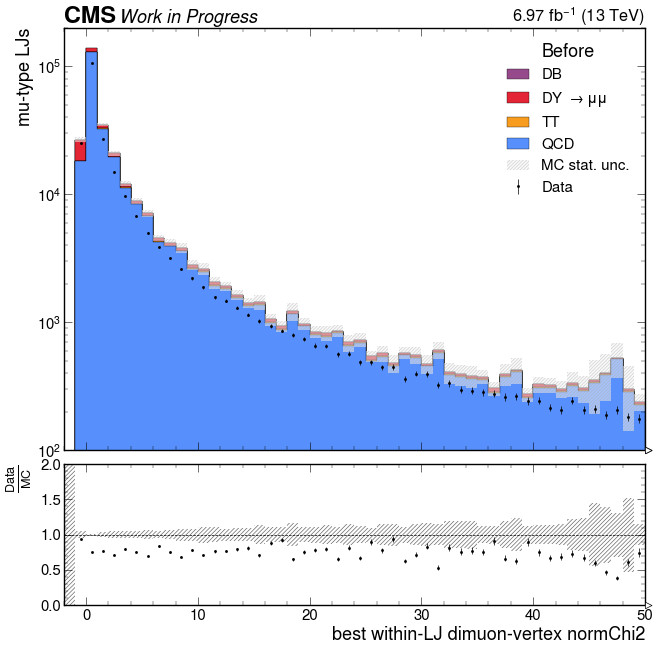

In [5]:
plot_DataMC_channels("mu_lj_vtx_chi2", channels[:1],
                     xlabel="best within-LJ dimuon-vertex normChi2",
                     ylabel="mu-type LJs")

**How to read Figure 2:** the same distribution on a logarithmic normChi2 axis, with the -1
sentinel bin and the near-zero bin dropped so that the axis can be logarithmic; the three
dashed red lines are the candidate thresholds 2, 5 and 10. The no-vertex fractions that the
plot cannot show are printed underneath.

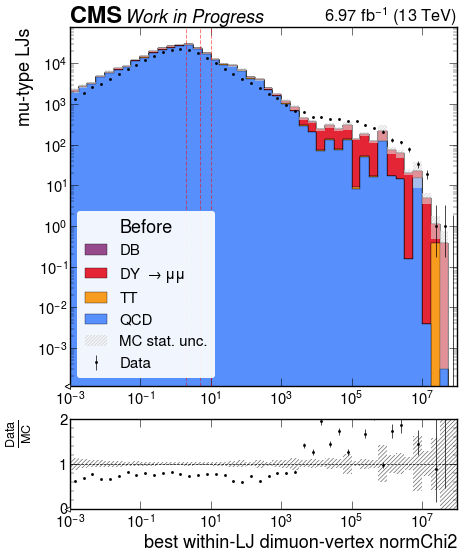

Before channel, mu-type LJs: data 248594, MC 322813
  no-vertex (-1) fraction:  data 0.101   MC 0.083
  0 <= vtx_chi2 < 5 (pass): data 0.676   MC 0.688
  (four histogram bins per decade, so this '5' is really 5.62; the cut in the vtxChi2 channels is a true < 5)


In [6]:
def plot_vtx_log(channel_name, label):
    sl = slice(2, None)  # drop the -1 sentinel bin and the [-0.5, 1e-3) bin for the log display
    fig, ax_main, ax_comp = hep.comp.data_model(
        data_hist=sum_data_all["mu_lj_vtx_chi2_log"][channel_name, sl],
        stacked_components=[ratio * s["mu_lj_vtx_chi2_log"][channel_name, sl]
                            for s in summed_MC],
        stacked_labels=MC_LABELS,
        xlabel="best within-LJ dimuon-vertex normChi2",
        ylabel="mu-type LJs",
        data_w2method="poisson",
    )
    hep.cms.label(data=True, lumi=LUMI_DATA, text="Work in Progress", ax=ax_main)
    ax_main.set_xscale("log")
    ax_main.set_yscale("log")
    ax_comp.set_xscale("log")
    for t in (2, 5, 10):
        ax_main.axvline(t, color="red", linestyle="--", alpha=0.5)
    ax_main.legend(title=label, loc="lower left", frameon=True, facecolor="white",
                   edgecolor="none", framealpha=0.92)
    plt.show()
    plt.close()


plot_vtx_log(CR_BEFORE, "Before")

v_data_cr = vtx_log(sum_data_all, CR_BEFORE)
v_mc_cr   = sum(vtx_log(s, CR_BEFORE, ratio) for s in summed_MC)
print(f"Before channel, mu-type LJs: data {v_data_cr.sum():.0f}, MC {v_mc_cr.sum():.0f}")
print(f"  no-vertex (-1) fraction:  data {v_data_cr[1]/v_data_cr.sum():.3f}"
      f"   MC {v_mc_cr[1]/v_mc_cr.sum():.3f}")
print(f"  0 <= vtx_chi2 < 5 (pass): data {kept(v_data_cr, 5)/v_data_cr.sum():.3f}"
      f"   MC {kept(v_mc_cr, 5)/v_mc_cr.sum():.3f}")
print(f"  (four histogram bins per decade, so this '5' is really {edge_for(5):.2f}; the cut "
      f"in the vtxChi2 channels is a true < 5)")

### 2b. Cosmic-enriched region

The **spread-inverted cosmic region** (`cosmic_muons`) is the region the Spread veto was
designed against. The Spread cuts (`inverse_spread`) and the cosAlpha event cut are both
inverted, so it selects back-to-back muon pairs with a large spread in impact parameters. It is
*not* the vertex-inverted cosmic region of sections 5 to 7, which is a different selection. It
contains no `vtx_chi2` requirement at all. That makes it a test of the vertex variable rather
than a tautology: the variable is asked to flag objects that were selected with entirely
different quantities.

**How to read Figure 3:** mu-type LJs per bin of `vtx_chi2` in the spread-inverted cosmic
region, on a logarithmic axis with the -1 no-vertex and near-zero bins dropped. The fractions
printed underneath do include the no-vertex bin, which holds almost all of the region.

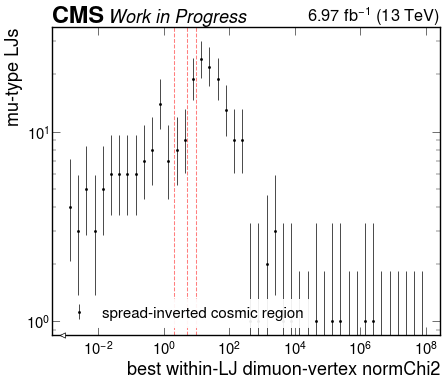

spread-inverted cosmic region (cosmic_muons): 4994 mu-type LJs
  no-vertex (-1) fraction:    0.955
  0 <= vtx_chi2 < 5 (passes): 0.020
  fails 0 <= vtx_chi2 < 5:    0.980
  the same three numbers in the Before channel (data): 0.101 / 0.676 / 0.324


In [7]:
cos_file = f"{sidm_path}/RunOutputFiles/vtxCosmic_2018C/DoubleMuon_2018C.coffea"
H_cos    = coffea.util.load(cos_file)["out"]["DoubleMuon_2018C"]["hists"]
CH_COS   = "cosmic_muons"
assert np.allclose(H_cos["mu_lj_vtx_chi2_log"][CH_COS, :].axes[0].edges, LOG_EDGES)

fig, ax = plt.subplots(figsize=(10, 8))
hep.histplot(H_cos["mu_lj_vtx_chi2_log"][CH_COS, 2:], ax=ax, histtype="errorbar", color="k",
             label="spread-inverted cosmic region")
for t in (2, 5, 10):
    ax.axvline(t, color="red", linestyle="--", alpha=0.5)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("best within-LJ dimuon-vertex normChi2")
ax.set_ylabel("mu-type LJs")
ax.legend(loc="lower left", frameon=True, facecolor="white", edgecolor="none",
          framealpha=0.92)
hep.cms.label(data=True, lumi=LUMI_DATA, text="Work in Progress", ax=ax)
plt.show()
plt.close()

v_cos = H_cos["mu_lj_vtx_chi2_log"][CH_COS, :].values(flow=True)
t_cos = v_cos.sum()
print(f"spread-inverted cosmic region ({CH_COS}): {t_cos:.0f} mu-type LJs")
print(f"  no-vertex (-1) fraction:    {v_cos[1]/t_cos:.3f}")
print(f"  0 <= vtx_chi2 < 5 (passes): {kept(v_cos, 5)/t_cos:.3f}")
print(f"  fails 0 <= vtx_chi2 < 5:    {1 - kept(v_cos, 5)/t_cos:.3f}")
print(f"  the same three numbers in the Before channel (data): "
      f"{v_data_cr[1]/v_data_cr.sum():.3f} / {kept(v_data_cr, 5)/v_data_cr.sum():.3f} / "
      f"{1 - kept(v_data_cr, 5)/v_data_cr.sum():.3f}")

The Spread variables of the same region are shown next, as a cross-check of what the region
contains. They are large by construction, since `inverse_spread` is one of the cuts that define
the region. The point of the comparison is that `vtx_chi2`, which is used nowhere in that
definition, flags the same objects independently.

The fractions printed below the figure differ between the variables, because `inverse_spread`
as run is not the exact complement of the four keep-cuts of the Spread channel. It is the OR of
`vzSpread_pf > 10`, `vxySpread_pf > 10` and `vxySpread_mu > 50`, the last term written twice
(kept in `cuts.py` as `inverse_spread (vz/vxy, as run)`, see "Selections used in this study").
In particular it never requires `dzSpread_mu` itself to be large.

**How to read Figure 4:** mu-type LJs per bin of two of the Spread variables in the
spread-inverted cosmic region: the muon longitudinal impact-parameter spread `dzSpread_mu`
(left) and the muon transverse vertex-position spread `vxySpread_mu` (right). The Spread channel
cuts on both at 50 cm, where the dashed line sits. `dxySpread_mu`, the variable of the `_dxy`
channel variant, is printed underneath rather than plotted, since the two channel variants
agree to one part in 4 x 10^4.

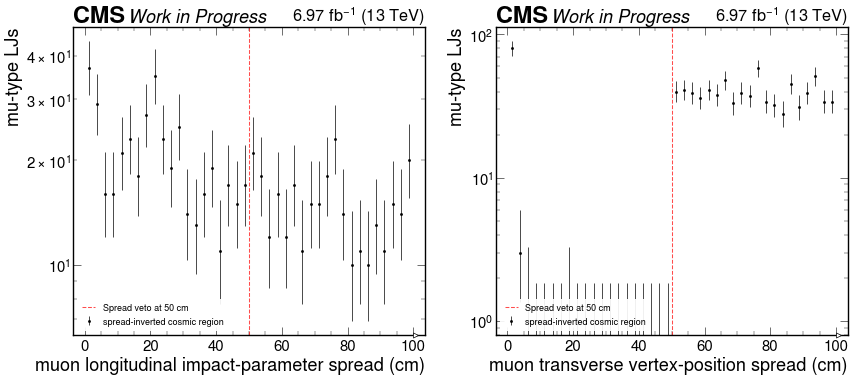

  mu_lj_dzSpread_mu      fraction above 50 cm: 0.419
  mu_lj_dxySpread_mu     fraction above 50 cm: 0.889
  mu_lj_vxySpread_mu     fraction above 50 cm: 0.902


In [8]:
SPREAD_LABEL = {"mu_lj_dzSpread_mu":  "muon longitudinal impact-parameter spread",
                "mu_lj_vxySpread_mu": "muon transverse vertex-position spread",
                "mu_lj_dxySpread_mu": "muon transverse impact-parameter spread"}

# Both panels show a variable the Spread channel actually cuts on at 50 cm: dzSpread_mu and
# vxySpread_mu. dxySpread_mu, the variable of the `_dxy` channel variant, is printed below
# rather than plotted, since the two channels differ by 1 part in 4 x 10^4.
fig, axs = plt.subplots(1, 2, figsize=(20, 8))
for ax, name, cut in ((axs[0], "mu_lj_dzSpread_mu", 50), (axs[1], "mu_lj_vxySpread_mu", 50)):
    hep.histplot(H_cos[name][CH_COS, ::5j], ax=ax, histtype="errorbar", color="k",
                 label="spread-inverted cosmic region")
    ax.axvline(cut, color="red", linestyle="--", alpha=0.7, label=f"Spread veto at {cut} cm")
    ax.set_yscale("log")
    ax.set_xlabel(f"{SPREAD_LABEL[name]} (cm)")
    ax.set_ylabel("mu-type LJs")
    ax.legend(fontsize=13, loc="lower left", frameon=True, facecolor="white",
              edgecolor="none", framealpha=0.92)
    hep.cms.label(data=True, lumi=LUMI_DATA, text="Work in Progress", ax=ax)
plt.show()
plt.close()

for name in ("mu_lj_dzSpread_mu", "mu_lj_dxySpread_mu", "mu_lj_vxySpread_mu"):
    h = H_cos[name][CH_COS, :]
    v, e = h.values(flow=True)[1:-1], h.axes[0].edges[:-1]
    print(f"  {name:22s} fraction above 50 cm: {v[e >= 50].sum()/v.sum():.3f}")

### 2c. Signal

The same per-LJ distribution for the v10 signal samples, in the
`base_ljDisplacementIso_cosAlpha` channel. The cell below makes one pass over the whole grid and
keeps only the per-sample numbers the rest of the notebook needs: the summed lepton-jet and
DSA-muon yields in the four signal channels, the `mu_lj_vtx_chi2_log` profile, the effective
sample size, and the survival of a `sigma(pT)/pT < 0.3` cut. Two counting units are defined here
and used from now on:

- **per LJ**: the summed `mu_lj_pt` yield, one entry per mu-type lepton jet;
- **per DSA muon**: the summed `mu_lj_dsaMuon_pt_relPtErr` yield, one entry per DSA muon
  inside a mu-type lepton jet.

The two are not interchangeable and are never mixed inside one comparison, because a lepton
jet can hold several DSA muons and the vetoes act on the jet.

Signal yields are cross-section weighted, so a sample's statistical weight is its effective
entry count `N_eff = (sum w)^2 / sum w^2`, not its file count. Samples with `N_eff < 200` can
give efficiencies of exactly 1.000 from a handful of entries. The aggregates below are therefore
quoted both over all 180 samples and over the **robust subset**, the samples with
`N_eff >= 200`.

**How to read Figure 5:** shape comparison only. Each curve is the fraction of that sample's
mu-type LJs per bin, normalized over the plotted logarithmic bins alone, so the -1 no-vertex bin
is excluded from the normalization and printed separately underneath. Signal curves at lower
normChi2 than the background curve would mean the variable separates signal from background;
overlapping curves mean it does not.

In [9]:
SIG_DIR    = f"{sidm_path}/RunOutputFiles/vtxChi2_signal_2018"
SIG_BASE   = "base_ljDisplacementIso"
SIG_REF    = "base_ljDisplacementIso_cosAlpha"
SIG_SPREAD = "base_ljDisplacementIso_cosAlpha_ljSpread"
SIG_VTX    = "base_ljDisplacementIso_cosAlpha_vtxChi2"
SIG_CHANNELS = [(SIG_BASE, "base"), (SIG_REF, "+ cosAlpha"),
                (SIG_SPREAD, "+ Spread veto"), (SIG_VTX, "+ vertex-fit veto")]
RELPT_CUT = 0.3
NEFF_MIN  = 200

sig_files = sorted(glob.glob(f"{SIG_DIR}/*.coffea"))
sig_names = [os.path.basename(f)[:-len(".coffea")] for f in sig_files]


def parse_sample(name):
    # 4Mu_100GeV_1p2GeV_9p6mm -> ("4Mu", 100.0, 1.2, 9.6); "p" is the decimal point
    fs, m, ma, ct = name.split("_")
    num = lambda s: float(s.replace("GeV", "").replace("mm", "").replace("p", "."))
    return fs, num(m), num(ma), num(ct)


sig_info = {n: parse_sample(n) for n in sig_names}

sig_rows, sig_vtxlog = [], {}
for f, n in zip(sig_files, sig_names):
    H = coffea.util.load(f)["out"][n]["hists"]
    hrp = H["mu_lj_dsaMuon_pt_relPtErr"]
    href = hrp[{"channel": SIG_REF}]
    v, var = href.values(flow=True), href.variances(flow=True)
    ye = href.axes[1].edges
    good = np.concatenate(([False], ye[:-1] < RELPT_CUT, [False]))   # y-flow-aware mask
    dsa = {ch: float(hrp[{"channel": ch}].values(flow=True).sum())
           for ch, _ in SIG_CHANNELS}
    lj = {ch: float(H["mu_lj_pt"][{"channel": ch}].values(flow=True).sum())
          for ch, _ in SIG_CHANNELS}
    sig_vtxlog[n] = H["mu_lj_vtx_chi2_log"][{"channel": SIG_REF}].values(flow=True)
    fs, m, ma, ct = sig_info[n]
    sig_rows.append(dict(
        name=n, fs=fs, m=m, ma=ma, ct=ct,
        neff=float(v.sum() ** 2 / var.sum()),
        dsa_ref=dsa[SIG_REF], lj_ref=lj[SIG_REF],
        dsa_sp=dsa[SIG_SPREAD] / dsa[SIG_REF], dsa_vt=dsa[SIG_VTX] / dsa[SIG_REF],
        lj_sp=lj[SIG_SPREAD] / lj[SIG_REF], lj_vt=lj[SIG_VTX] / lj[SIG_REF],
        surv=float(v[:, good].sum() / v.sum()),
        surv_and=float(hrp[{"channel": SIG_SPREAD}].values(flow=True)[:, good].sum()
                       / v.sum()),
    ))

SKEYS = ("m", "ma", "ct", "neff", "dsa_ref", "lj_ref", "dsa_sp", "dsa_vt",
         "lj_sp", "lj_vt", "surv", "surv_and")
S      = {k: np.array([r[k] for r in sig_rows], float) for k in SKEYS}
SNAME  = np.array([r["name"] for r in sig_rows])
SFS    = np.array([r["fs"] for r in sig_rows])
robust = S["neff"] >= NEFF_MIN
WSIG   = S["dsa_ref"]

print(f"{len(sig_names)} signal samples in {os.path.basename(SIG_DIR)}")
print(f"  final states     : "
      + ", ".join(f"{u} {int((SFS == u).sum())}" for u in sorted(set(SFS.tolist()))))
print(f"  mediator masses  : {sorted(set(S['m'].tolist()))}")
print(f"  dark-photon mass : {sorted(set(S['ma'].tolist()))}")
print(f"  ctau values      : {len(set(S['ct'].tolist()))} spanning "
      f"{S['ct'].min():g} - {S['ct'].max():g} mm")
print(f"  N_eff percentiles 0/5/50/95/100: "
      + " ".join(f"{x:.0f}" for x in np.percentile(S["neff"], [0, 5, 50, 95, 100])))
print(f"  samples with N_eff < {NEFF_MIN} (efficiencies there are noise): "
      f"{int((~robust).sum())} of {len(sig_names)}")

180 signal samples in vtxChi2_signal_2018
  final states     : 2Mu2E 90, 4Mu 90
  mediator masses  : [100.0, 150.0, 200.0, 500.0, 800.0, 1000.0]
  dark-photon mass : [0.25, 1.2, 5.0]
  ctau values      : 64 spanning 0.002 - 400 mm
  N_eff percentiles 0/5/50/95/100: 3 61 7487 94197 163055
  samples with N_eff < 200 (efficiencies there are noise): 18 of 180


benchmarks used in the shape overlay: ['2Mu2E_100GeV_0p25GeV_20p0mm', '2Mu2E_800GeV_0p25GeV_2p5mm', '4Mu_150GeV_5p0GeV_270p0mm', '4Mu_1000GeV_5p0GeV_40p0mm']


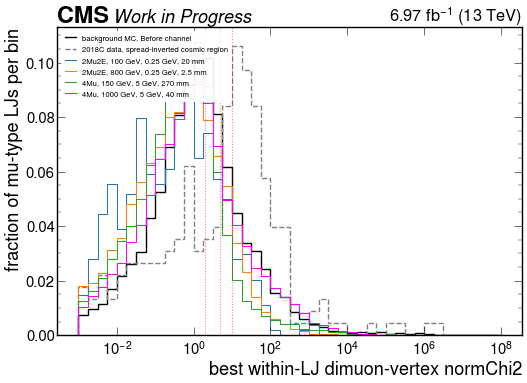

no-vertex (-1) fraction, excluded from the normalization above:
  background MC, Before channel                  0.083
  2018C data, spread-inverted cosmic region      0.955
  2Mu2E, 100 GeV, 0.25 GeV, 20 mm                0.200
  2Mu2E, 800 GeV, 0.25 GeV, 2.5 mm               0.423
  4Mu, 150 GeV, 5 GeV, 270 mm                    0.080
  4Mu, 1000 GeV, 5 GeV, 40 mm                    0.130


In [10]:
def shape(vals):
    # fraction per bin over the 44 logarithmic bins (flow indices 3 .. -2)
    log_bins = vals[3:-1]
    return log_bins / log_bins.sum() if log_bins.sum() > 0 else log_bins


log_edges_plot = LOG_EDGES[2:]   # the edges of the 44 logarithmic bins

# four benchmarks spanning the grid: the longest lifetime of four evenly spaced
# (final state, mediator mass, dark-photon mass) families, that being where the muons are
# most displaced and the vertex fit is most stressed
families = {}
for n in sig_names:
    fs, m, ma, ct = sig_info[n]
    families.setdefault((fs, m, ma), []).append(n)
for k in families:
    families[k].sort(key=lambda n: sig_info[n][3])
fam_keys = sorted(families)
idx = np.linspace(0, len(fam_keys) - 1, 4).round().astype(int)
benchmarks = [families[fam_keys[i]][-1] for i in dict.fromkeys(idx.tolist())]
print("benchmarks used in the shape overlay:", benchmarks)

fig, ax = plt.subplots(figsize=(12, 8))
hep.histplot(shape(v_mc_cr), log_edges_plot, ax=ax, histtype="step", linewidth=2,
             color="k", label="background MC, Before channel")
hep.histplot(shape(v_cos), log_edges_plot, ax=ax, histtype="step", linewidth=2,
             color="grey", linestyle="--", label="2018C data, spread-inverted cosmic region")
no_vtx = {"background MC, Before channel": v_mc_cr[1]/v_mc_cr.sum(),
          "2018C data, spread-inverted cosmic region": v_cos[1]/v_cos.sum()}
for n, sc in zip(benchmarks, ["tab:blue", "tab:orange", "tab:green", "magenta"]):
    v = sig_vtxlog[n]
    fs, m, ma, ct = sig_info[n]
    lab = f"{fs}, {m:.0f} GeV, {ma:g} GeV, {ct:g} mm"
    hep.histplot(shape(v), log_edges_plot, ax=ax, histtype="step", color=sc, label=lab)
    no_vtx[lab] = v[1]/v.sum()
for t in (2, 5, 10):
    ax.axvline(t, color="red", linestyle=":", alpha=0.5)
ax.set_xscale("log")
ax.set_xlabel("best within-LJ dimuon-vertex normChi2")
ax.set_ylabel("fraction of mu-type LJs per bin")
ax.legend(fontsize=11, loc="upper left", frameon=True, facecolor="white", edgecolor="none",
          framealpha=0.92)
hep.cms.label(data=True, lumi=LUMI_DATA, text="Work in Progress", ax=ax)
plt.show()
plt.close()

print("no-vertex (-1) fraction, excluded from the normalization above:")
for k, v in no_vtx.items():
    print(f"  {k:46s} {v:.3f}")

## 3. Control-region comparison against the Spread veto

The four panels below compare data with MC in the pT of the DSA muons inside mu-type LJs,
which is where the residual excess at high pT sits. The first two panels are the existing
before/after pair for the Spread veto. The third replaces the four Spread cuts by
`0 <= vtx_chi2 < 5`. The fourth also drops the cosAlpha event cut, to show how much of the
back-to-back rejection the vertex requirement provides on its own.

**How to read Figure 6:** four data/MC panels on common axes, log scale. MC is stacked by
process and scaled by 6.97/59.83, the 2018C share of the 2018 integrated luminosity. The lower
sub-panel of each is the data/MC ratio; the question is whether that ratio above 200 GeV comes
closer to unity.

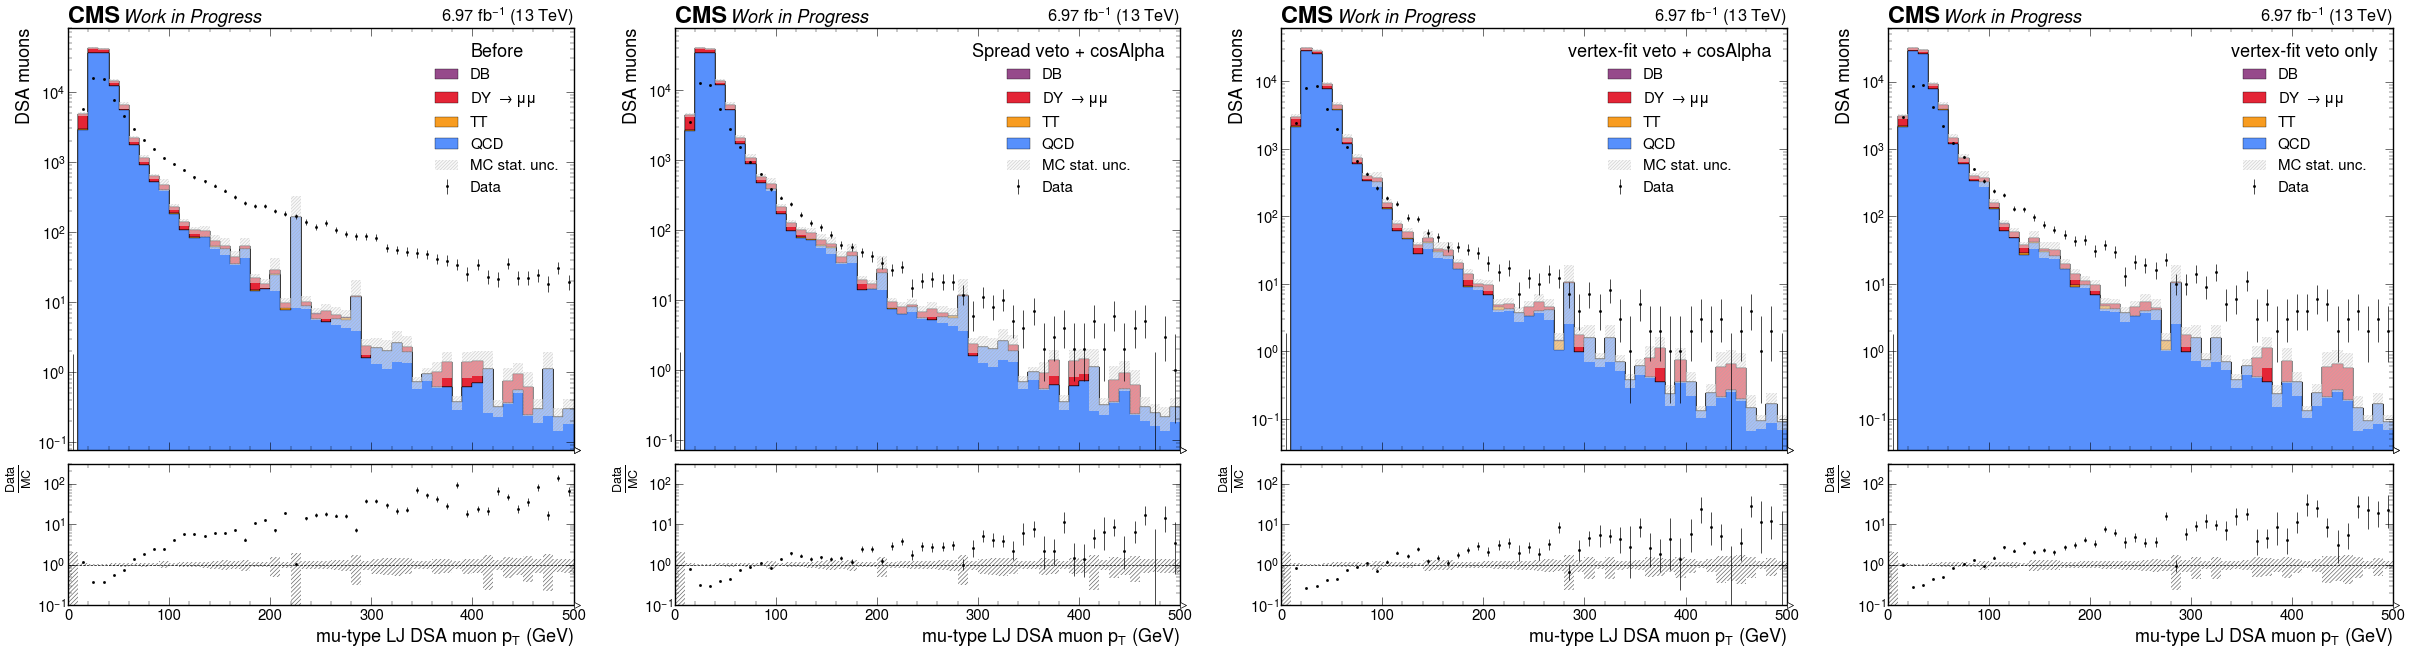

In [11]:
plot_DataMC_channels("mu_lj_dsaMuon_pt", channels, binning=2j,
                     xlabel=r"mu-type LJ DSA muon $p_{T}$ (GeV)",
                     ylabel="DSA muons", ratio_ylim=(0.1, 300))

Yields from the same histogram, overall and above 200 GeV, followed by the MC composition of
the high-pT region.

In [12]:
hname = "mu_lj_dsaMuon_pt"


def tot(summed, channel_name, lo=None, scale=1.0):
    h1 = summed[hname][channel_name, :]
    vals = scale * h1.values(flow=True)
    if lo is None:
        return vals.sum()
    i = np.searchsorted(h1.axes[0].edges, lo) + 1  # +1: index 0 of flow=True is the underflow
    return vals[i:].sum()


print(f"{'channel':28s} {'data':>9s} {'MC':>11s} {'data/MC':>8s} | "
      f"{'data>200':>9s} {'MC>200':>9s} {'d/MC>200':>9s}")
for channel_name, label in channels:
    d     = tot(sum_data_all, channel_name)
    d200  = tot(sum_data_all, channel_name, 200)
    mc    = sum(tot(s, channel_name, scale=ratio)      for s in summed_MC)
    mc200 = sum(tot(s, channel_name, 200, scale=ratio) for s in summed_MC)
    print(f"{label:28s} {d:9.0f} {mc:11.1f} {d/mc:8.2f} | "
          f"{d200:9.0f} {mc200:9.1f} {d200/mc200:9.2f}")

print("\nMC composition above 200 GeV in the Before channel (scaled to 6.97/fb), top 5:")
comp = [(s, tot(utilities.sum_hist([s], dir_name), CR_BEFORE, 200, scale=ratio))
        for s in QCD + TT + DY + DB]
for s, y in sorted(comp, key=lambda r: -r[1])[:5]:
    print(f"  {s:22s} {y:8.1f}")

# The control region is not normalized. Quote the mismatch in both counting units, because
# the two are not the same number and their ratio is the thing that is actually mismodelled.
lj_d, lj_m = v_data_cr.sum(), v_mc_cr.sum()
ds_d = tot(sum_data_all, CR_BEFORE)
ds_m = sum(tot(s, CR_BEFORE, scale=ratio) for s in summed_MC)
print("\nControl-region normalization, Before channel (no scale factor is applied anywhere):")
print(f"  mu-type LJs               : data {lj_d:8.0f}   MC {lj_m:9.1f}   "
      f"data/MC {lj_d/lj_m:.3f}")
print(f"  DSA muons inside them     : data {ds_d:8.0f}   MC {ds_m:9.1f}   "
      f"data/MC {ds_d/ds_m:.3f}")
print(f"  DSA muons per mu-type LJ  : data {ds_d/lj_d:8.3f}   MC {ds_m/lj_m:9.3f}   "
      f"-> MC carries {100*((ds_m/lj_m)/(ds_d/lj_d) - 1):.0f}% more")

channel                           data          MC  data/MC |  data>200    MC>200  d/MC>200
Before                           63040    113357.3     0.56 |      2414     293.6      8.22
Spread veto + cosAlpha           40881    108137.7     0.38 |       309     133.7      2.31
vertex-fit veto + cosAlpha       28303     80040.4     0.35 |       187      78.4      2.38
vertex-fit veto only             30985     80649.5     0.38 |       367      78.8      4.66

MC composition above 200 GeV in the Before channel (scaled to 6.97/fb), top 5:


  QCD_Pt30To50              155.7
  QCD_Pt170To300             29.9
  QCD_Pt300To470             27.6
  QCD_Pt80To120              27.6
  DYJetsToLL_M50             16.6

Control-region normalization, Before channel (no scale factor is applied anywhere):
  mu-type LJs               : data   248594   MC  322813.4   data/MC 0.770
  DSA muons inside them     : data    63040   MC  113357.3   data/MC 0.556
  DSA muons per mu-type LJ  : data    0.254   MC     0.351   -> MC carries 38% more


### 3.1 The control region is not normalized, and what that does and does not affect

The yields above are not close to each other, and the mismatch is not one number. In the
Before channel the region holds 0.770 data mu-type lepton jets per MC one, but only 0.556 data
DSA muons per MC one (63040 against 113357.3). These are not the same discrepancy seen twice.
Their ratio is the DSA-muon *multiplicity*: MC carries 0.351 DSA muons per mu-type lepton jet
against 0.254 in data, 38% more. The dominant effect is therefore not an overall cross-section
normalization, which would move both numbers together. It is that simulation puts more
reconstructed DSA muons inside a mu-type lepton jet than data does. No scale factor is applied
anywhere in this study, and none is derived here.

What the mismatch does and does not affect:

- **Not the veto comparison.** Every efficiency in sections 3 and 4 is a ratio of one channel
  to another *within* data or *within* MC, so a common normalization cancels.
- **Not the cosmic conclusions of section 7.** The azimuthal test is a ratio of two bins of the
  same data distribution.
- **It inflates every absolute data/MC ratio quoted for the tail**, including the
  2.4 +/- 0.4 residual (eight-sample tail set), by whatever part of the 38% multiplicity
  mismodelling survives to `pT >= 200` GeV. That part is not measured here, so the tail data/MC
  is reported but is not the load-bearing number.
- **The tail conclusions are therefore stated as rates wherever possible**: tail entries divided
  by all entries of the same channel and the same collection. A rate divides the mismatch out of
  numerator and denominator alike. The closure test of section 8 takes exactly this form, which
  is why that test, rather than the raw 2.4, carries the argument.

### 3.2 Scanning the vertex-fit threshold

The code does not fix the threshold of the vertex cut, so the next cell scans it. For each
candidate value it reports the fraction of Before-channel mu-type LJs kept in data and in MC,
and the data/MC ratio of what survives. A variable with separating power would drive that ratio
away from its no-cut value as the cut tightens.

**How to read Figure 7:** left panel, the fraction of Before-channel mu-type LJs kept by
`0 <= vtx_chi2 < threshold` in data and in scaled MC, against the threshold on a logarithmic
axis. Right panel, the data/MC ratio of the surviving lepton jets with its statistical
uncertainty (data Poisson plus weighted MC), zoomed to 0.70-0.80, with the dashed line at the
ratio with no cut applied. A flat line means the cut removes data and MC in the same proportion
at every threshold. Two points to keep in mind. The abscissa is the bin edge *actually* used,
not the requested value: the histogram has four bins per decade, so a requested 5 is 5.62 and a
requested 2 is 3.16. And the nine points are nested selections of one sample, so they are
strongly correlated, not nine independent measurements.

 requested  edge used  data kept   MC kept      data/MC of kept
         2       3.16      0.605     0.616         0.756 +/- 0.010
         5       5.62      0.676     0.688         0.757 +/- 0.009
        10      10.00      0.731     0.743         0.757 +/- 0.009
        30      31.62      0.801     0.814         0.758 +/- 0.008
       100     100.00      0.839     0.863         0.749 +/- 0.008
       300     316.23      0.863     0.889         0.747 +/- 0.008
      1000    1000.00      0.875     0.902         0.747 +/- 0.008
      3000    3162.28      0.882     0.909         0.747 +/- 0.008
     10000   10000.00      0.886     0.911         0.749 +/- 0.008

Before-channel totals: data 248594, MC 322813, data/MC with no cut 0.770
The nine points are nested selections of the same sample and so are strongly
correlated; the error bars are per-point and are not nine independent measurements.


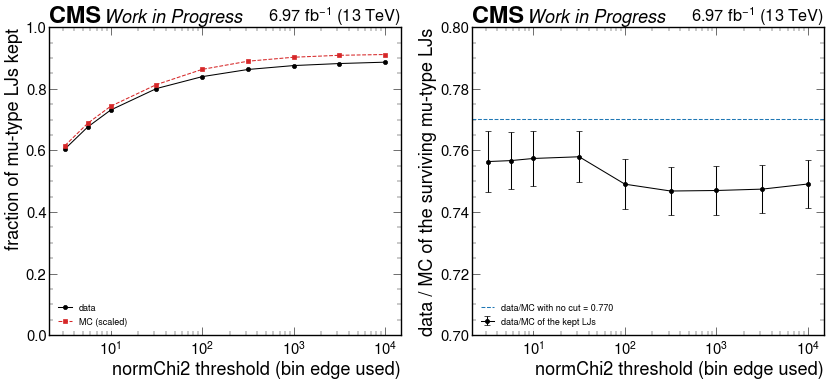

In [13]:
thresholds = np.array([2, 5, 10, 30, 100, 300, 1000, 3000, 10000], dtype=float)
edges_used = np.array([edge_for(t) for t in thresholds])
tot_d, tot_m = v_data_cr.sum(), v_mc_cr.sum()
var_mc_cr = sum(vtx_log_var(s, CR_BEFORE, ratio) for s in summed_MC)
n_kept_d = np.array([kept(v_data_cr, t) for t in thresholds])
n_kept_m = np.array([kept(v_mc_cr, t) for t in thresholds])
n_kept_mv = np.array([kept(var_mc_cr, t) for t in thresholds])
kf_d, kf_m = n_kept_d / tot_d, n_kept_m / tot_m
dmc_kept = n_kept_d / n_kept_m
e_dmc = dmc_kept * np.sqrt(1 / n_kept_d + n_kept_mv / n_kept_m ** 2)

print(f"{'requested':>10s} {'edge used':>10s} {'data kept':>10s} {'MC kept':>9s} "
      f"{'data/MC of kept':>20s}")
for t, ee, a, b, r, er in zip(thresholds, edges_used, kf_d, kf_m, dmc_kept, e_dmc):
    print(f"{t:10.0f} {ee:10.2f} {a:10.3f} {b:9.3f} {r:13.3f} +/-{er:6.3f}")
print(f"\nBefore-channel totals: data {tot_d:.0f}, MC {tot_m:.0f}, "
      f"data/MC with no cut {tot_d/tot_m:.3f}")
print("The nine points are nested selections of the same sample and so are strongly")
print("correlated; the error bars are per-point and are not nine independent measurements.")

fig, axs = plt.subplots(1, 2, figsize=(20, 8))
axs[0].plot(edges_used, kf_d, "o-", color="k", label="data")
axs[0].plot(edges_used, kf_m, "s--", color="tab:red", label="MC (scaled)")
axs[0].set_ylabel("fraction of mu-type LJs kept")
axs[0].set_ylim(0, 1)
axs[1].errorbar(edges_used, dmc_kept, yerr=e_dmc, fmt="o-", color="k", capsize=4,
                label="data/MC of the kept LJs")
axs[1].axhline(tot_d/tot_m, color="tab:blue", linestyle="--",
               label=f"data/MC with no cut = {tot_d/tot_m:.3f}")
axs[1].set_ylabel("data / MC of the surviving mu-type LJs")
axs[1].set_ylim(0.70, 0.80)
for ax in axs:
    ax.set_xscale("log")
    ax.set_xlabel("normChi2 threshold (bin edge used)")
    ax.legend(fontsize=13, loc="lower left", frameon=True, facecolor="white",
              edgecolor="none", framealpha=0.92)
    hep.cms.label(data=True, lumi=LUMI_DATA, text="Work in Progress", ax=ax)
plt.show()
plt.close()

The vertex veto is the tighter cut. On its own it keeps 49% of the Before-channel DSA-muon
entries, against 65% for the four Spread cuts with the cosAlpha event cut. At the scan's "5" it
keeps 68% of the control region's mu-type LJs; the threshold sits on the peak of the
distribution. (The scan's "5" is the bin edge at 5.62: the histogram carries four bins per
decade, and a requested threshold snaps up to the nearest edge. The selection itself cuts at a
true `vtx_chi2 < 5`; only this scan snaps, and the two differ by well under a bin.)

It is not, however, the better discriminant. Above 200 GeV it leaves 187 data against 78 MC
entries, a ratio of 2.38, against 309 / 134 and a ratio of 2.31 for the Spread veto, both on the
**full background stack**: the same residual within its uncertainty, on a smaller sample. (The
eight-sample tail set introduced in section 5 gives 2.385 +/- 0.426 for the Spread veto,
consistent with the 2.31 here; section 5 shows why the two MC sets differ before the veto and
agree after it.) The data/MC ratio of the surviving mu-type LJs is flat at 0.75 across the whole
scanned range, against 0.77 with no cut at all. The nine scan points are nested and therefore
correlated, but their spread is far smaller than the step down from 0.77. The variable thus
removes data and MC in the same proportion everywhere, and the no-vertex fractions differ only
slightly (10.1% in data against 8.3% in MC). The residual high-pT excess is therefore not a
population of muon pairs with bad or missing common vertices.

What does help is the cosAlpha event cut. The last two panels differ only by that cut. It takes
the data above 200 GeV from 367 to 187, while the MC there goes from 79 to 78: it removes
back-to-back pairs that the MC does not have, as expected of a cosmic veto. The MC above
200 GeV is dominated by a handful of high-weight `QCD_Pt30To50` events, so its uncertainty there
is much larger than the statistical error bars suggest.

## 4. Signal efficiency over the full 180-sample grid

The cost of the two vetoes on signal. In all three signal channels the veto is a post-LJ
object cut, so it removes lepton jets and not events: the event-level cutflow is identical
across `base_ljDisplacementIso_cosAlpha`, `..._ljSpread` and `..._vtxChi2`, and the meaningful
efficiency is the ratio of object yields with `base_ljDisplacementIso_cosAlpha` as the
reference. Both counting units of section 2c are reported; **they are never compared with each
other**, only within a unit. The Spread veto on signal is the as-run `vxySpread` form
(`base_ljDisplacementIso_cosAlpha_ljSpread`); `main`'s `dxySpread` form was not run on signal, so
every signal efficiency here is for the `vxySpread` form.

The grid is complete: 180 samples (90 4Mu, 90 2Mu2E), six mediator masses, three dark-photon
masses and 64 distinct proper decay lengths.

In [14]:
def agg(key, mask=None):
    x = S[key] if mask is None else S[key][mask]
    w = WSIG if mask is None else WSIG[mask]
    return dict(n=x.size, mean=x.mean(), median=np.median(x), lo=x.min(), hi=x.max(),
                wmean=(x * w).sum() / w.sum())


def line(d):
    return (f"n={d['n']:3d}  mean {d['mean']:.4f}  median {d['median']:.4f}  "
            f"[{d['lo']:.3f}, {d['hi']:.3f}]  yield-wtd {d['wmean']:.4f}")


print("Veto efficiency relative to the '+ cosAlpha' reference channel.")
print("'yield-wtd' weights each sample by its DSA-muon yield in that reference channel.\n")
for key, lab in (("lj_sp", "Spread veto,     per LJ      "),
                 ("lj_vt", "vtx_chi2 < 5,    per LJ      "),
                 ("dsa_sp", "Spread veto,     per DSA muon"),
                 ("dsa_vt", "vtx_chi2 < 5,    per DSA muon")):
    print(f"{lab}  all 180   : {line(agg(key))}")
    print(f"{' ' * len(lab)}  N_eff>=200: {line(agg(key, robust))}")

print("\nPooling the objects themselves over the whole grid (sum over samples of the "
      "numerator\ndivided by sum of the denominator), per LJ:")
print(f"  Spread veto   {(S['lj_sp'] * S['lj_ref']).sum() / S['lj_ref'].sum():.4f}")
print(f"  vtx_chi2 < 5  {(S['lj_vt'] * S['lj_ref']).sum() / S['lj_ref'].sum():.4f}")

print(f"\nThe vertex veto is the more costly of the two on "
      f"{int((S['lj_vt'] < S['lj_sp']).sum())} of {len(sig_names)} samples per LJ, and on "
      f"{int((S['dsa_vt'] < S['dsa_sp']).sum())} of {len(sig_names)} per DSA muon.")

Veto efficiency relative to the '+ cosAlpha' reference channel.
'yield-wtd' weights each sample by its DSA-muon yield in that reference channel.

Spread veto,     per LJ        all 180   : n=180  mean 0.9634  median 0.9765  [0.670, 1.000]  yield-wtd 0.9520
                               N_eff>=200: n=162  mean 0.9608  median 0.9759  [0.670, 0.993]  yield-wtd 0.9520
vtx_chi2 < 5,    per LJ        all 180   : n=180  mean 0.7060  median 0.7099  [0.484, 0.917]  yield-wtd 0.6402
                               N_eff>=200: n=162  mean 0.6897  median 0.6957  [0.484, 0.903]  yield-wtd 0.6401
Spread veto,     per DSA muon  all 180   : n=180  mean 0.9498  median 0.9701  [0.635, 1.000]  yield-wtd 0.9505
                               N_eff>=200: n=162  mean 0.9495  median 0.9700  [0.635, 0.986]  yield-wtd 0.9505
vtx_chi2 < 5,    per DSA muon  all 180   : n=180  mean 0.6218  median 0.6251  [0.399, 1.000]  yield-wtd 0.5959
                               N_eff>=200: n=162  mean 0.6075  median 0.5923 

The two vetoes are far apart on signal. Per lepton jet the Spread veto keeps 0.961 of the
reference channel's yield, averaged over the 162 robust points (0.952 weighting each sample by
its DSA-muon yield), against 0.690 for the vertex veto (0.640 yield-weighted). The vertex veto
therefore keeps 28% fewer signal lepton jets, uniformly enough across the grid that no corner of
parameter space repays it, with the single exception isolated below.

The next cell breaks that down along the three grid axes.

**How to read Figure 8:** per-LJ efficiency of the two vetoes averaged over the robust samples
in each group, against mediator mass (left), dark-photon mass (middle) and proper decay length
(right). Circles and the solid line are the Spread veto; squares and the dashed line are the
vertex veto at a threshold of 5. Error bars are the standard error on each group mean, i.e. the
spread of the samples in that group, not a per-sample statistical error. The vertical gap
between the two curves is the signal cost of swapping one veto for the other; it narrows to
nothing only at the right-hand end of the ctau panel.


per-LJ efficiency by mediator mass (GeV) (robust subset, unweighted mean over samples,
errors are the standard error on that mean):
         group    n           Spread       vertex fit
           100   22     0.899 +/-0.023     0.748 +/-0.017
           150   27     0.948 +/-0.011     0.759 +/-0.021
           200   26     0.961 +/-0.007     0.737 +/-0.022
           500   29     0.979 +/-0.002     0.670 +/-0.020
           800   29     0.981 +/-0.001     0.631 +/-0.017
          1000   29     0.981 +/-0.001     0.618 +/-0.015

per-LJ efficiency by dark-photon mass m_Zd (GeV) (robust subset, unweighted mean over samples,
errors are the standard error on that mean):
         group    n           Spread       vertex fit
          0.25   57     0.976 +/-0.001     0.627 +/-0.015
           1.2   55     0.975 +/-0.002     0.687 +/-0.013
             5   50     0.927 +/-0.012     0.764 +/-0.010

per-LJ efficiency by proper decay length ctau (mm) (robust subset, unweighted mean over samples

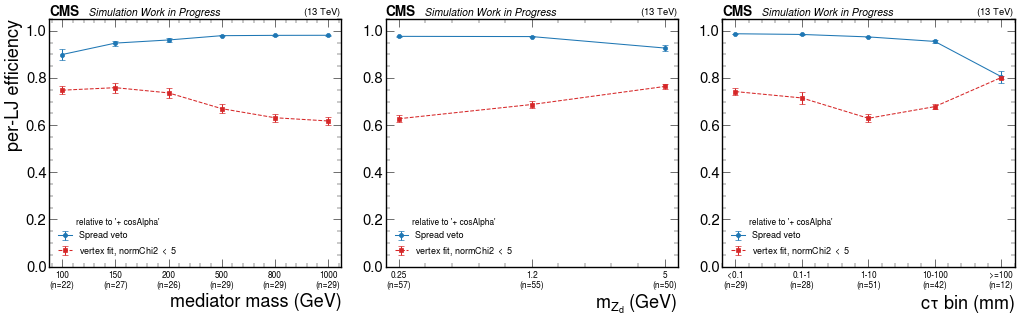

In [15]:
CT_BINS = [(0, 0.1, "<0.1"), (0.1, 1, "0.1-1"), (1, 10, "1-10"),
           (10, 100, "10-100"), (100, 1e9, ">=100")]


def group_means(values, groups, mask):
    """Per-group unweighted mean of each value array, each followed by its standard error.

    The uncertainty is the spread of the samples in the group divided by sqrt(n): it says how
    well the group mean is determined by the points in it, not the statistical error of any
    one sample. Groups of one get 0.
    """
    out = []
    for lab, sel in groups:
        m = mask & sel
        if m.sum():
            stats = []
            for v in values:
                x = v[m]
                stats += [float(x.mean()),
                          float(x.std(ddof=1) / math.sqrt(x.size)) if x.size > 1 else 0.0]
            out.append((lab, int(m.sum()), *stats))
    return out


mass_groups = [(f"{u:.0f}", S["m"] == u) for u in sorted(set(S["m"].tolist()))]
mzd_groups  = [(f"{u:g}", S["ma"] == u) for u in sorted(set(S["ma"].tolist()))]
ct_groups   = [(lab, (S["ct"] >= a) & (S["ct"] < b)) for a, b, lab in CT_BINS]

for title, groups, unit in (("mediator mass (GeV)", mass_groups, ""),
                            ("dark-photon mass m_Zd (GeV)", mzd_groups, ""),
                            ("proper decay length ctau (mm)", ct_groups, "")):
    print(f"\nper-LJ efficiency by {title} (robust subset, unweighted mean over samples,")
    print("errors are the standard error on that mean):")
    print(f"    {'group':>10s} {'n':>4s} {'Spread':>16s} {'vertex fit':>16s}")
    for lab, n, a, ea, b, eb in group_means([S["lj_sp"], S["lj_vt"]], groups, robust):
        print(f"    {lab:>10s} {n:4d} {a:9.3f} +/-{ea:5.3f} {b:9.3f} +/-{eb:5.3f}")

fig, axs = plt.subplots(1, 3, figsize=(21, 7))
for ax, (title, groups, xlab) in zip(axs, (
        ("mediator mass", mass_groups, "mediator mass (GeV)"),
        ("dark-photon mass", mzd_groups, r"$m_{Z_d}$ (GeV)"),
        ("proper decay length", ct_groups, r"$c\tau$ bin (mm)"))):
    rows = group_means([S["lj_sp"], S["lj_vt"]], groups, robust)
    x = np.arange(len(rows))
    ax.errorbar(x, [r[2] for r in rows], yerr=[r[3] for r in rows], fmt="o-",
                color="tab:blue", capsize=4, label="Spread veto")
    ax.errorbar(x, [r[4] for r in rows], yerr=[r[5] for r in rows], fmt="s--",
                color="tab:red", capsize=4, label=r"vertex fit, normChi2 $<$ 5")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{r[0]}\n(n={r[1]})" for r in rows], fontsize=12)
    ax.set_xlabel(xlab)
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=13, loc="lower left", title="relative to '+ cosAlpha'",
              title_fontsize=12)
axs[0].set_ylabel("per-LJ efficiency")
for ax in axs.ravel():
    # fontsize 15: the default collides with the "(13 TeV)" stamp in a 7-inch panel
    hep.cms.label(data=False, text="Work in Progress", ax=ax, fontsize=15)
plt.tight_layout()
plt.show()
plt.close()

The trends are consistent between the two counting units. The
Spread veto costs almost nothing except at long lifetime and large `m_Zd`, where genuinely
displaced, wide muon pairs start to look like the cosmic topology it rejects. The vertex veto
costs 25-40% everywhere and gets *worse* with mediator mass, possibly because a heavy mediator
gives boosted, collimated lepton jets whose muons the Kalman fit pairs less cleanly.

That leaves one corner where the ordering reverses.

**How to read Figure 9:** one point per signal sample, the vertex-veto efficiency against the
Spread-veto efficiency, both per LJ and both relative to `+ cosAlpha`; colour is the
dark-photon mass. Points below the diagonal are samples where the vertex veto is the harsher
cut, which is almost all of them; points above it are the corner discussed below.

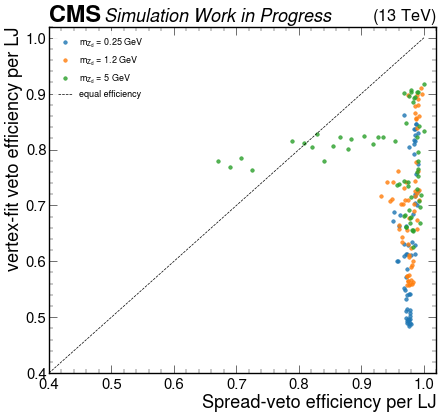


samples where the vertex veto keeps MORE than the Spread veto, per DSA muon: 8 of 180 (8 of them in the robust subset)
  sample                               m_Zd       M      ctau    N_eff   Spread      vtx


  4Mu_100GeV_5p0GeV_400mm                 5     100       400     8396    0.635    0.801
  4Mu_100GeV_5p0GeV_200mm                 5     100       200    12891    0.678    0.809
  2Mu2E_100GeV_5p0GeV_400mm               5     100       400      981    0.666    0.791
  2Mu2E_100GeV_5p0GeV_200mm               5     100       200     1466    0.688    0.793
  4Mu_150GeV_5p0GeV_270p0mm               5     150       270    25849    0.765    0.845
  2Mu2E_150GeV_5p0GeV_270p0mm             5     150       270     4853    0.800    0.850
  4Mu_150GeV_5p0GeV_130p0mm               5     150       130    49154    0.802    0.835
  2Mu2E_150GeV_5p0GeV_130p0mm             5     150       130     6789    0.840    0.849

samples where the vertex veto keeps MORE than the Spread veto, per LJ: 6 of 180 (6 of them in the robust subset)
  sample                               m_Zd       M      ctau    N_eff   Spread      vtx
  4Mu_100GeV_5p0GeV_400mm                 5     100       400     8396    0.670    0.

In [16]:
fig, ax = plt.subplots(figsize=(10, 9))
for u, c in zip(sorted(set(S["ma"].tolist())), ["tab:blue", "tab:orange", "tab:green"]):
    m = S["ma"] == u
    ax.scatter(S["lj_sp"][m], S["lj_vt"][m], s=26, color=c, alpha=0.8,
               label=rf"$m_{{Z_d}}$ = {u:g} GeV")
ax.plot([0.4, 1.0], [0.4, 1.0], "k--", linewidth=1, label="equal efficiency")
ax.set_xlabel("Spread-veto efficiency per LJ")
ax.set_ylabel("vertex-fit veto efficiency per LJ")
ax.set_xlim(0.4, 1.02)
ax.set_ylim(0.4, 1.02)
ax.legend(fontsize=13, loc="upper left", frameon=True, facecolor="white", edgecolor="none",
          framealpha=0.92)
hep.cms.label(data=False, text="Work in Progress", ax=ax)
plt.show()
plt.close()

for unit, sp, vt in (("per DSA muon", "dsa_sp", "dsa_vt"), ("per LJ", "lj_sp", "lj_vt")):
    win = S[vt] > S[sp]
    print(f"\nsamples where the vertex veto keeps MORE than the Spread veto, {unit}: "
          f"{int(win.sum())} of {len(sig_names)} "
          f"({int((win & robust).sum())} of them in the robust subset)")
    print(f"  {'sample':34s} {'m_Zd':>6s} {'M':>7s} {'ctau':>9s} {'N_eff':>8s} "
          f"{'Spread':>8s} {'vtx':>8s}")
    for i in np.argsort(-(S[vt] - S[sp]))[:int(win.sum())]:
        print(f"  {SNAME[i]:34s} {S['ma'][i]:6g} {S['m'][i]:7.0f} {S['ct'][i]:9g} "
              f"{S['neff'][i]:8.0f} {S[sp][i]:8.3f} {S[vt][i]:8.3f}")

The corner is narrow, and the two counting units disagree on its exact membership, so it is
quoted with the unit attached.

**Per DSA muon it is exactly 8 samples**, all regular: `m_Zd = 5` GeV, a mediator mass of 100
or 150 GeV, and `ctau >= 130` mm, in both final states, four mass-lifetime points each. Every one
of them is in the robust subset.

**Per LJ it is 6 samples**, and not the same set: the two 150 GeV / 130 mm points and
`2Mu2E_150GeV_5p0GeV_270p0mm` drop out, and `4Mu_100GeV_5p0GeV_40p0mm`, at
`ctau = 40` mm, comes in. The clean "`ctau >= 130` mm" statement
therefore holds only per DSA muon. The margins are small either way (the largest per-LJ gap is
0.11).

The physics is the min-versus-max asymmetry of section 1. At long lifetime with a heavy dark
photon the muon pairs are widely separated. The Spread variables, a maximum over pairs, start
failing, while `vtx_chi2`, a minimum, still finds one good dimuon. This is the only region where
the vertex veto keeps more signal than the Spread veto, and it does not justify swapping the
veto globally.

## 5. The tail sample: definitions and anchors

From here on the study concerns the DSA muons inside mu-type lepton jets above 200 GeV. It uses
a second pair of runs that carry the two-dimensional histograms needed to locate the excess:
2018C data (`vtxTail2_2018C`) and the eight-sample tail set (`vtxTailMC2_2018`).

Two definitions, fixed here and used throughout:

- **tail**: DSA-muon `pT >= 200` GeV, **including the pT overflow row** (`pT > 500` GeV),
  which is real and is where the badly measured muons pile up;
- **bulk**: the low-pT reference. Two versions appear, each labelled where it is used:
  `pT < 100` GeV for the localization of section 6, and `pT < 200` GeV, the exact complement of
  the tail, for the cut-cost accounting of section 9.

**The MC here is not the full stack.** It holds only the eight samples that populate the tail:
`DYJetsToLL_M50` and the seven `QCD_Pt` bins from 80 to 1000. The cell below checks two
consequences rather than assuming them:

- **After the veto these samples carry 97% of the MC tail**, so the post-veto tail data/MC
  quoted from here on (2.385 +/- 0.426) is compatible with the full-stack 2.31 of section 3.
  **Before** the veto they carry only 46% of it, because the full stack's pre-veto tail
  contains one `QCD_Pt30To50` event worth about 156 weighted entries, which the veto removes.
  Every pre-veto MC tail number below is therefore for this eight-sample set. It follows that
  the veto removes **54.5% of the full stack's** pre-veto MC tail (293.6 -> 133.7 weighted
  entries) and **3% of this eight-sample set's** (133.7 -> 129.5). Both are correct; they
  describe different sets. That the eight-sample set's pre-veto tail, 133.7, equals the full
  stack's post-veto tail, also 133.7, is a numerical coincidence of two unrelated quantities.
- **They do not cover the bulk.** Over all pT they carry 52.8% of the full stack's MC yield in
  this channel (57091.1 against 108137.7); the missing half is the soft-QCD bins that populate
  the low-pT region. Absolute data/MC in the bulk is therefore meaningless with this set, and so
  is anything built from its **total** yield, such as an overall normalization ratio. Only
  shapes across bins are used there, and section 8 marks the one place where that restriction
  bites.

The cell below also reproduces the data numbers of section 3 from these files, as a cross-check
that the two pairs of runs describe the same selection.

In [17]:
TAIL_FILE = f"{sidm_path}/RunOutputFiles/vtxTail2_2018C/DoubleMuon_2018C.coffea"
MCT_DIR   = f"{sidm_path}/RunOutputFiles/vtxTailMC2_2018"
H_tail    = coffea.util.load(TAIL_FILE)["out"]["DoubleMuon_2018C"]["hists"]
mc_tail   = {os.path.basename(f)[:-len(".coffea")]:
             coffea.util.load(f)["out"][os.path.basename(f)[:-len(".coffea")]]["hists"]
             for f in sorted(glob.glob(f"{MCT_DIR}/*.coffea"))}

CH_BEFORE = "cr_1egmOr1mu_lj"
CH_SPREAD = "cr_1egmOr1mu_lj_spreadMu_spreadPfMu_CosMu"
CH_VTX    = "cr_1egmOr1mu_lj_vtxChi2_CosMu"
CH_COSMIC = "cosmic_muons_vtxChi2"
TAIL_CHANS = [("Before", CH_BEFORE), ("Spread+cosAlpha", CH_SPREAD),
              ("vertex-fit+cosAlpha", CH_VTX), ("vertex-inverted cosmic", CH_COSMIC)]
print("MC samples carrying the tail:", sorted(mc_tail))


def dview(name, ch):
    """Data (values, variances) with flow. Data is unweighted, so Var = N."""
    v = H_tail[name][{"channel": ch}].values(flow=True).astype(float)
    return v, v.copy()


def mview(name, ch):
    """Lumi-scaled MC sum (values, variances) with flow, over the tail samples."""
    tv = te = None
    for H in mc_tail.values():
        if ch not in list(H[name].axes["channel"]):
            continue
        hh = H[name][{"channel": ch}]
        v, e = hh.values(flow=True).astype(float), hh.variances(flow=True).astype(float)
        tv = v.copy() if tv is None else tv + v
        te = e.copy() if te is None else te + e
    return ratio * tv, ratio ** 2 * te


def pt_rows(edges, region):
    """Row indices (flow included) of a pT region of a 2D (pT, y) histogram."""
    if region == "tail":                       # pT >= 200 incl. the pT overflow row
        return slice(int(np.searchsorted(edges, 200.0)) + 1, None)
    lim = 100.0 if region == "bulk100" else 200.0
    return slice(0, int(np.searchsorted(edges, lim)) + 1)   # incl. the pT underflow row


PT_EDGES = H_tail["mu_lj_dsaMuon_pt_nHits"][{"channel": CH_BEFORE}].axes[0].edges
TAIL, BULK100, BULK200 = (pt_rows(PT_EDGES, r) for r in ("tail", "bulk100", "bulk200"))


def prof(v, rows):
    """Collapse a 2D (pT, y) array over a pT region -> 1D y array, y flow columns kept."""
    return v[rows, :].sum(axis=0)


def ratio_err(d, dvar, m, mvar):
    """data/MC and its 1-sigma error (data Poisson + weighted-MC statistical)."""
    if m <= 0:
        return float("nan"), float("nan")
    r = d / m
    return r, r * math.sqrt((dvar / d ** 2 if d > 0 else 0.0) + mvar / m ** 2)


print(f"\n{'channel':24s} {'data total':>11s} {'data tail':>10s} | "
      f"{'MC total':>12s} {'MC tail':>16s} {'data/MC tail':>16s}")
for lab, ch in TAIL_CHANS:
    dv, _ = dview("mu_lj_dsaMuon_pt_nHits", ch)
    d_tot, d_tail = dv.sum(), prof(dv, TAIL).sum()
    if ch in (CH_BEFORE, CH_SPREAD):
        mv, me = mview("mu_lj_dsaMuon_pt_nHits", ch)
        m_tot, m_tail = mv.sum(), prof(mv, TAIL).sum()
        m_err = math.sqrt(prof(me, TAIL).sum())
        r, er = ratio_err(d_tail, d_tail, m_tail, m_err ** 2)
        print(f"{lab:24s} {d_tot:11.0f} {d_tail:10.0f} | {m_tot:12.1f} "
              f"{m_tail:9.2f} +/-{m_err:5.2f} {r:9.3f} +/-{er:5.3f}")
    else:
        print(f"{lab:24s} {d_tot:11.0f} {d_tail:10.0f} | {'-':>12s} {'-':>16s} {'-':>16s}")
print("\n(The 1D mu_lj_dsaMuon_pt yields of section 3 are reproduced exactly: "
      "63040/2414, 40881/309, 28303/187.)")

print("\nHow much of the full stack of section 3 do the eight samples carry?")
print(f"  {'channel':16s} {'region':10s} {'full stack':>12s} {'eight samples':>14s} "
      f"{'coverage':>9s}")
for ch, clab in ((CH_BEFORE, "Before"), (CH_SPREAD, "Spread+cosAlpha")):
    for rlab, lo in (("pT >= 200", 200), ("all pT", None)):
        full  = sum(tot(s, ch, lo, scale=ratio) for s in summed_MC)
        eight = (prof(mview("mu_lj_dsaMuon_pt_nHits", ch)[0], TAIL).sum() if lo
                 else mview("mu_lj_dsaMuon_pt_nHits", ch)[0].sum())
        print(f"  {clab:16s} {rlab:10s} {full:12.1f} {eight:14.1f} "
              f"{100*eight/full:8.1f}%")
print("  Tail coverage after the veto is 97%, which is why the post-veto tail data/MC of this")
print("  set matches the full stack's. Coverage over ALL pT is only 53%: these eight samples")
print("  are the tail set, not a stack, so their TOTAL yield is not a normalization and")
print("  nothing below divides by it except where section 8 flags the result as indicative.")
print("  The Before-channel tail gap is one high-weight QCD_Pt30To50 event carrying about 156")
print("  weighted entries, which the veto removes.")

MC samples carrying the tail: ['DYJetsToLL_M50', 'QCD_Pt120To170', 'QCD_Pt170To300', 'QCD_Pt300To470', 'QCD_Pt470To600', 'QCD_Pt600To800', 'QCD_Pt800To1000', 'QCD_Pt80To120']

channel                   data total  data tail |     MC total          MC tail     data/MC tail
Before                         63040       2414 |      59982.6    133.66 +/-21.95    18.060 +/-2.988
Spread+cosAlpha                40881        309 |      57091.1    129.54 +/-21.91     2.385 +/-0.426
vertex-fit+cosAlpha            28303        187 |            -                -                -
vertex-inverted cosmic         13781       1336 |            -                -                -

(The 1D mu_lj_dsaMuon_pt yields of section 3 are reproduced exactly: 63040/2414, 40881/309, 28303/187.)

How much of the full stack of section 3 do the eight samples carry?
  channel          region       full stack  eight samples  coverage
  Before           pT >= 200         293.6          133.7     45.5%
  Before           al

## 6. Where the surviving tail sits: hit count and pseudorapidity

The Spread veto with cosAlpha takes the data tail from 2414 to 309 while the MC tail barely
moves, 133.7 to 129.5. The question of this section is whether the residual factor of 2.4 is
spread evenly over the tail or concentrated somewhere, since a concentrated excess is a
candidate for a targeted cut and a flat one is not.

Two handles are available in the 2D histograms: the number of DT + CSC hits on the DSA track,
and `|eta|`. Two quantities are computed for each:

- the plain **data/MC ratio per bin**, whose errors carry both the Poisson data error and the
  weighted-MC statistical error;
- the **shape double ratio** `DR_i = f_data,i / f_MC,i`, the ratio of the *fractions* of each
  sample falling in bin `i`. This removes the overall normalization by construction, so it
  answers "is the excess concentrated?" rather than "is there an excess?". Its error uses a
  multinomial term for the data fraction and a weighted-ratio term for the MC fraction, and
  the chi2 against the flat hypothesis `DR = 1` carries `nbins - 1` degrees of freedom because
  the shared normalization removes one. **Every chi2 quoted in this section is that one**;
  other reasonable definitions of a "shape versus flat" test give different numbers.

Three warnings about that chi2, all of which apply to every one quoted below.

1. **It is diagonal-only.** The bins share a normalization, so the `DR_i` are correlated; the
   sum of `((DR_i - 1)/sigma_i)^2` ignores that. Using `nbins - 1` degrees of freedom corrects
   for the constraint, not for the correlation.
2. **It is definition-dependent by a factor of about four.** On the four fine nHits bins
   [10,15), [15,20), [20,25) and [25,30) of the post-veto tail, three reasonable "shape versus
   flat" statistics give 17.7/3 (per-bin data/MC ratio against its best-fit constant, full
   errors), 39.7/3 (the shape double ratio used here) and 75.3/3 (the same ratio with the data
   error only). Regrouping the bins moves each of them again.
3. **No p-value is quoted for these shape tests.** With 1 and 2 in force a two-significant-figure tail
   probability would be false precision. The chi2 per degree of freedom, with its definition
   attached, is the statement.

The load-bearing number of this section is therefore not a chi2 at all. It is the tail/bulk
ratio of the double ratios, quoted below with its uncertainty.

The same two quantities are computed in the bulk, and that turns out to be essential.

In [18]:
ETA_GROUPS  = [("|eta| [0,0.9)", 0.0, 0.9), ("|eta| [0.9,1.2)", 0.9, 1.2),
               ("|eta| [1.2,2.4)", 1.2, 2.4)]
# the nHits axis is Regular(12, 0, 60), so 5-wide bins; the DSA ID requires > 12 hits, so
# the [10,15) bin can only hold 13 and 14 and [10,20) is content-identical to [12,20)
NHIT_GROUPS = [("nHits [10,20)", 10, 20), ("nHits [20,30)", 20, 30),
               ("nHits [30,40)", 30, 40), ("nHits [40,60)", 40, 60)]
SPLITS = [("mu_lj_dsaMuon_pt_abseta", ETA_GROUPS, "|eta|"),
          ("mu_lj_dsaMuon_pt_nHits", NHIT_GROUPS, "nHits")]


def y_group(v, yedges, lo, hi):
    """Sum the y bins whose left edge lies in [lo, hi). v keeps its y flow columns."""
    m = (yedges[:-1] >= lo) & (yedges[:-1] < hi)
    return v[1:-1][m].sum()


def split_table(name, groups, ch, rows_sel):
    """Per-bin data, MC and data/MC for one channel and one pT region."""
    yedges = H_tail[name][{"channel": ch}].axes[1].edges
    dv, dvar = (prof(a, rows_sel) for a in dview(name, ch))
    mv, mvar = (prof(a, rows_sel) for a in mview(name, ch))
    assert dv[0] == dv[-1] == 0 and mv[0] == mv[-1] == 0, "y flow is not empty"
    D, Dv, M, Mv = dv[1:-1].sum(), dvar[1:-1].sum(), mv[1:-1].sum(), mvar[1:-1].sum()
    out = []
    for lab, lo, hi in groups:
        d  = y_group(dv, yedges, lo, hi);   dvv = y_group(dvar, yedges, lo, hi)
        m  = y_group(mv, yedges, lo, hi);   mvv = y_group(mvar, yedges, lo, hi)
        out.append((lab, d, dvv, m, mvv))
    return out, (D, Dv, M, Mv)


def shape_dr(rows, totals):
    """DR_i = f_data,i / f_MC,i with multinomial (data) and weighted-ratio (MC) errors."""
    D, _, M, Mv = totals
    out = []
    for lab, d, _, m, mvv in rows:
        fd, fm = d / D, m / M
        var_fd = fd * (1 - fd) / D
        var_fm = ((1 - fm) ** 2 * mvv + fm ** 2 * (Mv - mvv)) / M ** 2
        dr = fd / fm if fm > 0 else float("nan")
        err = dr * math.sqrt(var_fd / fd ** 2 + var_fm / fm ** 2) if fd > 0 else float("nan")
        out.append((lab, fd, fm, dr, err))
    return out


DR = {}
for name, groups, tag in SPLITS:
    for ch, clab in ((CH_BEFORE, "Before"), (CH_SPREAD, "Spread+cosAlpha")):
        rows_t, tot_t = split_table(name, groups, ch, TAIL)
        rows_b, tot_b = split_table(name, groups, ch, BULK100)
        r0, e0 = ratio_err(tot_t[0], tot_t[1], tot_t[2], tot_t[3])
        print(f"\n[{tag} | {clab}]  tail: data {tot_t[0]:.0f}  "
              f"MC {tot_t[2]:.2f} +/- {math.sqrt(tot_t[3]):.2f}  ->  data/MC {r0:.3f} +/- {e0:.3f}")
        print(f"    {'bin':18s} {'data':>7s} {'f_data':>7s} {'MC':>9s} {'f_MC':>6s} "
              f"{'data/MC':>17s} {'DR(tail)':>16s} {'DR(bulk)':>16s} {'tail/bulk':>15s}")
        drt, drb = shape_dr(rows_t, tot_t), shape_dr(rows_b, tot_b)
        for (lab, d, dvv, m, mvv), (_, fd, fm, a, ea), (_, _, _, b, eb) in zip(rows_t, drt, drb):
            r, er = ratio_err(d, dvv, m, mvv)
            tb  = a / b
            etb = tb * math.sqrt((ea / a) ** 2 + (eb / b) ** 2)
            print(f"    {lab:18s} {d:7.0f} {fd:7.3f} {m:9.2f} {fm:6.3f} "
                  f"{r:8.3f} +/-{er:6.3f} "
                  f"{a:7.3f} +/-{ea:5.3f} {b:7.3f} +/-{eb:5.3f} {tb:7.2f} +/-{etb:5.2f}")
        c2t = sum(((a - 1) / ea) ** 2 for _, _, _, a, ea in drt)
        c2b = sum(((b - 1) / eb) ** 2 for _, _, _, b, eb in drb)
        ndf = len(groups) - 1
        print(f"    chi2 vs DR = 1 (diagonal-only, shape-double-ratio definition): "
              f" tail {c2t:7.2f}/{ndf}   bulk {c2b:8.2f}/{ndf}")
        DR[(tag, clab)] = (drt, drb, c2t, c2b, ndf)


[|eta| | Before]  tail: data 2414  MC 133.66 +/- 21.95  ->  data/MC 18.060 +/- 2.988
    bin                   data  f_data        MC   f_MC           data/MC         DR(tail)         DR(bulk)       tail/bulk
    |eta| [0,0.9)         2244   0.930     94.89  0.710   23.648 +/- 5.007   1.309 +/-0.120   1.006 +/-0.007    1.30 +/- 0.12
    |eta| [0.9,1.2)         22   0.009      6.27  0.047    3.509 +/- 1.316   0.194 +/-0.077   0.999 +/-0.037    0.19 +/- 0.08
    |eta| [1.2,2.4)        148   0.061     32.50  0.243    4.554 +/- 1.296   0.252 +/-0.067   0.981 +/-0.021    0.26 +/- 0.07
    chi2 vs DR = 1 (diagonal-only, shape-double-ratio definition):  tail  238.52/2   bulk     1.57/2

[|eta| | Spread+cosAlpha]  tail: data 309  MC 129.54 +/- 21.91  ->  data/MC 2.385 +/- 0.426
    bin                   data  f_data        MC   f_MC           data/MC         DR(tail)         DR(bulk)       tail/bulk
    |eta| [0,0.9)          165   0.534     93.86  0.725    1.758 +/- 0.399   0.737 +/-0.078   

The two handles behave completely differently, and the difference is the point of the
section.

**Hit count.** In the surviving tail the excess is concentrated at low hit count. The
`nHits [10,20)` bin has data/MC = 8.10 +/- 1.56, and the ratio falls monotonically through 1.74
and 1.54 to 0.72 in the highest bin. The shape chi2 against `DR = 1` is 37.5/3, read with the
three warnings above. Before the veto the same tail is flat in nHits (chi2 2.5/3), so the veto
*creates* the low-nHits structure rather than revealing it; the mechanism table below shows how.

**Pseudorapidity.** Before the veto the tail is overwhelmingly barrel: 93% below `|eta| = 0.9`,
against 71% in MC. The shape chi2 is 238.5/2, a large, tail-specific distortion, since the bulk
is flat at 1.6/2. That is the cosmic fingerprint: cosmic muons enter through the top of the
detector and are reconstructed centrally. After the veto the barrel excess is gone, and what is
left leans to the endcap: data/MC = 4.26 +/- 1.29 for `|eta| >= 1.2`.

In [19]:
_dB = prof(dview("mu_lj_dsaMuon_pt_nHits", CH_BEFORE)[0], TAIL).sum()
_dS = prof(dview("mu_lj_dsaMuon_pt_nHits", CH_SPREAD)[0], TAIL).sum()
_mB = prof(mview("mu_lj_dsaMuon_pt_nHits", CH_BEFORE)[0], TAIL).sum()
_mS = prof(mview("mu_lj_dsaMuon_pt_nHits", CH_SPREAD)[0], TAIL).sum()
_retm = _mS / _mB
_fcos = 1 - _dS / (_dB * _retm)
print("Veto retention per bin in the tail: N(Spread+cosAlpha) / N(Before).")
print(f"The MC retention is the prompt-muon reference: the veto keeps {100*_retm:.1f}% of the")
print("MC tail. Taking that as the retention of the NON-cosmic part of the data tail and")
print("assuming the veto keeps no cosmics at all,")
print(f"   (1 - f) x {_dB:.0f} x {_retm:.3f} = {_dS:.0f}   ->   cosmic fraction "
      f"f = {_fcos:.3f}")
print("of the pre-veto data tail. The two-template phi fit of section 7 puts it at 0.84 from")
print("an entirely different observable. Both are model statements, not measurements: the")
print("first assumes zero cosmic retention, the second assumes the cosmic phi template. So")
print("retention below measures how well the veto catches cosmics in a tail that is ~87%")
print("cosmic. It is NOT the ~94% that reading the MC deficit straight off the stack gives:")
print("that conflates the cosmic fraction with the normalization mismatch of section 3.1.\n")
for name, groups, tag in SPLITS:
    print(f"  [{tag}]")
    for lab, lo, hi in groups + [("all bins", -1e9, 1e9)]:
        cells_ = []
        for ch in (CH_BEFORE, CH_SPREAD):
            yedges = H_tail[name][{"channel": ch}].axes[1].edges
            dv = prof(dview(name, ch)[0], TAIL)
            mv = prof(mview(name, ch)[0], TAIL)
            cells_.append((y_group(dv, yedges, lo, hi), y_group(mv, yedges, lo, hi)))
        (dB, mB), (dS, mS) = cells_
        print(f"    {lab:18s} data {dB:6.0f} -> {dS:5.0f} = {100*dS/dB:5.1f}%   "
              f"MC {mB:7.2f} -> {mS:7.2f} = {100*mS/mB:5.1f}%")

print("\nnHits >= 20 versus < 20 in the tail, the split the table above points at:")
nh_split = {}
yedges = H_tail["mu_lj_dsaMuon_pt_nHits"][{"channel": CH_BEFORE}].axes[1].edges
for ch, clab in ((CH_BEFORE, "Before"), (CH_SPREAD, "Spread+cosAlpha")):
    dv = prof(dview("mu_lj_dsaMuon_pt_nHits", ch)[0], TAIL)
    mv = prof(mview("mu_lj_dsaMuon_pt_nHits", ch)[0], TAIL)
    lo_d, hi_d = y_group(dv, yedges, 10, 20), y_group(dv, yedges, 20, 1e9)
    lo_m, hi_m = y_group(mv, yedges, 10, 20), y_group(mv, yedges, 20, 1e9)
    nh_split[clab] = (lo_d, hi_d, lo_m, hi_m)
    print(f"  {clab:16s} data {lo_d:5.0f} / {hi_d:5.0f}    MC {lo_m:7.2f} / {hi_m:7.2f}")
print(f"  veto retention of the tail, nHits < 20 : data "
      f"{100*nh_split['Spread+cosAlpha'][0]/nh_split['Before'][0]:.1f}%   MC "
      f"{100*nh_split['Spread+cosAlpha'][2]/nh_split['Before'][2]:.1f}%")
print(f"  veto retention of the tail, nHits >= 20: data "
      f"{100*nh_split['Spread+cosAlpha'][1]/nh_split['Before'][1]:.1f}%   MC "
      f"{100*nh_split['Spread+cosAlpha'][3]/nh_split['Before'][3]:.1f}%")

print("\nHow much of the post-veto excess must be BOTH endcap and low-nHits?")
print("Inclusion-exclusion: excess(A and B) >= excess(A) + excess(B) - excess(total),")
print("valid because the per-bin excess outside A u B is non-negative here.")
ye_e = H_tail["mu_lj_dsaMuon_pt_abseta"][{"channel": CH_SPREAD}].axes[1].edges
dv_e = prof(dview("mu_lj_dsaMuon_pt_abseta", CH_SPREAD)[0], TAIL)
mv_e = prof(mview("mu_lj_dsaMuon_pt_abseta", CH_SPREAD)[0], TAIL)
dv_h = prof(dview("mu_lj_dsaMuon_pt_nHits", CH_SPREAD)[0], TAIL)
mv_h = prof(mview("mu_lj_dsaMuon_pt_nHits", CH_SPREAD)[0], TAIL)
x_tot = dv_h[1:-1].sum() - mv_h[1:-1].sum()
x_A = y_group(dv_e, ye_e, 1.2, 1e9) - y_group(mv_e, ye_e, 1.2, 1e9)
x_B = y_group(dv_h, yedges, 10, 20) - y_group(mv_h, yedges, 10, 20)
print(f"  total excess {x_tot:7.1f}   A = endcap |eta| >= 1.2 {x_A:7.1f}   "
      f"B = nHits < 20 {x_B:7.1f}")
print(f"  => at least {x_A + x_B - x_tot:5.1f} events "
      f"({100*(x_A + x_B - x_tot)/x_tot:.0f}% of the excess) are both")

print("\nEffective MC entries behind the tail, N_eff = (sum w)^2 / sum w^2, per sample:")
for ch, clab in ((CH_SPREAD, "Spread+cosAlpha"),):
    print(f"  [{clab}]")
    tot_v = tot_e = 0.0
    for s, H in sorted(mc_tail.items()):
        hh = H["mu_lj_dsaMuon_pt_nHits"][{"channel": ch}]
        v = ratio * prof(hh.values(flow=True), TAIL).sum()
        e2 = ratio ** 2 * prof(hh.variances(flow=True), TAIL).sum()
        tot_v += v
        tot_e += e2
        print(f"    {s:20s} {v:8.3f} +/- {math.sqrt(e2):7.3f}   N_eff {v**2/e2:9.1f}")
    print(f"    {'TOTAL':20s} {tot_v:8.3f} +/- {math.sqrt(tot_e):7.3f}   "
          f"N_eff {tot_v**2/tot_e:9.1f}")

Veto retention per bin in the tail: N(Spread+cosAlpha) / N(Before).
The MC retention is the prompt-muon reference: the veto keeps 96.9% of the
MC tail. Taking that as the retention of the NON-cosmic part of the data tail and
assuming the veto keeps no cosmics at all,
   (1 - f) x 2414 x 0.969 = 309   ->   cosmic fraction f = 0.868
of the pre-veto data tail. The two-template phi fit of section 7 puts it at 0.84 from
an entirely different observable. Both are model statements, not measurements: the
first assumes zero cosmic retention, the second assumes the cosmic phi template. So
retention below measures how well the veto catches cosmics in a tail that is ~87%
cosmic. It is NOT the ~94% that reading the MC deficit straight off the stack gives:
that conflates the cosmic fraction with the normalization mismatch of section 3.1.

  [|eta|]
    |eta| [0,0.9)      data   2244 ->   165 =   7.4%   MC   94.89 ->   93.86 =  98.9%
    |eta| [0.9,1.2)    data     22 ->    15 =  68.2%   MC    6.27 -

The mechanism is now explicit. In the tail the veto keeps 50.4% of the data at `nHits < 20` but
only 8.5% above, while in MC it keeps about 97% at both. The Spread veto is much less efficient
at removing *low-hit-count* cosmics. A short DSA track has poorly measured impact parameters, so
the spread variables built from it are small and it passes. What remains at low nHits is the
part of the cosmic population the veto could not reach, plus whatever collision background lives
there. That is why the post-veto tail looks concentrated in nHits while the pre-veto tail does
not.

**The essential caveat, and it is a large one.** The bulk carries the same low-nHits distortion.
`DR(bulk)` in the `nHits [10,20)` bin is 1.504 +/- 0.038 before the veto and 1.738 +/- 0.048
after it, 13 and 15 standard deviations from 1, and the bulk chi2 against `DR = 1` is 804/3 and
862/3. Data has 1.5 to 1.7 times more low-nHits DSA muons than MC **everywhere**, tail and bulk
alike; this is a DSA reconstruction mismodelling, not a property of the tail. Dividing the tail
double ratio by the bulk one removes any pT-independent part of it and leaves

    tail/bulk in nHits [10,20) = 1.95 +/- 0.46,

which is 2.1 standard deviations from unity. A tail-specific low-nHits effect is therefore
*hinted at*, not established; most of the raw 3.4 is inherited from the bulk. Any statement that
"the surviving excess is a low-nHits population" must carry this correction.

**A bound on the correction itself.** The `DR(bulk)` denominator, 1.738 +/- 0.048, is measured
on the eight-sample tail set, which covers only 52.8% of the full stack over all pT and lacks
exactly the soft-QCD bins that populate the low-pT bulk. It is therefore the low-nHits shape
distortion of the *tail samples'* bulk, not of the full stack's bulk, and the 1.95 +/- 0.46
inherits that: if the missing samples carry a different low-nHits fraction, the tail/bulk ratio
moves with it. Only the eight-sample set has the two-dimensional histograms, so the full-stack
version of this test needs another MC pass and is not available here.

The `|eta|` distortion passes the same test where nHits does not. In the Before channel the
tail chi2 is 238.5/2 against a bulk chi2 of 1.6/2, so the distortion is tail-specific, and it is
the cosmic fingerprint. After the veto the residual `|eta|` structure is much weaker (tail
14.1/2, but the bulk is 348/2 there too).

**The MC is thin.** The 129.5 weighted events of the post-veto MC tail amount to an effective
N_eff of about 35. Two samples contribute essentially single events, `QCD_Pt120To170` at
`N_eff = 1` and `QCD_Pt80To120` at `N_eff = 2`, and together they are more than a quarter of the
MC tail. Every MC-normalized number in this section inherits that; the +/- 0.43 on the inclusive
2.385 is dominated by it, not by the data.

**How to read Figure 10:** the top row is the plain data/MC ratio per bin in the tail, against
hit count (left) and `|eta|` (right), with the dashed line at the inclusive tail data/MC of
the same channel; the bottom row is the shape double ratio `DR = f_data / f_MC` in the same
bins, filled circles for the tail and open squares for the bulk, with the dashed line at
`DR = 1`. A bin where the two markers of the bottom row sit on top of each other is
mismodelled in the bulk as well and is therefore not a tail effect.

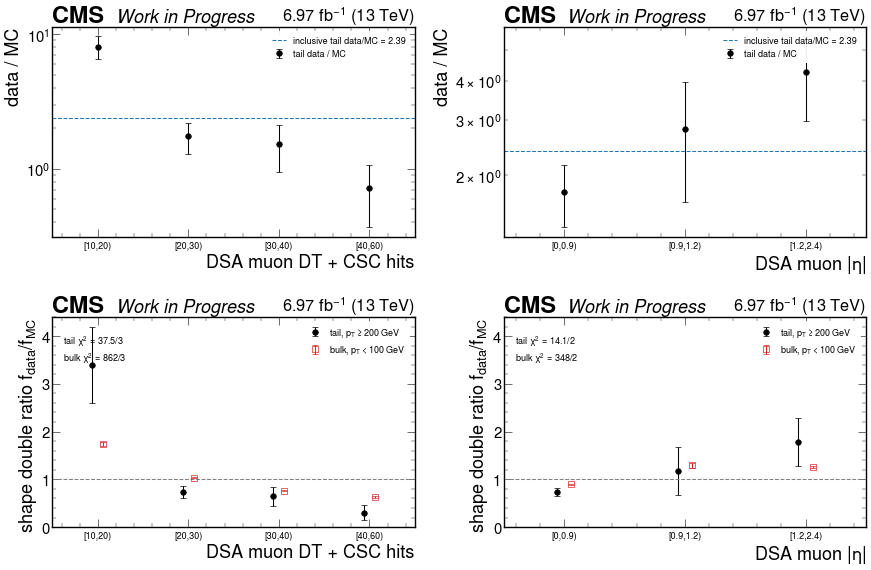

In [20]:
fig, axs = plt.subplots(2, 2, figsize=(18, 12))
for col, (name, groups, tag) in enumerate(SPLITS[::-1]):    # nHits left, |eta| right
    rows_t, tot_t = split_table(name, groups, CH_SPREAD, TAIL)
    drt, drb, c2t, c2b, ndf = DR[(tag, "Spread+cosAlpha")]
    x = np.arange(len(groups))
    labs = [g[0].replace(f"{tag} ", "") for g in groups]

    ax = axs[0, col]
    y, ey = zip(*[ratio_err(d, dvv, m, mvv) for _, d, dvv, m, mvv in rows_t])
    ax.errorbar(x, y, yerr=ey, fmt="o", color="k", markersize=8, capsize=4,
                label="tail data / MC")
    r0, _ = ratio_err(*tot_t)
    ax.axhline(r0, color="tab:blue", linestyle="--",
               label=f"inclusive tail data/MC = {r0:.2f}")
    ax.set_yscale("log")
    ax.set_ylabel("data / MC")
    ax.legend(fontsize=13, loc="upper right", frameon=True, facecolor="white",
              edgecolor="none", framealpha=0.92)

    ax = axs[1, col]
    ax.errorbar(x - 0.06, [r[3] for r in drt], yerr=[r[4] for r in drt], fmt="o",
                color="k", markersize=8, capsize=4, label=r"tail, $p_T \geq 200$ GeV")
    ax.errorbar(x + 0.06, [r[3] for r in drb], yerr=[r[4] for r in drb], fmt="s",
                markerfacecolor="none", color="tab:red", markersize=8, capsize=4,
                label=r"bulk, $p_T < 100$ GeV")
    ax.axhline(1.0, color="grey", linestyle="--")
    ax.set_ylabel(r"shape double ratio $f_{data}/f_{MC}$")
    ax.set_ylim(0, 4.4)
    ax.legend(fontsize=13, loc="upper right", frameon=True, facecolor="white",
              edgecolor="none", framealpha=0.92)
    ax.text(0.03, 0.92, f"tail $\\chi^2$ = {c2t:.1f}/{ndf}\nbulk $\\chi^2$ = {c2b:.0f}/{ndf}",
            transform=ax.transAxes, fontsize=13, va="top")

    for ax in (axs[0, col], axs[1, col]):
        ax.set_xticks(x)
        ax.set_xticklabels(labs, fontsize=13)
        ax.set_xlabel("DSA muon DT + CSC hits" if tag == "nHits" else r"DSA muon $|\eta|$")
        ax.set_xlim(-0.5, len(groups) - 0.5)
for ax in axs.ravel():
    hep.cms.label(data=True, lumi=LUMI_DATA, text="Work in Progress", ax=ax)
plt.tight_layout()
plt.show()
plt.close()

## 7. Where the cosmics went: the azimuthal handle

Cosmic muons arrive from above, so they populate `phi` near `+/- pi/2` and avoid `phi` near 0
and `+/- pi`. The handle used here is the ratio of the number of DSA muons within 0.5 rad of
`+/- pi/2` (**vertical**) to the number within 0.5 rad of 0 or `+/- pi` (**horizontal**). A
collision population gives a ratio near 1; the MC prediction for it is computed from the same
histogram and is not assumed.

The *observation* is data-driven: it uses no vertex information and no MC normalization, so it
is independent of everything in sections 3 and 6, and in particular of the normalization
mismatch of section 3.1. The *cosmic template* is not. It is measured in the **vertex-inverted
cosmic region** (`cosmic_muons_vtxChi2`), whose definition contains `no vtx or vtx_chi2 >= 5`,
so the template does use the vertex variable. The spread-inverted cosmic region of section 2b,
which uses none, was never run with the two-dimensional pT x phi histogram and so cannot supply
the template here. Everything below that depends on the template is stated as conditional on
it, and the cell after next measures how much it depends on it.

In [21]:
PH = "mu_lj_dsaMuon_pt_phi"
ph_edges = H_tail[PH][{"channel": CH_BEFORE}].axes[1].edges
ctr  = 0.5 * (ph_edges[1:] + ph_edges[:-1])
vert = np.array([min(abs(c - math.pi/2), abs(c + math.pi/2)) < 0.5 for c in ctr])
horz = np.array([min(abs(c), math.pi - abs(c)) < 0.5 for c in ctr])
print(f"phi bin centres      : {np.round(ctr, 3)}")
print(f"vertical bin indices : {np.where(vert)[0]}")
print(f"horizontal bin indices: {np.where(horz)[0]}")


def vh(v, e, rows):
    p, pe = prof(v, rows)[1:-1], prof(e, rows)[1:-1]
    return p[vert].sum(), math.sqrt(pe[vert].sum()), p[horz].sum(), math.sqrt(pe[horz].sum())


def vh_ratio(v, e, rows, poisson):
    V, Ve, H, He = vh(v, e, rows)
    if V <= 0 or H <= 0:
        return float("nan"), float("nan"), V, H
    r = V / H
    er = r * (math.sqrt(1/V + 1/H) if poisson else math.sqrt((Ve/V)**2 + (He/H)**2))
    return r, er, V, H


print(f"\n{'channel':22s} {'region':6s} {'V':>9s} {'H':>9s} {'V/H (data)':>18s} "
      f"{'V/H (MC)':>18s} {'double ratio':>18s}")
phi_res = {}
for lab, ch in TAIL_CHANS:
    for rows, rlab in ((TAIL, "tail"), (BULK200, "bulk")):
        rd, erd, V, H = vh_ratio(*dview(PH, ch), rows, True)
        if ch in (CH_BEFORE, CH_SPREAD):
            rm, erm, _, _ = vh_ratio(*mview(PH, ch), rows, False)
            dr  = rd / rm
            edr = dr * math.sqrt((erd/rd)**2 + (erm/rm)**2)
            mtxt, dtxt = f"{rm:8.3f} +/-{erm:5.3f}", f"{dr:8.3f} +/-{edr:5.3f}"
        else:
            rm = erm = float("nan")
            mtxt = dtxt = f"{'-':>18s}"
        phi_res[(lab, rlab)] = (rd, erd, rm, erm)
        print(f"{lab:22s} {rlab:6s} {V:9.0f} {H:9.0f} {rd:9.3f} +/-{erd:6.3f} "
              f"{mtxt:>18s} {dtxt:>18s}")

phi bin centres      : [-2.945 -2.553 -2.16  -1.767 -1.374 -0.982 -0.589 -0.196  0.196  0.589
  0.982  1.374  1.767  2.16   2.553  2.945]
vertical bin indices : [ 3  4 11 12]
horizontal bin indices: [ 0  7  8 15]

channel                region         V         H         V/H (data)           V/H (MC)       double ratio
Before                 tail        1186        97    12.227 +/- 1.291     1.295 +/-0.218     9.443 +/-1.875
Before                 bulk       21626     10985     1.969 +/- 0.023     0.971 +/-0.028     2.027 +/-0.062
Spread+cosAlpha        tail          77        82     0.939 +/- 0.149     1.234 +/-0.211     0.761 +/-0.177
Spread+cosAlpha        bulk       10593     10067     1.052 +/- 0.015     0.975 +/-0.028     1.079 +/-0.035
vertex-fit+cosAlpha    tail          47        43     1.093 +/- 0.231                  -                  -
vertex-fit+cosAlpha    bulk        7390      6951     1.063 +/- 0.018                  -                  -
vertex-inverted cosmic tail    

In [22]:
# 95% CL upper limit on a residual cosmic component in the post-veto tail, from the vertical
# fraction of the V+H sample: the cosmic template comes from the VERTEX-INVERTED cosmic region
# (cosmic_muons_vtxChi2), the non-cosmic template from MC in the same channel as the
# observation. The template therefore uses the vertex variable; the sensitivity scan below
# says how much that matters.
Vc, _, Hc, _ = vh(*dview(PH, CH_COSMIC), TAIL)
Vs, _, Hs, _ = vh(*dview(PH, CH_SPREAD), TAIL)
mv_ph, me_ph = mview(PH, CH_SPREAD)
Vm, Vme, Hm, Hme = vh(mv_ph, me_ph, TAIL)

f_cos = Vc / (Vc + Hc)
f_mc  = Vm / (Vm + Hm)
f_obs = Vs / (Vs + Hs)
n_obs = Vs + Hs
e_obs = math.sqrt(f_obs * (1 - f_obs) / n_obs)
e_mc  = f_mc * (1 - f_mc) * math.sqrt((Vme / Vm) ** 2 + (Hme / Hm) ** 2)

d_tail = prof(dview("mu_lj_dsaMuon_pt_nHits", CH_SPREAD)[0], TAIL).sum()
ul95   = f_obs + 1.645 * math.sqrt(e_obs ** 2 + e_mc ** 2)
f_ul   = max((ul95 - f_mc) / (f_cos - f_mc), 0.0)
print("vertical fraction among the V+H DSA muons of the tail:")
print(f"  vertex-inverted template : {f_cos:.4f}                (V={Vc:.0f}, H={Hc:.0f})")
print(f"  MC non-cosmic template   : {f_mc:.4f} +/- {e_mc:.4f}   (V={Vm:.2f}, H={Hm:.2f})")
print(f"  observed post-veto tail  : {f_obs:.4f} +/- {e_obs:.4f}   (V={Vs:.0f}, H={Hs:.0f})")
print(f"  best-fit cosmic fraction : {(f_obs - f_mc)/(f_cos - f_mc):+.4f}")
print(f"  95% CL upper limit       : {f_ul:.4f}  ->  fewer than {f_ul*d_tail:.1f} "
      f"of the {d_tail:.0f} tail events")

# How much does the limit depend on the template? Degrade the template's vertical fraction
# deliberately and redo the same one-sided limit.
print("\nSensitivity of the limit to the cosmic template's vertical fraction:")
for f_alt in (f_cos, 0.95, 0.90, 0.80):
    ul_alt = max((ul95 - f_mc) / (f_alt - f_mc), 0.0)
    tag = "   (as measured)" if f_alt == f_cos else ""
    print(f"  template vertical fraction {f_alt:.4f}  ->  cosmic fraction < {ul_alt:.4f} "
          f"at 95% CL{tag}")
print("  A template only 0.90 vertical - far more contaminated than the region's own V/H of")
print("  108 allows - moves the bound from 6.2% to 7.8%. The conclusion does not rest on the")
print("  template being pure, only on its being much more vertical than the observation.")

# The same two-template mixture applied to the PRE-veto tail: an estimate of its cosmic
# content that is independent of the veto-retention route used in section 6.
Vb, _, Hb, _ = vh(*dview(PH, CH_BEFORE), TAIL)
Vmb, _, Hmb, _ = vh(*mview(PH, CH_BEFORE), TAIL)
f_obs_b, f_mc_b = Vb / (Vb + Hb), Vmb / (Vmb + Hmb)
f_cos_before = (f_obs_b - f_mc_b) / (f_cos - f_mc_b)
print("\nThe same two-template mixture on the PRE-veto tail:")
print(f"  observed vertical fraction {f_obs_b:.4f} (V={Vb:.0f}, H={Hb:.0f}); MC non-cosmic "
      f"template {f_mc_b:.4f}")
print(f"  ->  cosmic fraction of the pre-veto tail = {f_cos_before:.3f}")
print("  Section 6 reached 0.87 for the same quantity from veto retention against the MC")
print("  prompt-muon reference, a completely different observable.")

print("\nWhere the muons of each channel sit in hit count (the same tail definition):")
yedges = H_tail["mu_lj_dsaMuon_pt_nHits"][{"channel": CH_BEFORE}].axes[1].edges
for lab, ch in TAIL_CHANS:
    dv = prof(dview("mu_lj_dsaMuon_pt_nHits", ch)[0], TAIL)
    lo, hi, tt = y_group(dv, yedges, 10, 20), y_group(dv, yedges, 20, 1e9), dv[1:-1].sum()
    print(f"  {lab:24s} n={tt:6.0f}   nHits [10,20) {lo:5.0f} ({100*lo/tt:5.1f}%)   "
          f">= 20 {hi:5.0f} ({100*hi/tt:5.1f}%)")

vertical fraction among the V+H DSA muons of the tail:
  vertex-inverted template : 0.9908                (V=753, H=7)
  MC non-cosmic template   : 0.5525 +/- 0.0422   (V=24.68, H=19.99)
  observed post-veto tail  : 0.4843 +/- 0.0396   (V=77, H=82)
  best-fit cosmic fraction : -0.1556
  95% CL upper limit       : 0.0617  ->  fewer than 19.1 of the 309 tail events

Sensitivity of the limit to the cosmic template's vertical fraction:
  template vertical fraction 0.9908  ->  cosmic fraction < 0.0617 at 95% CL   (as measured)
  template vertical fraction 0.9500  ->  cosmic fraction < 0.0680 at 95% CL
  template vertical fraction 0.9000  ->  cosmic fraction < 0.0778 at 95% CL
  template vertical fraction 0.8000  ->  cosmic fraction < 0.1093 at 95% CL
  A template only 0.90 vertical - far more contaminated than the region's own V/H of
  108 allows - moves the bound from 6.2% to 7.8%. The conclusion does not rest on the
  template being pure, only on its being much more vertical than the obse

**How to read Figure 11:** the DSA-muon `phi` distribution above 200 GeV, each channel
normalized to unit area so only the shape is compared; the dotted vertical lines mark
`+/- pi/2`, where a cosmic population peaks, and the shaded bands mark the horizontal windows
it avoids. The grey dashed curve is the vertex-inverted cosmic region, used as the template.

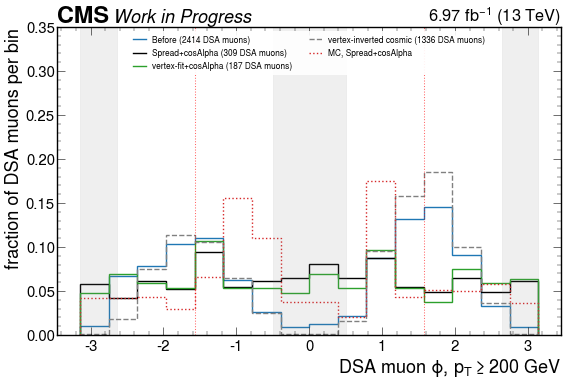

In [23]:
fig, ax = plt.subplots(figsize=(13, 8))
styles = {"Before": dict(color="tab:blue"), "Spread+cosAlpha": dict(color="k"),
          "vertex-fit+cosAlpha": dict(color="tab:green"),
          "vertex-inverted cosmic": dict(color="grey", linestyle="--")}
for lab, ch in TAIL_CHANS:
    p = prof(dview(PH, ch)[0], TAIL)[1:-1]
    hep.histplot(p / p.sum(), ph_edges, ax=ax, histtype="step", linewidth=2,
                 label=f"{lab} ({p.sum():.0f} DSA muons)", **styles[lab])
mp = prof(mview(PH, CH_SPREAD)[0], TAIL)[1:-1]
hep.histplot(mp / mp.sum(), ph_edges, ax=ax, histtype="step", linewidth=2,
             color="tab:red", linestyle=":", label="MC, Spread+cosAlpha")
for x in (-math.pi/2, math.pi/2):
    ax.axvline(x, color="red", linestyle=":", alpha=0.6)
for lo, hi in ((-math.pi, -math.pi + 0.5), (-0.5, 0.5), (math.pi - 0.5, math.pi)):
    ax.axvspan(lo, hi, color="grey", alpha=0.12)
ax.set_xlabel(r"DSA muon $\phi$, $p_{T} \geq 200$ GeV")
ax.set_ylabel("fraction of DSA muons per bin")
ax.set_ylim(0, 0.35)
ax.legend(fontsize=12, ncol=2, loc="upper center", frameon=True, facecolor="white",
          edgecolor="none", framealpha=0.92)
hep.cms.label(data=True, lumi=LUMI_DATA, text="Work in Progress", ax=ax)
plt.show()
plt.close()

**Before the veto the tail is cosmic.** Its vertical-to-horizontal ratio is 12.2 +/- 1.3,
against 1.29 +/- 0.22 in MC (a data/MC double ratio of 9.4 +/- 1.9), and the vertex-inverted
cosmic template sits at 107.6 +/- 40.8. Fitting the pre-veto vertical fraction to the same
two-template mixture used below puts the cosmic content of the pre-veto tail at 0.84, in
agreement with the independent veto-retention estimate of ~87% in section 6. The bulk of the
same channel is at 1.97, itself elevated because cosmics leak into it; the MC bulk is 0.97.

**After the veto it is not cosmic.** The post-Spread-veto tail ratio is 0.94 +/- 0.15 and the
post-vertex-veto tail ratio is 1.09 +/- 0.23. Both are consistent with the MC expectation of
1.23 +/- 0.21 and incompatible with the cosmic template by a wide margin. Fitting the observed
vertical fraction to a two-template mixture bounds the residual cosmic component at

    < 6.2% of the surviving tail at 95% CL, i.e. fewer than 19 of the 309 events.

The best fit is negative, so this is an upper limit, not a measurement.

**The cosmic sample available here is high-hit-count, and that is weaker than it sounds.** The
vertex-inverted cosmic region's tail is 93.9% `nHits >= 20`, against 89.6% in the pre-veto tail
and 59.2% in the post-veto tail. The tempting reading, "the low-nHits survivors of section 6 are
therefore not cosmic", is not supported. The template is biased against exactly the tracks in
question: the region requires a back-to-back muon *pair*, and cosAlpha near -1 is the quantity a
short, poorly measured track reconstructs worst, so the region's own definition under-selects
low-nHits cosmics. Only the weaker statement survives: **the vertex-inverted cosmic region, the
only cosmic-enriched sample available here, contains few low-nHits tracks, so it offers no
evidence that the survivors are cosmic, and none that they are not.**

**Caveat on the limit.** The 2018C outputs have no `phi` x `nHits` histogram, so the cosmic
limit is inclusive over the tail: it constrains the tail as a whole, not each part of it. A
cosmic residual confined entirely to the 126-event low-nHits subset could reach roughly 15% of
that subset while still respecting the inclusive 6.2% bound, and the template bias above keeps
this section from saying more. Section 10.4 books `phi` x `nHits` on the full 2018 sample. There
the `nHits < 20` tail after the Spread veto is more horizontal than vertical
(vertical/horizontal 0.73 against 0.99 for its own low-pT bulk), the opposite of the cosmic
signature.

## 8. An independent control sample: DSA against PF momentum

Sections 6 and 7 say what the surviving tail is not. This section asks what could produce it,
using a control sample that shares no selection with the lepton-jet tail.

**Method.** In the same events, the raw `DSAMuon` collection is re-selected with the same
identification cuts the lepton-jet DSA muons pass, **minus the cross-cleaning against PF
muons**. Each surviving DSA muon is matched to a selected PF muon within `dR < 0.2`. The
observable is the response

    r = pT(DSA) / pT(PF),

with the PF measurement standing in for the truth. The LJ DSA muons are by construction the
ones *without* a PF partner, so the matched sample is disjoint from the tail it is used to
describe, and no veto has been applied to it.

**What the method is not.** In the analysis channels the cross-cleaning is a **segment match**
(a DSA muon is removed against a PF muon with which it shares more than a third of its
muon-chamber segments (shared over total >= 0.34) with the two outer-track directions within
`dR < 0.1`, or all of its segments), not a `dR`
match. This control sample is therefore close to, but not exactly, the complement of the LJ DSA
population. It is a sizing tool, not a substitution.

Two numbers are extracted: the fraction of matched muons in the response tail, and the
**feed-up** probability, the probability that a low-pT PF muon is reconstructed as a high-pT
DSA muon.

In [24]:
RH_N, RH_E = "dsaPfMatch_response_nHits", "dsaPfMatch_response_abseta"
r_edges = H_tail[RH_N][{"channel": CH_BEFORE}].axes[0].edges
LOGR    = np.log10(r_edges)


def frac_above_interp(v1d, thr):
    """Entries with r > thr from a flow-included 1D response array.

    The response axis is uniform in log10(r), so the bin straddling the threshold is split
    log-linearly instead of being snapped to the nearest edge (which would move an
    r > 2 cut to r > 1.88 or r > 2.24 and shift the answer by several per cent).
    """
    lt = math.log10(thr)
    j = int(np.searchsorted(LOGR, lt, side="right")) - 1
    n = float(v1d[j + 2:].sum())
    n += float(v1d[j + 1]) * (LOGR[j + 1] - lt) / (LOGR[j + 1] - LOGR[j])
    return n, float(v1d.sum())


def p_above(dv, mv, mvar, thr):
    dn, dt = frac_above_interp(dv, thr)
    mn, mt = frac_above_interp(mv, thr)
    mnv, mtv = frac_above_interp(mvar, thr)
    p_d, p_m = dn / dt, mn / mt
    e_d = math.sqrt(dn) / dt
    e_m = math.sqrt(max(mnv * (1 - p_m) ** 2 + (mtv - mnv) * p_m ** 2, 0.0)) / mt
    rr = p_d / p_m
    return p_d, e_d, p_m, e_m, rr, rr * math.sqrt((e_d/p_d) ** 2 + (e_m/p_m) ** 2), dn


dv_r, _   = dview(RH_N, CH_BEFORE)
mv_r, me_r = mview(RH_N, CH_BEFORE)
d1, m1, v1 = dv_r.sum(axis=1), mv_r.sum(axis=1), me_r.sum(axis=1)
print(f"matched DSA-PF muons in the Before channel: data {d1.sum():.0f}, "
      f"MC {m1.sum():.1f} +/- {math.sqrt(v1.sum()):.1f}  ->  data/MC {d1.sum()/m1.sum():.3f}")
print(f"response-axis flow: data r<0.1 {d1[0]:.0f}, r>100 {d1[-1]:.0f}\n")

RESP = {}
for thr in (2.0, 5.0):
    p_d, e_d, p_m, e_m, rr, er, dn = p_above(d1, m1, v1, thr)
    RESP[thr] = (rr, er)
    print(f"P(r > {thr:g}) : data {p_d:.5f} +/- {e_d:.5f} (N = {dn:.0f})   "
          f"MC {p_m:.5f} +/- {e_m:.5f}   ->  data/MC {rr:.3f} +/- {er:.3f}")

print("\nIs the mismodelling flat? Same interpolated P(r > 2), sliced in nHits and |eta|:")
FLAT = {}
for hn, axn, lab, groups in (
        (RH_N, "dsaPfMatch_nHits", "nHits",
         [(3, 4, "[10,15)"), (4, 5, "[15,20)"), (5, 6, "[20,25)"), (6, 7, "[25,30)"),
          (7, 8, "[30,35)"), (8, 9, "[35,40)"), (9, 14, "[40,inf)")]),
        (RH_E, "dsaPfMatch_abseta", "|eta|",
         [(1, 7, "0.0-0.6"), (7, 13, "0.6-1.2"), (13, 19, "1.2-1.8"),
          (19, 22, "1.8-2.1"), (22, 25, "2.1-2.4")])):
    dv_, _ = dview(hn, CH_BEFORE)
    mv_, me_ = mview(hn, CH_BEFORE)
    rs, ers, labs = [], [], []
    for a, b, gl in groups:
        _, _, _, _, rr, er, dn = p_above(dv_[:, a:b].sum(axis=1), mv_[:, a:b].sum(axis=1),
                                         me_[:, a:b].sum(axis=1), 2.0)
        if dn < 20:
            continue
        rs.append(rr); ers.append(er); labs.append(gl)
    rs, ers = np.array(rs), np.array(ers)
    w  = 1 / ers ** 2
    c  = (rs * w).sum() / w.sum()
    x2 = float((((rs - c) / ers) ** 2).sum())
    FLAT[lab] = (c, x2, len(rs) - 1, rs.min(), rs.max())
    print(f"  {lab:6s}: " + "  ".join(f"{l}={a:.2f}+/-{b:.2f}"
                                      for l, a, b in zip(labs, rs, ers)))
    print(f"          best flat value {c:.3f}, chi2 = {x2:.2f}/{len(rs)-1}, "
          f"range {rs.min():.2f} - {rs.max():.2f}")

matched DSA-PF muons in the Before channel: data 402820, MC 442643.6 +/- 1732.8  ->  data/MC 0.910
response-axis flow: data r<0.1 73, r>100 2

P(r > 2) : data 0.06678 +/- 0.00041 (N = 26902)   MC 0.03697 +/- 0.00071   ->  data/MC 1.806 +/- 0.037
P(r > 5) : data 0.00928 +/- 0.00015 (N = 3737)   MC 0.00436 +/- 0.00025   ->  data/MC 2.126 +/- 0.127

Is the mismodelling flat? Same interpolated P(r > 2), sliced in nHits and |eta|:
  nHits : [10,15)=1.19+/-0.28  [15,20)=1.81+/-0.08  [20,25)=1.50+/-0.05  [25,30)=2.01+/-0.12  [30,35)=1.96+/-0.10  [35,40)=1.45+/-0.12  [40,inf)=1.35+/-0.10
          best flat value 1.619, chi2 = 45.50/6, range 1.19 - 2.01
  |eta| : 0.0-0.6=1.85+/-0.06  0.6-1.2=1.62+/-0.06  1.2-1.8=2.18+/-0.10  1.8-2.1=1.72+/-0.13  2.1-2.4=1.07+/-0.10
          best flat value 1.714, chi2 = 69.83/4, range 1.07 - 2.18


**How to read Figure 12:** the matched DSA-to-PF momentum response, data against the eight-sample
MC, each normalized to unit area, on logarithmic axes so the tail out to `r = 100` is visible;
the dotted lines mark `r = 2` and `r = 5`. The core agrees; the data tail does not.

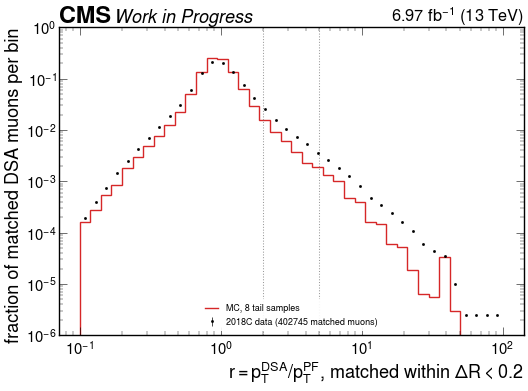

In [25]:
fig, ax = plt.subplots(figsize=(12, 8))
d_r = d1[1:-1]
m_r = m1[1:-1]
hep.histplot(d_r / d_r.sum(), r_edges, ax=ax, histtype="errorbar", color="k",
             label=f"2018C data ({d_r.sum():.0f} matched muons)")
hep.histplot(m_r / m_r.sum(), r_edges, ax=ax, histtype="step", linewidth=2, color="tab:red",
             label="MC, 8 tail samples")
for t in (2, 5):
    ax.axvline(t, color="grey", linestyle=":", alpha=0.8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(1e-6, 1)
ax.set_xlabel(r"$r = p_{T}^{DSA} / p_{T}^{PF}$, matched within $\Delta R < 0.2$")
ax.set_ylabel("fraction of matched DSA muons per bin")
ax.legend(fontsize=13, loc="lower center", frameon=True, facecolor="white",
          edgecolor="none", framealpha=0.92)
hep.cms.label(data=True, lumi=LUMI_DATA, text="Work in Progress", ax=ax)
plt.show()
plt.close()

In [26]:
FH = "dsaPfMatch_ptPf_ptDsa"
pf_e = H_tail[FH][{"channel": CH_BEFORE}].axes[0].edges
ds_e = H_tail[FH][{"channel": CH_BEFORE}].axes[1].edges
dv_f, _   = dview(FH, CH_BEFORE)
mv_f, me_f = mview(FH, CH_BEFORE)


def feedup(pf_max=100.0, dsa_min=200.0):
    """P(pT_DSA >= dsa_min | pT_PF < pf_max) in data and MC, and the ratio."""
    i_pf = int(np.searchsorted(pf_e, pf_max, side="left"))
    i_ds = int(np.searchsorted(ds_e, dsa_min, side="left"))
    dd, mm, mv_ = dv_f[0:i_pf+1, :], mv_f[0:i_pf+1, :], me_f[0:i_pf+1, :]
    dnum, dden = dd[:, i_ds+1:].sum(), dd.sum()
    mnum, mden = mm[:, i_ds+1:].sum(), mm.sum()
    mnum_e, mden_e = math.sqrt(mv_[:, i_ds+1:].sum()), math.sqrt(mv_.sum())
    p_d, p_m = dnum / dden, mnum / mden
    e_d = math.sqrt(dnum) / dden
    e_m = p_m * math.sqrt((mnum_e/mnum) ** 2 + (mden_e/mden) ** 2)
    rr = p_d / p_m
    return dict(dnum=dnum, dden=dden, p_d=p_d, e_d=e_d, p_m=p_m, e_m=e_m,
                ratio=rr, e_ratio=rr * math.sqrt((e_d/p_d)**2 + (e_m/p_m)**2))


FU = feedup()
print("Feed-up probability P(pT_DSA >= 200 GeV | pT_PF < 100 GeV), Before channel:")
print(f"  data {FU['dnum']:.0f} / {FU['dden']:.0f} = {FU['p_d']:.6f} +/- {FU['e_d']:.6f}")
print(f"  MC                       = {FU['p_m']:.6f} +/- {FU['e_m']:.6f}")
print(f"  data/MC                  = {FU['ratio']:.3f} +/- {FU['e_ratio']:.3f}")

print("\nSame probability bin by bin in pT_PF:")
i_ds = int(np.searchsorted(ds_e, 200.0, side="left"))
fu_x, fu_r, fu_er = [], [], []
print(f"  {'pT_PF bin':>14s} {'data N':>8s} {'P(data)':>11s} {'P(MC)':>11s} {'data/MC':>9s}")
for j in range(1, len(pf_e)):
    dnum, dden = dv_f[j, i_ds+1:].sum(), dv_f[j, :].sum()
    mnum, mden = mv_f[j, i_ds+1:].sum(), mv_f[j, :].sum()
    if dden < 100 or mnum <= 0:
        continue
    p_d, p_m = dnum / dden, mnum / mden
    e_d = math.sqrt(dnum) / dden
    e_m = p_m * math.sqrt(me_f[j, i_ds+1:].sum() / mnum ** 2 + me_f[j, :].sum() / mden ** 2)
    rr = p_d / p_m
    fu_x.append(0.5 * (pf_e[j-1] + pf_e[j]))
    fu_r.append(rr)
    fu_er.append(rr * math.sqrt((e_d/p_d) ** 2 + (e_m/p_m) ** 2))
    print(f"  [{pf_e[j-1]:5.0f},{pf_e[j]:5.0f}) {dnum:8.0f} {p_d:11.3e} {p_m:11.3e} {rr:9.2f}")

Feed-up probability P(pT_DSA >= 200 GeV | pT_PF < 100 GeV), Before channel:
  data 3137 / 394257 = 0.007957 +/- 0.000142
  MC                       = 0.002291 +/- 0.000161
  data/MC                  = 3.474 +/- 0.252

Same probability bin by bin in pT_PF:
       pT_PF bin   data N     P(data)       P(MC)   data/MC
  [    0,   10)       25   8.015e-03   1.643e-03      4.88
  [   10,   20)       37   2.769e-03   1.902e-03      1.46
  [   20,   30)      270   2.961e-03   1.115e-03      2.66
  [   30,   40)      603   4.378e-03   1.535e-03      2.85
  [   40,   50)      558   7.232e-03   2.170e-03      3.33
  [   50,   60)      424   1.249e-02   2.487e-03      5.02
  [   60,   80)      694   2.500e-02   5.362e-03      4.66
  [   80,  100)      526   5.275e-02   1.675e-02      3.15
  [  100,  150)      694   1.063e-01   4.682e-02      2.27
  [  150,  200)      264   2.039e-01   1.946e-01      1.05
  [  200,  300)      170   3.114e-01   4.141e-01      0.75
  [  300,  500)       69   3.920e-0

**How to read Figure 13:** left panel, the probability that a matched muon reconstructed by PF
below the abscissa is reconstructed by DSA above 200 GeV, data against MC, against the PF pT
bin; right panel, the data/MC ratio of that probability, with the dashed line at the value
integrated over `pT_PF < 100` GeV. The rise of both curves toward high `pT_PF` is kinematic: a
150 GeV PF muon needs much less mismeasurement to land above 200 GeV than a 30 GeV one. The
statement is the *ratio*, and the shaded band marks the window the control number is taken in.
Error bars are statistical: Poisson on the data numerator, weighted-MC on the simulation.

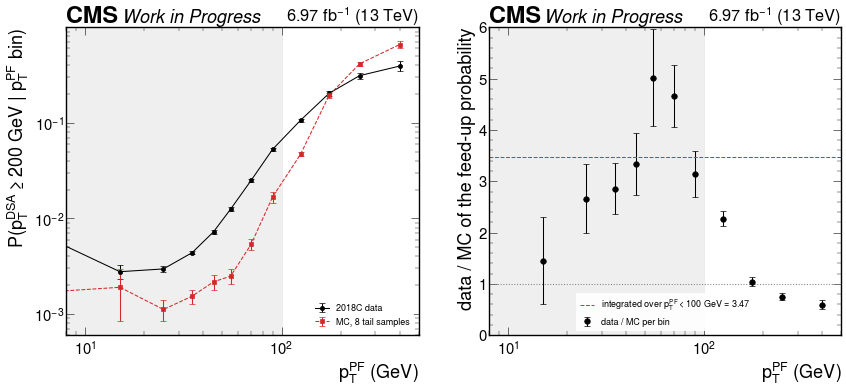

In [27]:
fig, axs = plt.subplots(1, 2, figsize=(20, 8))
centres = 0.5 * (pf_e[1:] + pf_e[:-1])
p_data, e_data, p_mc, e_mc_ = [], [], [], []
for j in range(1, len(pf_e)):
    dnum, dden = dv_f[j, i_ds+1:].sum(), dv_f[j, :].sum()
    mnum, mden = mv_f[j, i_ds+1:].sum(), mv_f[j, :].sum()
    p_data.append(dnum / dden if dden else np.nan)
    e_data.append(math.sqrt(dnum) / dden if dden else np.nan)
    p_mc.append(mnum / mden if mden else np.nan)
    e_mc_.append((mnum / mden) * math.sqrt(me_f[j, i_ds+1:].sum() / mnum ** 2
                                           + me_f[j, :].sum() / mden ** 2)
                 if (mden and mnum > 0) else np.nan)
axs[0].errorbar(centres, p_data, yerr=e_data, fmt="o-", color="k", capsize=4,
                label="2018C data")
axs[0].errorbar(centres, p_mc, yerr=e_mc_, fmt="s--", color="tab:red", capsize=4,
                label="MC, 8 tail samples")
axs[0].set_yscale("log")
axs[0].set_ylabel(r"P($p_T^{DSA} \geq 200$ GeV | $p_T^{PF}$ bin)")
axs[1].errorbar(fu_x, fu_r, yerr=fu_er, fmt="o", color="k", capsize=4, markersize=8,
                label="data / MC per bin")
axs[1].axhline(FU["ratio"], color="tab:blue", linestyle="--",
               label=f"integrated over $p_T^{{PF}} < 100$ GeV = {FU['ratio']:.2f}")
axs[1].axhline(1.0, color="grey", linestyle=":")
axs[1].set_ylabel("data / MC of the feed-up probability")
axs[1].set_ylim(0, 6)
for ax in axs:
    ax.axvspan(0, 100, color="grey", alpha=0.12)
    ax.set_xscale("log")
    ax.set_xlim(8, 500)
    ax.set_xlabel(r"$p_T^{PF}$ (GeV)")
    ax.legend(fontsize=13, frameon=True, facecolor="white", edgecolor="none",
              framealpha=0.92)
    hep.cms.label(data=True, lumi=LUMI_DATA, text="Work in Progress", ax=ax)
plt.show()
plt.close()

In [28]:
# Does the measured feed-up rate account for the LJ DSA tail? The test is a ratio of two
# RATES, each measured entirely within one sample, so the control region's normalization
# mismatch (section 3.1) and the eight-sample set's missing bulk (section 5) cancel out of it.
NH = "mu_lj_dsaMuon_pt_nHits"
lj = {}
for ch, clab in ((CH_BEFORE, "Before"), (CH_SPREAD, "Spread+cosAlpha")):
    dv_ = dview(NH, ch)[0]
    mv_, mvar_ = mview(NH, ch)
    lj[clab] = dict(d_tot=dv_.sum(), d_tail=prof(dv_, TAIL).sum(),
                    m_tot=mv_.sum(), m_tail=prof(mv_, TAIL).sum(),
                    m_tail_e=math.sqrt(prof(mvar_, TAIL).sum()))

print("LJ DSA-muon tail rate against the matched feed-up rate measured above.")
print("The two populations have different true-pT spectra, so this is a scale test, not a")
print("proof - but data and MC are held to exactly the same test.\n")
print(f"  {'':22s} {'N(tail)':>9s} {'N(all)':>10s} {'tail rate':>11s} "
      f"{'feed-up rate':>13s} {'ratio':>16s}")
CLOS = {}
for clab in ("Before", "Spread+cosAlpha"):
    for who, tail, tail_e, tot_, rate, rate_e in (
            ("data", lj[clab]["d_tail"], math.sqrt(lj[clab]["d_tail"]),
             lj[clab]["d_tot"], FU["p_d"], FU["e_d"]),
            ("MC  ", lj[clab]["m_tail"], lj[clab]["m_tail_e"],
             lj[clab]["m_tot"], FU["p_m"], FU["e_m"])):
        rr = tail / tot_ / rate
        err = rr * math.sqrt((tail_e / tail) ** 2 + (rate_e / rate) ** 2)
        CLOS[(clab, who.strip())] = (rr, err)
        print(f"  {clab:16s} {who}  {tail:9.1f} {tot_:10.1f} {tail/tot_:11.3e} "
              f"{rate:13.3e} {rr:9.3f} +/-{err:5.3f}")

print("\nThe four closure numbers, and what each one says:")
print(f"  data, post-veto : {CLOS[('Spread+cosAlpha','data')][0]:.3f} "
      f"+/- {CLOS[('Spread+cosAlpha','data')][1]:.3f}  the surviving tail is the size the "
      f"data's OWN feed-up rate predicts")
print(f"  MC,   post-veto : {CLOS[('Spread+cosAlpha','MC')][0]:.3f} "
      f"+/- {CLOS[('Spread+cosAlpha','MC')][1]:.3f}  the same test inside simulation")
print(f"  MC,   pre-veto  : {CLOS[('Before','MC')][0]:.3f} "
      f"+/- {CLOS[('Before','MC')][1]:.3f}  MC self-closure; MC has no cosmics to remove")
print(f"  data, pre-veto  : {CLOS[('Before','data')][0]:.3f} "
      f"+/- {CLOS[('Before','data')][1]:.3f}  misses by the cosmic population")
print("  The MC numbers stand on a tail of ~35 effective MC events, hence the ~18% errors:")
print("  they are consistent with the MC tail being pure feed-up and equally consistent with")
print("  a second component of up to about a third of it.")

print("\nWhy the 'predicted vs measured tail data/MC' form of this statement is NOT used:")
pred = (lj["Spread+cosAlpha"]["d_tot"] / lj["Spread+cosAlpha"]["m_tot"]) * FU["ratio"]
meas, e_meas = ratio_err(lj["Spread+cosAlpha"]["d_tail"], lj["Spread+cosAlpha"]["d_tail"],
                         lj["Spread+cosAlpha"]["m_tail"], lj["Spread+cosAlpha"]["m_tail_e"] ** 2)
print(f"  pred = (N_data/N_MC) x feed-up ratio = "
      f"{lj['Spread+cosAlpha']['d_tot']/lj['Spread+cosAlpha']['m_tot']:.3f} x "
      f"{FU['ratio']:.3f} = {pred:.3f}, against a measured {meas:.3f} +/- {e_meas:.3f}.")
print(f"  pred / meas = {pred/meas:.4f}, which is ALGEBRAICALLY IDENTICAL to")
print(f"  (MC closure) / (data closure) = "
      f"{CLOS[('Spread+cosAlpha','MC')][0]/CLOS[('Spread+cosAlpha','data')][0]:.4f}.")
print("  The two forms carry exactly the same information, so 'the prediction agrees with the")
print("  measurement' is not a second, independent check. Worse, N_MC there is the")
print("  eight-sample set's TOTAL yield, which section 5 showed covers 52.8% of the full")
print("  stack, so 0.716 is not a normalization ratio at all.")
_fs_tot  = sum(tot(s, CH_SPREAD, scale=ratio) for s in summed_MC)
_fs_tail = sum(tot(s, CH_SPREAD, 200, scale=ratio) for s in summed_MC)
_d_tot, _d_tail = lj["Spread+cosAlpha"]["d_tot"], lj["Spread+cosAlpha"]["d_tail"]
print(f"  Substituting the full stack: N_data/N_MC = {_d_tot:.0f}/{_fs_tot:.1f} = "
      f"{_d_tot/_fs_tot:.3f}, times {FU['ratio']:.3f} = {_d_tot/_fs_tot*FU['ratio']:.2f},")
print(f"  against a full-stack measured {_d_tail:.0f}/{_fs_tail:.1f} = "
      f"{_d_tail/_fs_tail:.2f}. That substitution is INDICATIVE ONLY: dsa_pf_response was")
print("  never run on the full stack, so the feed-up ratio 3.47 is the eight-sample")
print("  measurement and does not belong beside a full-stack normalization.")

print("\nHow much of the closure is a choice of window? Moving the pT_PF threshold:")
print(f"  {'window':>18s} {'feed-up ratio':>16s} {'data closure':>14s} {'MC closure':>12s}")
for pf_max in (60.0, 100.0, 150.0, 500.0):
    f = feedup(pf_max=pf_max)
    c_d = (lj["Spread+cosAlpha"]["d_tail"] / lj["Spread+cosAlpha"]["d_tot"]) / f["p_d"]
    c_m = (lj["Spread+cosAlpha"]["m_tail"] / lj["Spread+cosAlpha"]["m_tot"]) / f["p_m"]
    print(f"  {'pT_PF < ' + format(pf_max, '.0f'):>18s} "
          f"{f['ratio']:8.3f} +/-{f['e_ratio']:5.3f} {c_d:14.3f} {c_m:12.3f}")

LJ DSA-muon tail rate against the matched feed-up rate measured above.
The two populations have different true-pT spectra, so this is a scale test, not a
proof - but data and MC are held to exactly the same test.

                           N(tail)     N(all)   tail rate  feed-up rate            ratio
  Before           data     2414.0    63040.0   3.829e-02     7.957e-03     4.813 +/-0.130
  Before           MC        133.7    59982.6   2.228e-03     2.291e-03     0.973 +/-0.174
  Spread+cosAlpha  data      309.0    40881.0   7.559e-03     7.957e-03     0.950 +/-0.057
  Spread+cosAlpha  MC        129.5    57091.1   2.269e-03     2.291e-03     0.991 +/-0.181

The four closure numbers, and what each one says:
  data, post-veto : 0.950 +/- 0.057  the surviving tail is the size the data's OWN feed-up rate predicts
  MC,   post-veto : 0.991 +/- 0.181  the same test inside simulation
  MC,   pre-veto  : 0.973 +/- 0.174  MC self-closure; MC has no cosmics to remove
  data, pre-veto  : 4.813 

The control sample says three things.

**The response tail is mismodelled, by a factor between 1.8 and 2.1.** Relative to MC, data
over-produces `r > 2` by 1.806 +/- 0.037 and `r > 5` by 2.126 +/- 0.127. Both use a log-linear
interpolation inside the bin that straddles the threshold: the response axis has only four bins
per decade, and snapping `r > 2` to the nearest edge moves it to 1.88 or 2.24 and changes the
answer by several per cent.

**The mismodelling is not flat, so no single number transports it.** Sliced in `|eta|`, the
`P(r > 2)` ratio varies from 1.07 to 2.18 with a chi2 of 69.8/4 against a constant, the maximum
sitting in `1.2 <= |eta| < 1.8` (in the native 0.1-wide binning the bins near
`|eta| = 1.6-1.8` reach 3.2). Sliced in nHits it varies from 1.19 to 2.01 with a chi2 of
45.5/6. A correction derived here and applied to a differently distributed population carries
that spread as a systematic.

**The surviving tail is the size its own feed-up rate predicts.** The relevant number is the
feed-up probability: a matched muon with `pT_PF < 100` GeV is reconstructed as a
`pT_DSA >= 200` GeV muon 3.474 +/- 0.252 times more often in data than in MC. The statement is a
ratio of two *rates*, each measured within a single sample. It therefore uses no MC
normalization and is untouched by the control region's normalization mismatch (section 3.1) and
by the eight-sample set's missing bulk (section 5):

    data: (post-veto tail rate) / (data feed-up rate) = 0.95 +/- 0.06
    MC:   (post-veto tail rate) / (MC   feed-up rate) = 0.99 +/- 0.18

Both are consistent with one. Before the veto the same test misses by 4.81 +/- 0.13 in data:
that is the cosmic population, which section 7 identified and the veto removes. MC, which has no
cosmics to remove, closes at 0.97 +/- 0.17 before the veto and 0.99 +/- 0.18 after it.

Three things that statement does **not** say.

1. **It is not a per-cent-level MC self-closure.** The MC number is 0.97 +/- 0.17: an
   18%-precision test standing on a tail of 35 effective MC events, and the same test swings
   between 0.57 and 1.35 as the `pT_PF` window moves. It is consistent with the MC high-pT DSA
   tail being resolution feed-up, and equally consistent with a second component contributing
   up to about a third of it. A measurement of this precision cannot establish "in simulation
   the tail *is* feed-up and nothing else".
2. **It is not a prediction that was then confirmed.** An alternative form multiplies the
   feed-up ratio by the eight-sample set's total-yield ratio to "predict" a post-veto tail
   data/MC of 2.49, and compares that with the measured 2.39. The comparison is empty: the two
   sides differ *exactly* by the ratio of the two closure numbers above, so their agreement is
   the same statement written twice, not a second check. It also rests on the eight-sample
   set's total MC yield, which covers 52.8% of the full stack, so its 0.716 is not a
   normalization. Substituting the full stack gives 0.378 x 3.474 = 1.31 against a full-stack
   measured 2.31. Even that is indicative only, since `dsa_pf_response` was never run on the
   full stack and the 3.474 is the eight-sample measurement.
3. **It is not window-independent.** As the `pT_PF` window moves from 500 down to 60 GeV, the
   data closure moves between 0.70 and 1.41 and the MC closure between 0.57 and 1.35, and the
   two move together. The control rate is measured before any veto, on a matched population
   whose true-pT spectrum differs from the lepton jets', and the mismodelling is not flat in
   `|eta|` or nHits.

What can be said, then: the surviving excess is of the size DSA momentum mismeasurement would
produce, at roughly factor-1.5 precision, and no additional source is required to accommodate
it. The raw tail data/MC of 2.4 +/- 0.4 is the weaker of the two statements, because its
denominator carries the normalization mismatch of section 3.1; the rate closure does not.

## 9. Candidate handles

Three ways of acting on the tail were examined. **None of them makes data and MC agree.** Each
is quoted with what it costs, so that the trade can be made explicitly rather than by picking
the cut that looks best on one number.

The signal cost of the hit-count cut needs `mu_lj_dsaMuon_pt_nHits` on signal, which the
180-sample signal run predates. It comes from a 26-sample subset of the same grid, re-run after
that histogram was added (`vtxChi2_signal_2018_nhits`): 13 4Mu and 13 2Mu2E points, five
mediator masses, two dark-photon masses and eleven lifetimes.

In [29]:
NHSIG_DIR = f"{sidm_path}/RunOutputFiles/vtxChi2_signal_2018_nhits"
nh_files  = sorted(glob.glob(f"{NHSIG_DIR}/*.coffea"))
nh_names  = [os.path.basename(f)[:-len(".coffea")] for f in nh_files]

nh_rows = []
flow_audit = dict(total=0.0, pt_uf=0.0, pt_of=0.0, nh_uf=0.0, nh_of=0.0)
for f, n in zip(nh_files, nh_names):
    H = coffea.util.load(f)["out"][n]["hists"]["mu_lj_dsaMuon_pt_nHits"]
    hh = H[{"channel": SIG_REF}]
    v, var = hh.values(flow=True), hh.variances(flow=True)
    pe, ye = hh.axes[0].edges, hh.axes[1].edges
    tail = pt_rows(pe, "tail")
    bulk = pt_rows(pe, "bulk200")
    keep = np.concatenate(([False], ye[:-1] >= 20, [True]))   # nHits >= 20, overflow kept
    sp = H[{"channel": SIG_SPREAD}].values(flow=True)
    fs, m, ma, ct = parse_sample(n)
    flow_audit["total"] += v.sum()
    flow_audit["pt_uf"] += v[0, :].sum();  flow_audit["pt_of"] += v[-1, :].sum()
    flow_audit["nh_uf"] += v[:, 0].sum();  flow_audit["nh_of"] += v[:, -1].sum()
    nh_rows.append(dict(
        name=n, m=m, ma=ma, ct=ct, w=float(v.sum()),
        neff=float(v.sum() ** 2 / var.sum()),
        neff_tail=float(v[tail].sum() ** 2 / var[tail].sum()) if var[tail].sum() else 0.0,
        keep_all=float(v[:, keep].sum() / v.sum()),
        keep_bulk=float(v[bulk][:, keep].sum() / v[bulk].sum()),
        keep_tail=float(v[tail][:, keep].sum() / v[tail].sum()) if v[tail].sum() else np.nan,
        w_tail=float(v[tail].sum()),
        eff_spread=float(sp.sum() / v.sum()),
        keep_after_spread=float(sp[:, keep].sum() / sp.sum()),
    ))

NHW = np.array([r["w"] for r in nh_rows])
wavg = lambda k, w=NHW: float(np.nansum([r[k] for r in nh_rows] * w) / w.sum())
print(f"{len(nh_names)} signal samples in {os.path.basename(NHSIG_DIR)}")
print(f"flow audit over the subset: {flow_audit['total']:.3f} weighted DSA-muon entries; "
      f"pT underflow {flow_audit['pt_uf']:.3f}, pT overflow {flow_audit['pt_of']:.3f} "
      f"(kept in the tail);\n  nHits underflow {flow_audit['nh_uf']:.3f}, nHits overflow "
      f"{flow_audit['nh_of']:.3f} - the nHits overflow is exactly zero grid-wide, so the "
      f">= 20 cut is unambiguous.")

wt = np.array([r["w_tail"] for r in nh_rows])
robust_tail = np.array([r["neff_tail"] >= 200 for r in nh_rows])
kt = np.array([r["keep_tail"] for r in nh_rows], float)
print(f"\nnHits >= 20 keep fraction on signal DSA muons (grid-pooled, weighted entries):")
print(f"  all pT      {wavg('keep_all'):.3f}      (per-sample mean "
      f"{np.mean([r['keep_all'] for r in nh_rows]):.3f})")
print(f"  pT < 200    {wavg('keep_bulk'):.3f}")
print(f"  pT >= 200   {np.nansum(kt * wt) / wt[np.isfinite(kt)].sum():.3f}   "
      f"- only {wt.sum()/NHW.sum():.4f} of signal DSA muons are in the tail")
print(f"  the per-sample tail mean is noise: {int((~robust_tail).sum())} of {len(nh_rows)} "
      f"samples have a tail N_eff < 200.\n  Over the {int(robust_tail.sum())} samples that do "
      f"not, the mean is {np.nanmean(kt[robust_tail]):.3f} "
      f"(median {np.nanmedian(kt[robust_tail]):.3f}).")
print(f"\n  after the Spread veto, the marginal keep of nHits >= 20 is "
      f"{wavg('keep_after_spread'):.3f} (yield-weighted)")

and_exact = np.array([r["eff_spread"] * r["keep_after_spread"] for r in nh_rows])
and_naive = np.array([r["eff_spread"] * r["keep_all"] for r in nh_rows])
print(f"  exact AND of nHits >= 20 and the Spread veto: yield-wtd "
      f"{(and_exact*NHW).sum()/NHW.sum():.4f}   naive product "
      f"{(and_naive*NHW).sum()/NHW.sum():.4f}   ratio "
      f"{(and_exact*NHW).sum()/(and_naive*NHW).sum():.4f}"
      f"   -> the two cuts are very nearly independent on signal")

print("\nkeep fraction by mediator mass and by lifetime (unweighted mean over the subset):")
NHM = np.array([r["m"] for r in nh_rows])
NHC = np.array([r["ct"] for r in nh_rows])
print(f"    {'M (GeV)':>10s} {'n':>3s} {'all pT':>8s} {'pT<200':>8s}")
for u in sorted(set(NHM.tolist())):
    sel = NHM == u
    print(f"    {u:10.0f} {int(sel.sum()):3d} "
          f"{np.mean([r['keep_all'] for r, s in zip(nh_rows, sel) if s]):8.3f} "
          f"{np.mean([r['keep_bulk'] for r, s in zip(nh_rows, sel) if s]):8.3f}")
print(f"    {'ctau (mm)':>10s} {'n':>3s} {'all pT':>8s} {'pT<200':>8s}")
for lab, a, b in (("< 10", 0, 10), ("10 - 100", 10, 100), (">= 100", 100, 1e9)):
    sel = (NHC >= a) & (NHC < b)
    print(f"    {lab:>10s} {int(sel.sum()):3d} "
          f"{np.mean([r['keep_all'] for r, s in zip(nh_rows, sel) if s]):8.3f} "
          f"{np.mean([r['keep_bulk'] for r, s in zip(nh_rows, sel) if s]):8.3f}")

26 signal samples in vtxChi2_signal_2018_nhits
flow audit over the subset: 297.395 weighted DSA-muon entries; pT underflow 0.000, pT overflow 2.270 (kept in the tail);
  nHits underflow 0.000, nHits overflow 0.000 - the nHits overflow is exactly zero grid-wide, so the >= 20 cut is unambiguous.

nHits >= 20 keep fraction on signal DSA muons (grid-pooled, weighted entries):
  all pT      0.854      (per-sample mean 0.861)
  pT < 200    0.850
  pT >= 200   0.920   - only 0.0675 of signal DSA muons are in the tail
  the per-sample tail mean is noise: 16 of 26 samples have a tail N_eff < 200.
  Over the 10 samples that do not, the mean is 0.889 (median 0.912).

  after the Spread veto, the marginal keep of nHits >= 20 is 0.869 (yield-weighted)
  exact AND of nHits >= 20 and the Spread veto: yield-wtd 0.7672   naive product 0.7558   ratio 1.0152   -> the two cuts are very nearly independent on signal

keep fraction by mediator mass and by lifetime (unweighted mean over the subset):
       M 

In [30]:
# Handle 1: nHits >= 20.  Handle 2: sigma(pT)/pT < 0.3.  Both measured on the same data.
NHD = "mu_lj_dsaMuon_pt_nHits"
RPD = "mu_lj_dsaMuon_pt_relPtErr"
yn  = H_tail[NHD][{"channel": CH_BEFORE}].axes[1].edges
yr  = H_tail[RPD][{"channel": CH_BEFORE}].axes[1].edges
keep_n = np.concatenate(([False], yn[:-1] >= 20, [True]))
keep_r = np.concatenate(([False], yr[:-1] < RELPT_CUT, [False]))

print("Effect of each handle on the post-Spread-veto sample (data, and MC where available).")
print("'bulk' is pT < 100 GeV for the hit-count row and pT < 200 GeV for the resolution row;")
print("both are stated because that is how each was measured.\n")

dv_n, dvar_n = dview(NHD, CH_SPREAD)
mv_n, mvar_n = mview(NHD, CH_SPREAD)
t_d, t_dv = prof(dv_n, TAIL), prof(dvar_n, TAIL)
t_m, t_mv = prof(mv_n, TAIL), prof(mvar_n, TAIL)
r_before, e_before = ratio_err(t_d[1:-1].sum(), t_dv[1:-1].sum(),
                               t_m[1:-1].sum(), t_mv[1:-1].sum())
r_after, e_after = ratio_err(t_d[keep_n].sum(), t_dv[keep_n].sum(),
                             t_m[keep_n].sum(), t_mv[keep_n].sum())
b_d, b_m = prof(dv_n, BULK100), prof(mv_n, BULK100)
print(f"nHits >= 20")
print(f"  tail data {t_d[1:-1].sum():.0f} -> {t_d[keep_n].sum():.0f}"
      f"   ({100*t_d[keep_n].sum()/t_d[1:-1].sum():.1f}% kept)")
print(f"  tail MC   {t_m[1:-1].sum():.2f} -> {t_m[keep_n].sum():.2f}"
      f"   ({100*t_m[keep_n].sum()/t_m[1:-1].sum():.1f}% kept)")
print(f"  tail data/MC {r_before:.3f} +/- {e_before:.3f}  ->  {r_after:.3f} +/- {e_after:.3f}")
print(f"  bulk (pT < 100 GeV) kept: data {100*b_d[keep_n].sum()/b_d[1:-1].sum():.1f}%   "
      f"MC {100*b_m[keep_n].sum()/b_m[1:-1].sum():.1f}%"
      f"   -> the cut costs {100 - 100*b_d[keep_n].sum()/b_d[1:-1].sum():.1f}% of the data "
      f"bulk against {100 - 100*b_m[keep_n].sum()/b_m[1:-1].sum():.1f}% of the MC bulk")

dv_r2, dvar_r2 = dview(RPD, CH_SPREAD)
mv_r2, mvar_r2 = mview(RPD, CH_SPREAD)
t_d2, t_m2 = prof(dv_r2, TAIL), prof(mv_r2, TAIL)
b_d2, b_m2 = prof(dv_r2, BULK200), prof(mv_r2, BULK200)
print(f"\nsigma(pT)/pT < {RELPT_CUT}")
print(f"  tail kept: data {t_d2[keep_r].sum()/t_d2[1:-1].sum():.3f}   "
      f"MC {t_m2[keep_r].sum()/t_m2[1:-1].sum():.3f}"
      f"   -> it removes {100*(1 - t_d2[keep_r].sum()/t_d2[1:-1].sum()):.0f}% of the data tail")
print(f"  bulk (pT < 200 GeV) kept: data {b_d2[keep_r].sum()/b_d2[1:-1].sum():.3f}   "
      f"MC {b_m2[keep_r].sum()/b_m2[1:-1].sum():.3f}")
print(f"  the cut keeps MORE of the MC tail than of the data tail, so it moves the ratio "
      f"in the wrong direction")

print(f"\nsignal survival of sigma(pT)/pT < {RELPT_CUT}, from the 180-sample grid:")
print(f"  all 180    : mean {S['surv'].mean():.3f}  median {np.median(S['surv']):.3f}  "
      f"yield-wtd {(S['surv']*WSIG).sum()/WSIG.sum():.3f}")
print(f"  N_eff>=200 : mean {S['surv'][robust].mean():.3f}  "
      f"median {np.median(S['surv'][robust]):.3f}")
print(f"  by mediator mass (robust): "
      + "  ".join(f"{u:.0f} GeV {S['surv'][robust & (S['m'] == u)].mean():.3f}"
                  for u in sorted(set(S["m"].tolist()))))
print(f"  by m_Zd (robust)         : "
      + "  ".join(f"{u:g} GeV {S['surv'][robust & (S['ma'] == u)].mean():.3f}"
                  for u in sorted(set(S["ma"].tolist()))))
naive_rp = S["surv"] * S["dsa_sp"]
print(f"  exact AND with the Spread veto: yield-wtd "
      f"{(S['surv_and']*WSIG).sum()/WSIG.sum():.4f}   naive product "
      f"{(naive_rp*WSIG).sum()/WSIG.sum():.4f}")
print(f"  over the robust subset, exact AND - naive product: mean "
      f"{np.mean((S['surv_and'] - naive_rp)[robust]):+.4f}, largest "
      f"{np.abs((S['surv_and'] - naive_rp)[robust]).max():.4f}  -> the two cuts are very "
      f"nearly independent on signal")

Effect of each handle on the post-Spread-veto sample (data, and MC where available).
'bulk' is pT < 100 GeV for the hit-count row and pT < 200 GeV for the resolution row;
both are stated because that is how each was measured.

nHits >= 20
  tail data 309 -> 183   (59.2% kept)
  tail MC   129.54 -> 113.98   (88.0% kept)
  tail data/MC 2.385 +/- 0.426  ->  1.605 +/- 0.328
  bulk (pT < 100 GeV) kept: data 75.5%   MC 85.9%   -> the cut costs 24.5% of the data bulk against 14.1% of the MC bulk

sigma(pT)/pT < 0.3
  tail kept: data 0.084   MC 0.145   -> it removes 92% of the data tail
  bulk (pT < 200 GeV) kept: data 0.808   MC 0.882
  the cut keeps MORE of the MC tail than of the data tail, so it moves the ratio in the wrong direction

signal survival of sigma(pT)/pT < 0.3, from the 180-sample grid:
  all 180    : mean 0.761  median 0.790  yield-wtd 0.770
  N_eff>=200 : mean 0.752  median 0.780
  by mediator mass (robust): 100 GeV 0.892  150 GeV 0.886  200 GeV 0.868  500 GeV 0.740  800 GeV 

**How to read Figure 14:** the signal cost of the two object-level handles, one point per
sample against mediator mass. Left, the survival of `sigma(pT)/pT < 0.3` over the full
180-sample grid; right, the keep fraction of `nHits >= 20` over the 26-sample subset. Open
markers are samples whose effective entry count is below 200. The scattered markers are
simulation, which is what the *Simulation Work in Progress* stamp refers to. The dashed
reference line on each panel is not simulation: it is the same cut applied to the 2018C data
bulk, i.e. what the cut removes from normal, well-measured muons, and its legend entry says so.

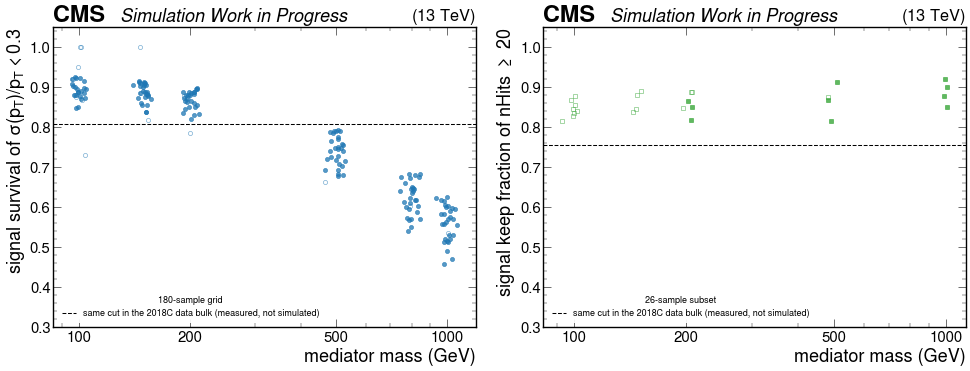

In [31]:
fig, axs = plt.subplots(1, 2, figsize=(20, 8))
jit = lambda a: a * (1 + 0.03 * np.random.default_rng(0).standard_normal(len(a)))

ax = axs[0]
for sel, style in ((robust, dict(marker="o", alpha=0.75)),
                   (~robust, dict(marker="o", markerfacecolor="none", alpha=0.6))):
    ax.plot(jit(S["m"][sel]), S["surv"][sel], linestyle="none", color="tab:blue", **style)
ax.axhline(b_d2[keep_r].sum()/b_d2[1:-1].sum(), color="k", linestyle="--",
           label="same cut in the 2018C data bulk (measured, not simulated)")
ax.set_ylabel(r"signal survival of $\sigma(p_T)/p_T < 0.3$")
titles = ["180-sample grid", "26-sample subset"]

ax = axs[1]
NHR = np.array([r["neff_tail"] >= 200 for r in nh_rows])
ka  = np.array([r["keep_all"] for r in nh_rows])
for sel, style in ((NHR, dict(marker="s", alpha=0.75)),
                   (~NHR, dict(marker="s", markerfacecolor="none", alpha=0.6))):
    ax.plot(jit(NHM[sel]), ka[sel], linestyle="none", color="tab:green", **style)
ax.axhline(b_d[keep_n].sum()/b_d[1:-1].sum(), color="k", linestyle="--",
           label="same cut in the 2018C data bulk (measured, not simulated)")
ax.set_ylabel(r"signal keep fraction of nHits $\geq$ 20")

for ax in axs:
    ax.set_xscale("log")
    ax.set_xlabel("mediator mass (GeV)")
    ax.set_ylim(0.3, 1.05)
    ax.set_xticks([100, 200, 500, 1000])
    ax.set_xticklabels(["100", "200", "500", "1000"])
    ax.legend(fontsize=13, loc="lower left", title=titles.pop(0), title_fontsize=13,
              frameon=True, facecolor="white", edgecolor="none", framealpha=0.92)
    hep.cms.label(data=False, text="Work in Progress", ax=ax)
plt.tight_layout()
plt.show()
plt.close()

### 9.1 `nHits >= 20`

The most effective of the three on the ratio, and the one with the clearest cost. It takes the
post-veto tail data/MC from 2.385 +/- 0.43 to 1.605 +/- 0.33, because it removes 40.8% of the
data tail and only 12% of the MC tail. It does not remove the discrepancy: the `nHits < 20`
part it removes carries 110.4 of the tail's 179.5-event data excess over MC (section 6).

The cost is that it cuts on a variable that data and MC disagree about at the 15-sigma level in
the bulk, the caveat of section 6. It removes 24.5% of the data bulk against 14.1% of the MC
bulk, so adopting it would require a scale factor to be measured and carried, not just the cut.
On signal it costs about 15%: pooled over the 26-sample subset it keeps 0.854 of the signal DSA
muons at all pT and 0.850 below 200 GeV. It is cheaper on the signal muons that land in the
tail, 0.92, an 8% cost, but only 6.75% of signal DSA muons are in that tail, so 15% is the
number that matters and the 8% must never be quoted on its own. The keep fraction rises gently
with mediator mass, from 0.845 at 100 GeV to 0.887 at 1 TeV, and is flat in lifetime, so it
needs no lifetime-dependent modelling. Applied after the Spread veto its marginal keep is 0.869;
the two cuts are very nearly independent on signal (the exact AND exceeds the naive product of
the two efficiencies by 1.5%).

### 9.2 `sigma(pT)/pT < 0.3`

The most aggressive of the three, and the least useful. It removes 92% of the post-veto data
tail while costing 19% of the bulk. But it keeps 0.145 of the MC tail against 0.084 of the data
tail, i.e. it cuts *harder* on data than on MC, so it moves the ratio in the wrong direction.
Its real cost is on signal: the survival averaged over the robust grid is 0.752, driven almost
entirely by mediator mass, from 0.892 at 100 GeV down to 0.560 at 1 TeV, where the muons are
stiffest and their fractional momentum error largest. It is essentially independent of the
Spread veto (the exact AND and the naive product differ by less than 2%). At a 1 TeV mediator it
costs 44% of the signal.

### 9.3 The DSA-PF control as a data-driven correction

The third option is not a cut. Section 8 measures the DSA momentum-mismeasurement rate in data
and in MC on an independent, matched sample, so it can *size* a correction or an uncertainty on
the DSA high-pT rate instead of removing events. That is the option most compatible with the
analysis, since it costs no signal at all.

Its limitation is the non-flatness: the `P(r > 2)` ratio varies by a factor 2 across `|eta|`
(chi2 69.8/4) and by 1.7 across nHits (chi2 45.5/6). A single global factor would carry a large
systematic, and a binned correction would need more control statistics than one era of
`DoubleMuon` provides. Section 10 tests this correction on the full 2018 sample, as a
transfer-factor fold, and it fails its MC self-closure.

### 9.4 What is missing to go further

Three histograms would settle the questions left open above, and none of them is expensive:

- **`phi` x `nHits`** in the tail. This is the important one. It would say directly whether the
  126 low-nHits survivors carry a cosmic vertical excess, which the inclusive limit of section 7
  cannot exclude at the 15% level within that subset.
- **`|eta|` x `nHits`** (or a three-dimensional `pT` x `|eta|` x `nHits`). The
  inclusion-exclusion bound of section 6 shows that at least 17% of the excess must be both
  endcap and low-nHits, but the overlap itself is not measurable from the two one-dimensional
  splits.
- **`mu_lj_dsaMuon_pt_nHits` on the full 180-sample signal grid**, so that the signal cost of a
  hit-count cut rests on the whole grid rather than on a 26-sample subset chosen for
  statistics.

The first two are booked in the full-2018 outputs of section 10, and section 10.4 reads
them; the third was not run.

## 10. Folding the control-sample transfer factor onto the lepton jets' own low-pT muons

**What this section does.** It takes the DSA momentum-mismeasurement rate measured on the
control sample of section 8, folds it onto the lepton jets' own low-pT DSA spectrum, and tests
whether the resulting prediction matches the observed high-pT tail. It uses the full 2018 sample
and three channels: no veto (`cr_1egmOr1mu_lj`), the Spread veto
(`cr_1egmOr1mu_lj_spreadMu_spreadPfMu_CosMu`) and the vertex veto
(`cr_1egmOr1mu_lj_vtxChi2_CosMu`), both vetoes with the cosAlpha cut.

**The method in eight lines.**

1. Section 8 measured the DSA momentum-mismeasurement rate on the matched control sample and
   compared it with the tail rate. This section instead *folds* that rate onto a spectrum: it
   predicts the measured spectrum from a true one.
2. Book the migration matrix `M[i,j]`: matched control muons whose PF (true-proxy) `pT` is in
   bin `i` and whose DSA `pT` is measured in bin `j`, per channel and per slice of `|eta|` or of
   hit count.
3. Normalize it row by row into the **transfer factor** `T(j|i) = M[i,j] / sum_k M[i,k]`: the
   probability that a muon of true `pT` bin `i` is measured in bin `j`.
4. Take the lepton jets' **own** low-`pT` DSA spectrum, same channel and same slice, as the
   source population `N_true(i)`, restricted to `pT < 100` GeV.
5. That source spectrum is itself DSA-measured, so unfold it with the same `T`, with three iterations of
   expectation-maximization (iterative Bayesian) unfolding, before use.
6. Predict `Pred(j) = sum_i T(j|i) N_true(i)` for the tail (`pT >= 200` GeV, overflow
   included) and for the `[100, 200)` GeV sideband.
7. Close: `R = Obs/Pred - 1`. Both terms are formed inside one sample, so neither the
   luminosity nor the control region's normalization mismatch of section 3.1 enters `R`.
8. Repeat the whole chain on MC alone, with the MC control and the MC source spectrum (the
   **MC self-closure**, `R_MC = Obs_MC/Pred_MC - 1`); repeat it with the vertex veto in place of
   the Spread veto; and test the sideband, where the prediction is required to fall *below* the
   data.

Line 8 is the load-bearing one. The matched control is a **lower bound by construction**. A
control muon has a PF partner and is therefore better measured than one the cross-cleaning threw
away, so `T_control <= T_LJ` and `Pred` should under-predict everywhere. In the sideband (SB),
`Pred_SB <= Obs_SB` is therefore a necessary condition for the fold to be believable at all.

**Two control definitions are compared.** The **dR-matched** control pairs each DSA muon with
the nearest PF muon within `dR < 0.2`. The **segment-matched** control, used for every number
below unless stated, pairs it with the PF muon that the analysis's own segment-based
cross-cleaning removes it against, i.e. the muon a muon-type lepton jet actually loses. In the
Spread-veto channel the segment-matched control holds 9.2% fewer muons than the dR-matched one
(2.95 million against 3.24 million entries), and its inclusive feed-up rate
`T(pT_DSA >= 200 GeV | pT_PF < 100 GeV)` is 4.4% lower (7.93e-3 against 8.29e-3). When several
PF muons qualify for the same DSA muon (1.2% of control muons), the choice of partner changes
`T` by 3e-4 relative, three orders of magnitude below the statistical precision, so the
tie-break is not a source of uncertainty. Both controls read the full 2018A-D `DoubleMuon` data
(59.83/fb, all 68 skimmed samples) and the same 8 MC samples. Values for the dR-matched control
are quoted as "(dR-matched: x)".

**Where the inputs are.** The fold was run by a script that is not in the repository. Its three
JSON records are in `transfer_factor/` next to this notebook: `tf_transfer_factor_seg68.json`
(segment-matched control), `tf_transfer_factor_full68.json` (dR-matched control) and
`tf_seg_aux.json` (control sizes, tie-break and the halo diagnostics of section 10.4);
`transfer_factor/README.md` describes their contents. The segment-matched records come from the
outputs of `runDataSegMatch2018.ipynb` and `runMCRespSegMatch2018.ipynb` (`vtxResp2_2018Full`
and `vtxRespMC2_2018`). The dR-matched ones come from the same 68 data samples and the same 8 MC
samples, in the outputs of `runDataFull2018.ipynb` (`vtxResp_2018Full`) and
`runMCRespFull.ipynb` (`vtxRespMC_2018`). All four are under `RunOutputFiles/`. The cells below
re-read the JSON records and recompute every plotted number from them. The `phi` x `nHits` and
`|eta|` x `nHits` table and figure are recomputed directly from the segment-matched data
`.coffea` files, over exactly the 68 data samples the fold used.

In [32]:
TF_DIR = "transfer_factor"          # next to this notebook
TF_JSON = os.path.join(TF_DIR, "tf_transfer_factor_seg68.json")
TF_DR_JSON = os.path.join(TF_DIR, "tf_transfer_factor_full68.json")
AUX_JSON = os.path.join(TF_DIR, "tf_seg_aux.json")
RESP_DIR = f"{sidm_path}/RunOutputFiles/vtxResp2_2018Full"

with open(TF_JSON) as fh:
    TF = json.load(fh)
with open(TF_DR_JSON) as fh:
    TF_DR = json.load(fh)
with open(AUX_JSON) as fh:
    AUX = json.load(fh)
PROV = TF["provenance"]
L_TF = round(PROV["L_data_fb"], 1)
print(PROV["header"])
print(f"MC samples folded: {len(PROV['mc_present'])}, missing {len(PROV['mc_missing'])}")

# Intro-paragraph numbers, both control definitions, Spread-veto channel.
cs = AUX["control_sizes"]["spread_veto"]
tb = AUX["tiebreak"]["spread_veto"]
t_seg = cs["seg_feedup_num"] / cs["seg_src"]
t_dr = cs["dR_feedup_num"] / cs["dR_src"]
print(f"\nSpread-veto channel, control muons: seg {cs['seg']:,.0f}   dR {cs['dR']:,.0f}   "
      f"({100 * (1 - cs['ratio']):.1f}% fewer with segment matching)")
print(f"inclusive feed-up rate T(pT_DSA>=200|pT_PF<100): seg {t_seg:.2e}   dR {t_dr:.2e}   "
      f"({100 * (1 - t_seg / t_dr):.1f}% lower)")
print(f"multi-partner control muons: {100 * tb['f_multiPartner']:.1f}%;  "
      f"tie-break relative shift on T: {tb['rel_shift']:.1e}")

68/68 chunks (A 3/3, B 14/14, C 1/1, D 50/50); f_files=1.0000; L_data~59.83/fb of 59.83 (1.000) [external era table, not in repo]; MC 8/8, missing: none
MC samples folded: 8, missing 0

Spread-veto channel, control muons: seg 2,945,527   dR 3,243,506   (9.2% fewer with segment matching)
inclusive feed-up rate T(pT_DSA>=200|pT_PF<100): seg 7.93e-03   dR 8.29e-03   (4.4% lower)
multi-partner control muons: 1.2%;  tie-break relative shift on T: 2.9e-04


In [33]:
# (display label, slicing axis, slice index, key used by the transfer-matrix table)
SLICES = [("|eta| 0.0-0.9", "abseta", 0, "|eta| 0.0-0.9"),
          ("|eta| 0.9-1.2", "abseta", 1, "|eta| 0.9-1.2"),
          ("|eta| 1.2-2.4", "abseta", 2, "|eta| 1.2-2.4"),
          ("nHits 0-20",    "nHits",  0, "nHits 0-20"),
          ("nHits 20-30",   "nHits",  1, "nHits 20-30"),
          ("nHits 30-60",   "nHits",  2, "nHits 30-60(+OF)")]
XLAB = [s[0] for s in SLICES]
N_SRC = 5          # the five pT_PF source rows below 100 GeV that feed the fold
REGIONS = [("spread_veto", "Spread veto + cosAlpha"),
           ("vertex_veto", "vertex veto + cosAlpha")]
VETO = {"no_veto": "none", "spread_veto": "Spread", "vertex_veto": "vertex"}   # channel keys of the JSON records
VETO_NAME = {"no_veto": "no veto", "spread_veto": "Spread veto", "vertex_veto": "vertex veto"}
TARGETS = [("TAIL", r"DSA $p_T \geq 200$ GeV (overflow in)"),
           ("SB",   r"sideband  $100 \leq p_T < 200$ GeV")]
XS = np.arange(len(SLICES))
FS = 18            # in-figure text: 18 pt at a 16-inch width is 8.4 pt at text width
FIG_DPI = 72       # the style default renders about 43 dpi inline, too coarse to read an
                   # eight-panel figure; the three figures below override it


def tf_cell(reg, slicing, idx, tgt, src=None):
    return (src if src is not None else TF)["closure"][f"{reg}/{slicing}/{idx}/{tgt}"]


def tf_syst(e):
    """The three systematic terms of Pred: circularity, binning, channel transport."""
    return math.hypot(math.hypot(e["sig_circ"], e["sig_bin"]), e["sig_chan"])


def tf_col(reg, tgt, key, src=None):
    """One column of the closure table, in SLICES order."""
    return np.array([key(tf_cell(reg, s, i, tgt, src)) for _l, s, i, _t in SLICES], float)


print(f"\n{'veto':7s} {'slice':14s} {'tgt':5s} {'Obs':>6s} {'Pred':>8s} {'+-stat':>7s} "
      f"{'+-syst':>7s} {'R':>7s} {'+-full':>7s} {'R_MC':>7s} {'+-':>6s} {'NeffMC':>7s}")
for reg, _ in REGIONS:
    for tgt, _ in TARGETS:
        for lab, s, i, _t in SLICES:
            e = tf_cell(reg, s, i, tgt)
            print(f"{VETO[reg]:7s} {lab:14s} {tgt:5s} {e['obs']:6.0f} {e['pred']:8.1f} "
                  f"{e['stat']:7.1f} {tf_syst(e):7.1f} {e['R']:+7.3f} {e['sR_full']:7.3f} "
                  f"{e['R_mc']:+7.3f} {e['sR_mc']:6.3f} {e['neff_mc']:7.1f}")

inc = TF["inclusive_closure"]
for reg in ("spread_veto", "vertex_veto"):
    d = inc[reg]
    print(f"\n{VETO_NAME[reg]}, inclusive TAIL: obs {d['obs_tl']:.0f} vs pred "
          f"{[f'{p:.0f}' for p in d['pred_tl']]} (sum|eta|, sum nHits, native) "
          f"+/-{d['sigma_bin_tl']:.0f}")
    print(f"{VETO_NAME[reg]}, inclusive SB  : obs {d['obs_sb']:.0f} vs pred "
          f"{[f'{p:.0f}' for p in d['pred_sb']]} +/-{d['sigma_bin_sb']:.0f}")

fails = TF["sideband_transport_failures"]
fails_dr = TF_DR["sideband_transport_failures"]
n3 = sum(1 for f in fails if abs(f["z_stat"]) >= 3)
n3_dr = sum(1 for f in fails_dr if abs(f["z_stat"]) >= 3)
print(f"\nsideband slices where Pred_SB > Obs_SB (the direction the method forbids): "
      f"{len(fails)} of 18 segment-matched, {len(fails_dr)} of 18 dR-matched")
print(f"  of those, beyond 3 sigma_stat: {n3} segment-matched, {n3_dr} dR-matched")
for f in fails:
    _reg, _axis, _slc = f["slice"].split("/", 2)
    print(f"    {VETO_NAME[_reg] + ', ' + _slc:30s} R = {f['R']:+.3f}  "
          f"({f['z_stat']:+.1f} sigma_stat)")

# The numbers of section 10.5: the MC self-closure of the nHits < 20 tail with the Spread veto,
# for both controls, and the data closure of the same slice with no veto.
e_sp = tf_cell("spread_veto", "nHits", 0, "TAIL")
e_dr = tf_cell("spread_veto", "nHits", 0, "TAIL", TF_DR)
e_nv = tf_cell("no_veto", "nHits", 0, "TAIL")
print(f"\nSpread veto, nHits 0-20, TAIL: R_MC = {e_sp['R_mc']:+.3f} +/- {e_sp['sR_mc']:.3f} "
      f"({abs(e_sp['R_mc']) / e_sp['sR_mc']:.1f} sigma), Pred_MC/Obs_MC = "
      f"{1 / (1 + e_sp['R_mc']):.2f};  dR-matched: R_MC = {e_dr['R_mc']:+.3f} "
      f"+/- {e_dr['sR_mc']:.3f}, Pred_MC/Obs_MC = {1 / (1 + e_dr['R_mc']):.2f}")
print(f"no veto,     nHits 0-20, TAIL: Obs {e_nv['obs']:.0f}, Pred {e_nv['pred']:.1f}, "
      f"R = {e_nv['R']:+.3f} +/- {e_nv['sR_full']:.3f}")


veto    slice          tgt      Obs     Pred  +-stat  +-syst       R  +-full    R_MC     +-  NeffMC
Spread  |eta| 0.0-0.9  TAIL    1491   1097.3    12.4   178.1  +0.359   0.167  +1.170  0.558    20.7
Spread  |eta| 0.9-1.2  TAIL     270    253.7     6.8    53.6  +0.064   0.223  +0.528  0.452    20.1
Spread  |eta| 1.2-2.4  TAIL    1123    978.9    13.8   116.4  +0.147   0.125  +0.079  0.364    11.9
Spread  nHits 0-20     TAIL    1032   1067.5    16.0   102.5  -0.033   0.102  -0.592  0.104    34.3
Spread  nHits 20-30    TAIL    1217   1120.7    14.1   119.8  +0.086   0.112  +1.115  0.595    16.8
Spread  nHits 30-60    TAIL     635    320.9     6.1    58.8  +0.979   0.203  +2.168  1.136    10.7
Spread  |eta| 0.0-0.9  SB      6154   5216.1    40.6   739.2  +0.180   0.143  +0.135  0.099   270.8
Spread  |eta| 0.9-1.2  SB      1228   1236.4    20.0   198.5  -0.007   0.164  -0.016  0.170    62.7
Spread  |eta| 1.2-2.4  SB      3287   3409.0    33.9   339.7  -0.036   0.102  +0.151  0.225    34.4

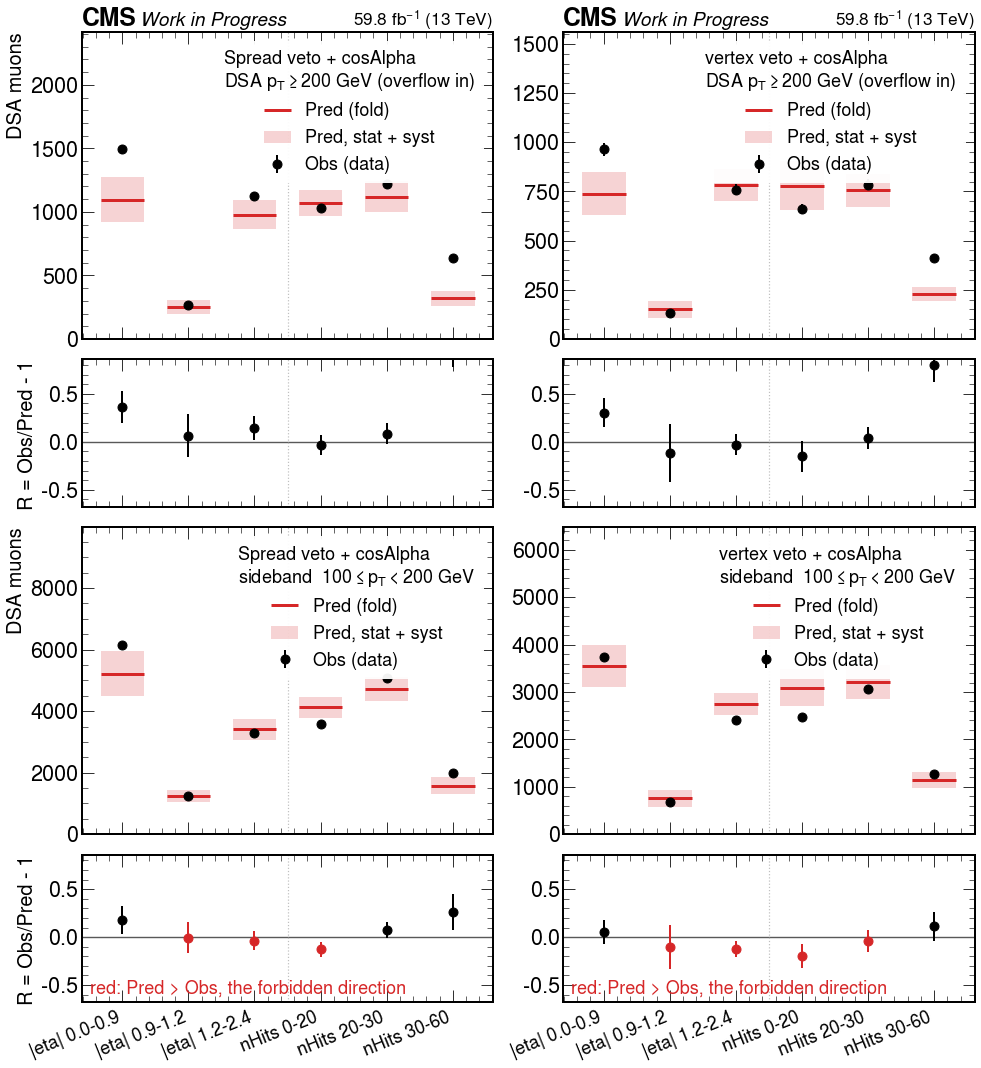

In [34]:
# Figure: closure per slice, both vetoes, tail and sideband.  Top row of each pair is the
# yield with the fold's own uncertainty band; bottom row is R = Obs/Pred - 1.  Red marks the
# sideband slices that fail the direction test Pred_SB <= Obs_SB.
fig = plt.figure(figsize=(16, 17.5))
gs = fig.add_gridspec(4, 2, height_ratios=[2.6, 1.25, 2.6, 1.25], hspace=0.09, wspace=0.17)
tf_top = []
for ci, (reg, rlab) in enumerate(REGIONS):
    for ti, (tgt, tlab) in enumerate(TARGETS):
        axy = fig.add_subplot(gs[2 * ti, ci])
        axr = fig.add_subplot(gs[2 * ti + 1, ci], sharex=axy)
        obs = tf_col(reg, tgt, lambda e: e["obs"])
        pred = tf_col(reg, tgt, lambda e: e["pred"])
        err = np.hypot(tf_col(reg, tgt, lambda e: e["stat"]), tf_col(reg, tgt, tf_syst))
        R = tf_col(reg, tgt, lambda e: e["R"])
        sR = tf_col(reg, tgt, lambda e: e["sR_full"])
        axy.bar(XS, 2 * err, bottom=pred - err, width=0.66, color="tab:red", alpha=0.20,
                lw=0, label="Pred, stat + syst")
        axy.hlines(pred, XS - 0.33, XS + 0.33, color="tab:red", lw=3, label="Pred (fold)")
        axy.errorbar(XS, obs, yerr=np.sqrt(obs), fmt="ko", ms=9, lw=2, label="Obs (data)")
        axy.set_ylim(0, 1.62 * max(obs.max(), (pred + err).max()))
        axy.axvline(2.5, color="0.75", lw=1.2, ls=":")
        axy.tick_params(labelbottom=False)
        axy.legend(fontsize=FS, loc="upper right", frameon=True, facecolor="white",
                   edgecolor="none", framealpha=0.95, title=f"{rlab}\n{tlab}",
                   title_fontsize=FS)
        if ci == 0:
            axy.set_ylabel("DSA muons", fontsize=20)
        bad = (R < 0) if tgt == "SB" else np.zeros_like(R, bool)
        axr.axhline(0.0, color="0.35", lw=1.4)
        axr.errorbar(XS[~bad], R[~bad], yerr=sR[~bad], fmt="ko", ms=9, lw=2)
        axr.errorbar(XS[bad], R[bad], yerr=sR[bad], fmt="o", ms=9, lw=2, color="tab:red")
        axr.axvline(2.5, color="0.75", lw=1.2, ls=":")
        axr.set_ylim(-0.68, 0.86)
        axr.set_xticks(XS)
        if ci == 0:
            axr.set_ylabel("R = Obs/Pred - 1", fontsize=20)
        if ti == 0:
            axr.tick_params(labelbottom=False)
            tf_top.append(axy)
        else:
            axr.text(0.02, 0.06, "red: Pred > Obs, the forbidden direction",
                     transform=axr.transAxes, fontsize=FS, color="tab:red")
            axr.set_xticklabels(XLAB, rotation=22, ha="right", fontsize=FS)
for ax in tf_top:
    hep.cms.label(data=True, lumi=L_TF, text="Work in Progress", ax=ax, fontsize=19)
fig.set_dpi(FIG_DPI)

### 10.1 Sideband closure: the over-prediction survives the control redefinition

The 100-200 GeV sideband is the test the method must pass: the prediction is a lower bound, so
`Pred > Obs` means the control's mismeasurement rate does not carry over to the lepton jets.
With the segment-matched control 8 of 18 slices fail the sign test (dR-matched: 9), and 3 fail
beyond three standard deviations (dR-matched: 5). The three are the same slices with both
controls, and each is marginally worse with the segment match, not better: Spread veto,
`nHits < 20`, `R = -0.129 +/- 0.017` (dR-matched: -0.124); vertex veto, `nHits < 20`,
`R = -0.200 +/- 0.018` (dR-matched: -0.191); vertex veto, `|eta| 1.2-2.4`,
`R = -0.127 +/- 0.020` (dR-matched: -0.120). The slices that improved were already closing. The
dR-matched control's wrong partners were real (section 10.3), but they are not what makes the
fold over-predict the low-hit-count and forward slices.

**Sideband `R` by slice, both control definitions** (`+/- sigma_stat`):

| slice | no veto, seg-matched | no veto, dR-matched | Spread veto, seg-matched | Spread veto, dR-matched | vertex veto, seg-matched | vertex veto, dR-matched |
|---|---|---|---|---|---|---|
| \|eta\| 0.0-0.9 | +1.188 +/- 0.019 | +1.252 +/- 0.019 | +0.180 +/- 0.018 | +0.077 +/- 0.016 | +0.053 +/- 0.020 | -0.012 +/- 0.018 |
| \|eta\| 0.9-1.2 | +0.166 +/- 0.034 | +0.152 +/- 0.032 | -0.007 +/- 0.033 | -0.033 +/- 0.031 | -0.102 +/- 0.039 | -0.123 +/- 0.037 |
| \|eta\| 1.2-2.4 | -0.038 +/- 0.018 | -0.029 +/- 0.018 | -0.036 +/- 0.019 | -0.031 +/- 0.019 | -0.127 +/- 0.020 | -0.120 +/- 0.020 |
| nHits 0-20 | +0.211 +/- 0.018 | +0.257 +/- 0.018 | -0.129 +/- 0.017 | -0.124 +/- 0.016 | -0.200 +/- 0.018 | -0.191 +/- 0.018 |
| nHits 20-30 | +0.875 +/- 0.019 | +0.940 +/- 0.019 | +0.073 +/- 0.017 | +0.023 +/- 0.016 | -0.042 +/- 0.020 | -0.077 +/- 0.018 |
| nHits 30-60(+OF) | +1.540 +/- 0.036 | +1.583 +/- 0.035 | +0.262 +/- 0.033 | +0.109 +/- 0.028 | +0.115 +/- 0.035 | +0.020 +/- 0.032 |

Positive `R` means the fold under-predicts (safe, the required direction); negative means it
over-predicts. Eight of the eighteen (veto, slice) cells are negative: one with no veto, three
with the Spread veto, four with the vertex veto, concentrated in the highest-`|eta|` bin and the
lowest hit-count bin. Comparing the two control definitions cell by cell in those eight, the
segment-matched value is more negative in five and less negative in three: the redefinition
does not systematically rescue the failing slices.

### 10.2 The >= 200 GeV tail in the deciding slice

With the Spread veto, `nHits < 20`, the fold predicts 1067.5 lepton-jet DSA muons above 200
GeV against 1032 observed, `R = -0.033 +/- 0.033 (stat) +/- 0.096 (syst)` (dR-matched: 1093.0
predicted, `R = -0.056 +/- 0.032 +/- 0.097`). The MC self-closure fails: `R_MC = -0.592 +/-
0.104`, i.e. the fold over-predicts the MC tail in this slice by a factor 2.45 (dR-matched:
2.56), with `N_eff = 34` in the observed MC tail. The three channels line up as follows: no veto
2248 observed against 1662 predicted (`R = +0.352`), Spread veto 1032 against 1068 (-0.033),
vertex veto 659 against 778 (-0.153); the vetoes remove what the un-vetoed channel has in
excess, which is the cosmic population of section 7.

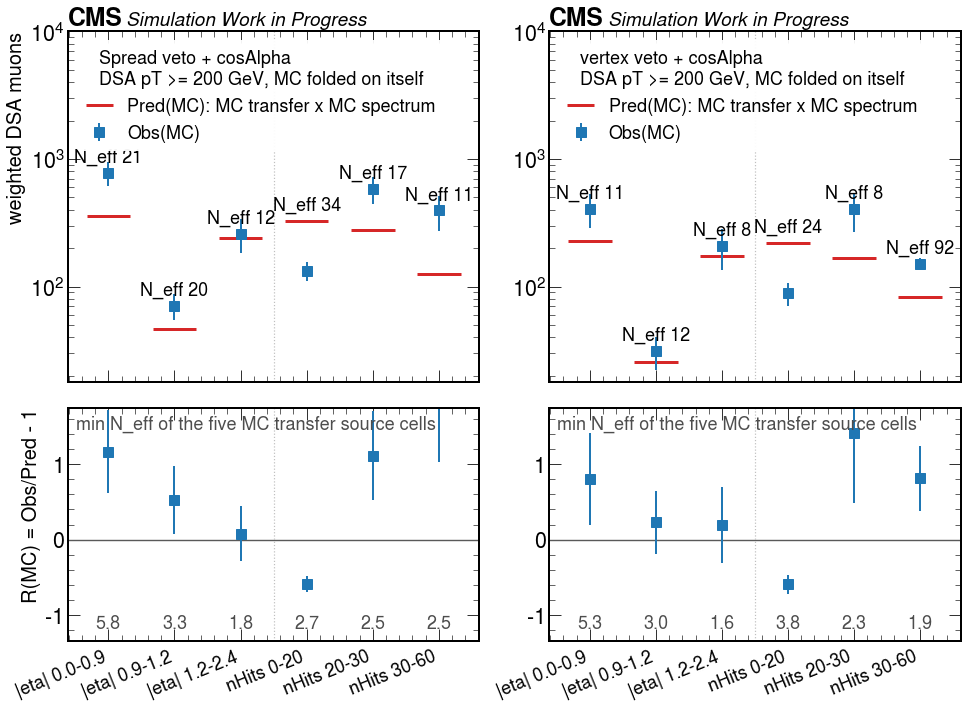

In [35]:
# Figure: the same fold applied to MC alone.  If the method worked, Pred_MC would reproduce
# Obs_MC.  N_eff above each point is the effective statistics of Obs_MC; the number along the
# bottom of the ratio panel is the SMALLEST N_eff among the five MC transfer cells that set
# Pred_MC, which is what the check's power actually rests on.
fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[2.4, 1.6], hspace=0.09, wspace=0.17)
tf_top = []
for ci, (reg, rlab) in enumerate(REGIONS):
    axy = fig.add_subplot(gs[0, ci])
    axr = fig.add_subplot(gs[1, ci], sharex=axy)
    obs = tf_col(reg, "TAIL", lambda e: e["obs_mc"])
    pred = tf_col(reg, "TAIL", lambda e: e["pred_mc"])
    Rm = tf_col(reg, "TAIL", lambda e: e["R_mc"])
    sRm = tf_col(reg, "TAIL", lambda e: e["sR_mc"])
    neff = tf_col(reg, "TAIL", lambda e: e["neff_mc"])
    nnum = np.array([min(r["mc_neff_num"]
                         for r in TF["transfer"][f"{reg}/{s}/{t4}"][:N_SRC])
                     for _l, s, _i, t4 in SLICES], float)
    axy.hlines(pred, XS - 0.33, XS + 0.33, color="tab:red", lw=3,
               label="Pred(MC): MC transfer x MC spectrum")
    axy.errorbar(XS, obs, yerr=obs / np.sqrt(neff), fmt="s", ms=10, lw=2, color="tab:blue",
                 label="Obs(MC)")
    for i in XS:
        axy.annotate(f"N_eff {neff[i]:.0f}", (i, max(obs[i], pred[i])),
                     textcoords="offset points", xytext=(0, 11), ha="center", fontsize=FS)
    axy.set_yscale("log")
    axy.set_ylim(18.0, 1.0e4)
    axy.axvline(2.5, color="0.75", lw=1.2, ls=":")
    axy.tick_params(labelbottom=False)
    axy.legend(fontsize=FS, loc="upper left", frameon=True, facecolor="white",
               edgecolor="none", framealpha=0.95,
               title=f"{rlab}\nDSA pT >= 200 GeV, MC folded on itself", title_fontsize=FS)
    if ci == 0:
        axy.set_ylabel("weighted DSA muons", fontsize=20)
    axr.axhline(0.0, color="0.35", lw=1.4)
    axr.errorbar(XS, Rm, yerr=sRm, fmt="s", ms=10, lw=2, color="tab:blue")
    for i in XS:
        axr.annotate(f"{nnum[i]:.1f}", (i, 0.055), xycoords=("data", "axes fraction"),
                     ha="center", fontsize=FS, color="0.30")
    axr.text(0.02, 0.97, "min N_eff of the five MC transfer source cells",
             transform=axr.transAxes, fontsize=FS, color="0.30", va="top")
    axr.axvline(2.5, color="0.75", lw=1.2, ls=":")
    axr.set_ylim(-1.35, 1.75)
    axr.set_xticks(XS)
    axr.set_xticklabels(XLAB, rotation=22, ha="right", fontsize=FS)
    if ci == 0:
        axr.set_ylabel("R(MC) = Obs/Pred - 1", fontsize=20)
    tf_top.append(axy)
for ax in tf_top:
    hep.cms.label(data=False, text="Work in Progress", rlabel="", ax=ax, fontsize=19)
fig.set_dpi(FIG_DPI)

### 10.3 What the segment match did fix

The fake-match exposure test compares, among control muons with response `r = pT_DSA/pT_PF > 2`,
the fraction that the fit itself flags as well measured (`sigma(pT)/pT < 0.3`) in data and MC.
With the segment-matched control the data/MC ratio of that fraction is 0.974 +/- 0.025 with no
veto, 0.975 +/- 0.026 with the Spread veto and 0.973 +/- 0.032 with the vertex veto
(dR-matched: 0.873 +/- 0.014, 0.872 +/- 0.015 and 0.853 +/- 0.017). The dR-matched deficit, 8.7
standard deviations with the Spread veto, could have meant that the data control was
contaminated differently from MC. It was an artifact of wrong partners, and that concern is
retired. What remains unchanged is the population mismatch: among lepton-jet DSA muons above
200 GeV only 9.5% carry `sigma(pT)/pT < 0.3`, against 45% of the control muons in the same
channel. The two populations differ in fit-quality composition, and a fold sliced in `|eta|`
and hit count does not absorb that difference.

### 10.4 The low-hit-count tail is not beam halo

Beam halo would put the `nHits < 20`, `pT >= 200` GeV tail at large `|dxy_BS|` (transverse
impact parameter with respect to the beamspot), horizontal in azimuth and in the endcaps, all
together. The segment-matched outputs book the quantities that test it. Against its own
same-slice bulk (`pT < 100` GeV), with the Spread veto:

- **Displacement.** 83% of the tail sits at `|dxy_BS| > 2` cm (bulk 63%), but only 13.5% beyond
  10 cm (bulk 13.3%). The un-vetoed channel puts 55% (`nHits < 20`) and 88% (`nHits >= 20`) of
  its tail beyond 10 cm; halo and cosmic muons live there, the surviving tail does not.
- **Detector.** 79% of the tail is CSC-only (bulk 64%, and 17% at `nHits >= 20`). The CSC-only
  fraction follows hit count, not momentum, and MC shows the same pattern (69% against 56%).
- **Azimuth.** The tail is horizontal by 3.6 standard deviations in this slice (`H/V = 1.37`
  against 1.01 for the bulk), but the two-template cosmic mixture is rejected (`p = 3e-6`), so
  no cosmic or halo fraction may be quoted from it.
- **Pseudorapidity.** The tail is forward (78% at `|eta| > 1.2` against 62% in the bulk), but so
  is MC's (69% against 54%), a similarly sized shift. This comparison is therefore not a
  data-specific effect the way the azimuth and `|dxy_BS|` comparisons are.
- **Co-localization.** In the full tail regardless of hit count (no histogram exists to restrict
  this check to `nHits < 20`), the horizontal-and-endcap corner holds 10.8% of it against 10.6%
  expected if azimuth and `|eta|` factorize: no co-localization.

Beam halo would need large displacement and a horizontal, endcap-localized azimuth together;
neither holds. Cosmics are excluded by sign. The best description is badly measured few-hit
endcap standalone muons, more forward and more displaced in data than in MC, though MC shares
part of the forward shift itself. A small halo admixture is not excluded, only shown not to
dominate. The segment-matched control in the same corner resembles the lepton-jet population
(73% at `|dxy_BS| > 2` cm, 78% CSC-only), which supports the premise of using it.

In [36]:
# phi x nHits and |eta| x nHits, recomputed from the same 68 chunks the fold used.
RESP_CH = {"spread_veto": CH_SPREAD, "vertex_veto": CH_VTX}
HN_PHI, HN_ETA = "mu_lj_dsaMuon_pt_phi_nHits", "mu_lj_dsaMuon_pt_abseta_nHits"
resp, resp_chan, resp_edges = {}, None, {}
for _n in PROV["data_samples"]:
    _H = coffea.util.load(f"{RESP_DIR}/{_n}.coffea")["out"][_n]["hists"]
    if resp_chan is None:
        resp_chan = {c: i for i, c in enumerate(list(_H[HN_PHI].axes[0]))}
        resp_edges = {h: [np.asarray(a.edges, float) for a in _H[h].axes[1:]]
                      for h in (HN_PHI, HN_ETA)}
    for _hn in (HN_PHI, HN_ETA):
        _v = np.asarray(_H[_hn].values(flow=True), float)
        resp[_hn] = _v.copy() if _hn not in resp else resp[_hn] + _v
print(f"summed {len(PROV['data_samples'])} data chunks of {PROV['chunks_expected']}")

# flow-view row groups of the coarse pT axis: [0,100), [100,200), >=200 with its overflow
PT_BULK, PT_SB, PT_TAIL = [1], [2], [3, 4]
NH_ROWS = {"nHits 0-20": [1], "nHits 20-30": [2], "nHits 30-60": [3, 4]}
PHI_EDGES = resp_edges[HN_PHI][1]
_c = 0.5 * (PHI_EDGES[1:] + PHI_EDGES[:-1])
VERT = np.where(np.minimum(abs(_c - math.pi / 2), abs(_c + math.pi / 2)) <= 0.5)[0]
HORZ = np.where(np.minimum(abs(_c), abs(abs(_c) - math.pi)) <= 0.5)[0]
print(f"phi bins {len(_c)} of width {PHI_EDGES[1]-PHI_EDGES[0]:.3f} rad; "
      f"vertical {[int(i) for i in VERT]}, horizontal {[int(i) for i in HORZ]}")


def resp_cube(hn, reg, nh, pt_rows_):
    """Collapse (pT, y, nHits) onto y for one channel, hit-count slice and pT region."""
    a = resp[hn][resp_chan[RESP_CH[reg]]]
    a = np.take(a, pt_rows_, axis=0).sum(axis=0)
    return np.take(a, NH_ROWS[nh], axis=-1).sum(axis=-1)[1:-1]


print(f"\n{'veto':7s} {'nHits':12s} {'pT':9s} {'N':>7s} {'V':>6s} {'H':>6s} {'V/H':>6s} "
      f"{'barrel':>7s} {'overlap':>8s} {'endcap':>7s}")
for reg in ("spread_veto", "vertex_veto"):
    for nh in NH_ROWS:
        for plab, prows in (("pT<100", PT_BULK), ("100-200", PT_SB), (">=200", PT_TAIL)):
            p = resp_cube(HN_PHI, reg, nh, prows)
            e = resp_cube(HN_ETA, reg, nh, prows)[:3]
            v, h = p[VERT].sum(), p[HORZ].sum()
            f = e / e.sum()
            print(f"{VETO[reg]:7s} {nh:12s} {plab:9s} {p.sum():7.0f} {v:6.0f} {h:6.0f} "
                  f"{v/max(h,1):6.3f} {f[0]:7.3f} {f[1]:8.3f} {f[2]:7.3f}")
print("\nA cosmic population is vertical and barrel; beam halo is horizontal and endcap.")

summed 68 data chunks of 68
phi bins 16 of width 0.393 rad; vertical [3, 4, 11, 12], horizontal [0, 7, 8, 15]

veto    nHits        pT              N      V      H    V/H  barrel  overlap  endcap
Spread  nHits 0-20   pT<100      81165  21514  21730  0.990   0.160    0.215   0.624
Spread  nHits 0-20   100-200      3594    935    977  0.957   0.160    0.186   0.654
Spread  nHits 0-20   >=200        1032    231    317  0.729   0.072    0.148   0.780
Spread  nHits 20-30  pT<100     150128  40452  36872  1.097   0.613    0.160   0.227
Spread  nHits 20-30  100-200      5078   1449   1257  1.153   0.724    0.105   0.172
Spread  nHits 20-30  >=200        1217    355    324  1.096   0.666    0.089   0.246
Spread  nHits 30-60  pT<100     104014  24750  26770  0.925   0.944    0.024   0.032
Spread  nHits 30-60  100-200      1997    498    478  1.042   0.952    0.014   0.034
Spread  nHits 30-60  >=200         635    166    141  1.177   0.956    0.014   0.030
vertex  nHits 0-20   pT<100      63233 

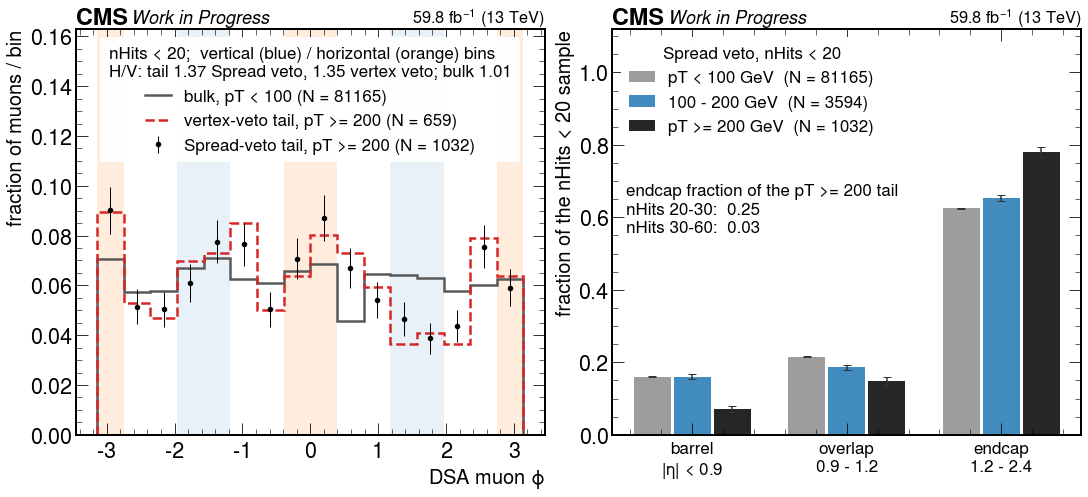

In [37]:
# Figure: the halo lead.  Left, the azimuth of the low-hit-count tail against its own low-pT
# bulk in the same channel and slice.  Right, its pseudorapidity composition against the same
# bulk, with the higher-hit-count tails quoted for contrast.
FS3 = 17            # 17 pt at a 15-inch width is 8.5 pt at text width
fig, axs = plt.subplots(1, 2, figsize=(15, 6.8), constrained_layout=True)

ax = axs[0]
tail_spread = resp_cube(HN_PHI, "spread_veto", "nHits 0-20", PT_TAIL)
bulk_spread = resp_cube(HN_PHI, "spread_veto", "nHits 0-20", PT_BULK)
tail_vertex = resp_cube(HN_PHI, "vertex_veto", "nHits 0-20", PT_TAIL)
for i in VERT:
    ax.axvspan(PHI_EDGES[i], PHI_EDGES[i + 1], color="tab:blue", alpha=0.10, lw=0)
for i in HORZ:
    ax.axvspan(PHI_EDGES[i], PHI_EDGES[i + 1], color="tab:orange", alpha=0.14, lw=0)
hep.histplot(bulk_spread / bulk_spread.sum(), PHI_EDGES, ax=ax, histtype="step", lw=2.5, color="0.35",
             label=f"bulk, pT < 100 (N = {bulk_spread.sum():.0f})")
hep.histplot(tail_vertex / tail_vertex.sum(), PHI_EDGES, ax=ax, histtype="step", lw=2.5, ls="--",
             color="tab:red", label=f"vertex-veto tail, pT >= 200 (N = {tail_vertex.sum():.0f})")
hep.histplot(tail_spread / tail_spread.sum(), PHI_EDGES, ax=ax, histtype="errorbar", color="k",
             yerr=np.sqrt(tail_spread) / tail_spread.sum(), markersize=9,
             label=f"Spread-veto tail, pT >= 200 (N = {tail_spread.sum():.0f})")
ax.set_xlabel(r"DSA muon $\phi$", fontsize=20)
ax.set_ylabel("fraction of muons / bin", fontsize=20)
ax.set_ylim(0, 0.163)
hv = lambda a: a[HORZ].sum() / a[VERT].sum()
ax.legend(fontsize=FS3, loc="upper center", frameon=True, facecolor="white",
          edgecolor="none", framealpha=0.95,
          title=("nHits < 20;  vertical (blue) / horizontal (orange) bins\n"
                 f"H/V: tail {hv(tail_spread):.2f} Spread veto, {hv(tail_vertex):.2f} vertex veto; "
                 f"bulk {hv(bulk_spread):.2f}"), title_fontsize=FS3)

ax = axs[1]
xs, w = np.arange(3), 0.26
for j, (plab, prows, col) in enumerate(
        (("pT < 100 GeV", PT_BULK, "0.55"), ("100 - 200 GeV", PT_SB, "tab:blue"),
         ("pT >= 200 GeV", PT_TAIL, "k"))):
    e = resp_cube(HN_ETA, "spread_veto", "nHits 0-20", prows)[:3]
    n = e.sum()
    f = e / n
    ax.bar(xs + (j - 1) * w, f, width=w * 0.92, color=col, alpha=0.85,
           yerr=np.sqrt(f * (1 - f) / n), capsize=4, ecolor="0.2",
           label=f"{plab}  (N = {n:.0f})")
ax.set_xticks(xs)
ax.set_xticklabels([r"barrel" "\n" r"$|\eta|$ < 0.9", "overlap\n0.9 - 1.2",
                    "endcap\n1.2 - 2.4"], fontsize=FS3)
ax.set_ylabel("fraction of the nHits < 20 sample", fontsize=20)
ax.set_ylim(0, 1.12)
_hi = [resp_cube(HN_ETA, "spread_veto", nh, PT_TAIL)[:3] for nh in ("nHits 20-30", "nHits 30-60")]
ax.text(0.03, 0.62, "endcap fraction of the pT >= 200 tail\n"
        f"nHits 20-30:  {_hi[0][2]/_hi[0].sum():.2f}\n"
        f"nHits 30-60:  {_hi[1][2]/_hi[1].sum():.2f}",
        transform=ax.transAxes, fontsize=FS3, va="top")
ax.legend(fontsize=FS3, loc="upper left", frameon=True, facecolor="white", edgecolor="none",
          framealpha=0.95, title="Spread veto, nHits < 20", title_fontsize=FS3)
for ax in axs:
    hep.cms.label(data=True, lumi=L_TF, text="Work in Progress", ax=ax, fontsize=18)
fig.set_dpi(FIG_DPI)

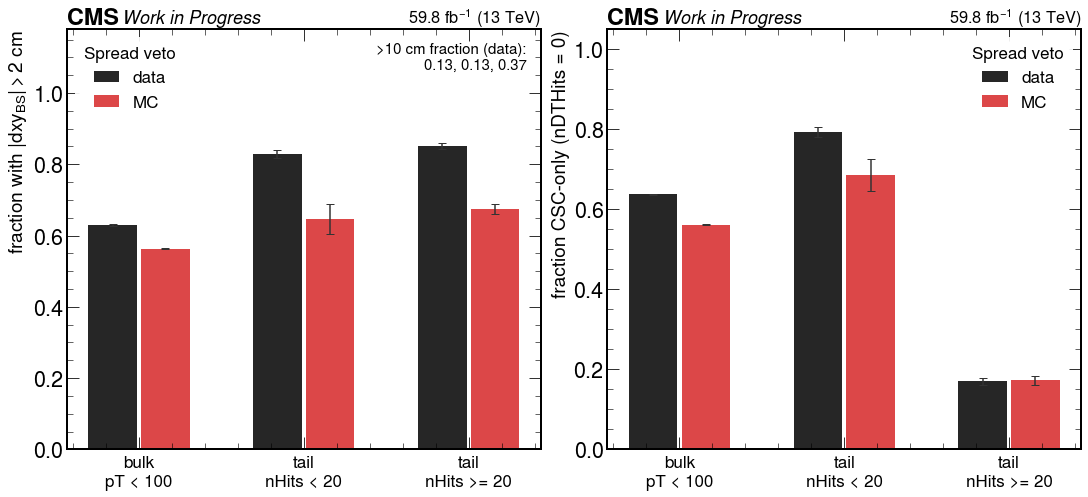

In [38]:
# Figure: the halo diagnostics from tf_seg_aux.json - |dxy_BS| and the DT/CSC hit split -
# are booked only in the segment-matched outputs. Same tail (nHits < 20, pT >= 200) and same-slice
# bulk (pT < 100) as the figure above, Spread veto only, data and MC; the tail restricted
# to nHits >= 20 is shown too, for the same contrast the eta panel above draws.
FS4 = 17
fig, axs = plt.subplots(1, 2, figsize=(15, 6.8), constrained_layout=True)
CATS = [("bulk\npT < 100", "low_lowNH"), ("tail\nnHits < 20", "tail_lowNH"),
        ("tail\nnHits >= 20", "tail_highNH")]
xs4 = np.arange(len(CATS))
w4 = 0.32

ax = axs[0]
for j, (src, col) in enumerate((("data", "k"), ("mc", "tab:red"))):
    ys = [AUX["halo"][f"{src}/spread_veto"][slc]["f_absdxyBS_gt2"] for _l, slc in CATS]
    es = [AUX["halo"][f"{src}/spread_veto"][slc]["e_gt2"] for _l, slc in CATS]
    ax.bar(xs4 + (j - 0.5) * w4, ys, width=w4 * 0.92, yerr=es, capsize=4, ecolor="0.2",
           color=col, alpha=0.85, label=("data" if src == "data" else "MC"))
gt10_d = [AUX["halo"]["data/spread_veto"][slc]["f_absdxyBS_gt10"] for _l, slc in CATS]
ax.text(0.97, 0.97, ">10 cm fraction (data):\n" + ", ".join(f"{v:.2f}" for v in gt10_d),
        transform=ax.transAxes, fontsize=FS4 - 2, ha="right", va="top")
ax.set_xticks(xs4)
ax.set_xticklabels([c[0] for c in CATS], fontsize=FS4)
ax.set_ylabel(r"fraction with $|dxy_{BS}| > 2$ cm", fontsize=19)
ax.set_ylim(0, 1.18)
ax.legend(fontsize=FS4, loc="upper left", frameon=True, facecolor="white", edgecolor="none",
          framealpha=0.92, title="Spread veto", title_fontsize=FS4)

ax = axs[1]
for j, (src, col) in enumerate((("data", "k"), ("mc", "tab:red"))):
    ys = [AUX["halo"][f"{src}/spread_veto"][slc]["f_cscOnly"] for _l, slc in CATS]
    es = [AUX["halo"][f"{src}/spread_veto"][slc]["e_cscOnly"] for _l, slc in CATS]
    ax.bar(xs4 + (j - 0.5) * w4, ys, width=w4 * 0.92, yerr=es, capsize=4, ecolor="0.2",
           color=col, alpha=0.85, label=("data" if src == "data" else "MC"))
ax.set_xticks(xs4)
ax.set_xticklabels([c[0] for c in CATS], fontsize=FS4)
ax.set_ylabel("fraction CSC-only (nDTHits = 0)", fontsize=19)
ax.set_ylim(0, 1.05)
ax.legend(fontsize=FS4, loc="upper right", frameon=True, facecolor="white", edgecolor="none",
          framealpha=0.92, title="Spread veto", title_fontsize=FS4)

for ax in axs:
    hep.cms.label(data=True, lumi=L_TF, text="Work in Progress", ax=ax, fontsize=18)
fig.set_dpi(FIG_DPI)

### 10.5 Outcome

The fold was to be used only if its MC self-closure held. It does not: in the `nHits < 20` slice
of the Spread-veto channel `R_MC = -0.592 +/- 0.104`, 5.7 standard deviations from zero, so in
MC the fold over-predicts the tail by a factor 2.45. Without any veto, where the cosmics are
still in the tail, the data closure of the same slice is `R = +0.352 +/- 0.223`; a fold able to
detect that excess would give `R > 1` there. The cause is the method's own bias in the
low-hit-count slice, not the control definition: the dR-matched control fails the same way
(`R_MC = -0.609 +/- 0.096`). Nothing from this section is applied, and no `nHits` cut is
adopted.

## 11. Conclusions

**On the veto comparison.** The vertex veto tags the same cosmics as the Spread veto. It flags
98% of the mu-type lepton jets in the spread-inverted cosmic region, which is defined without
any reference to the vertex tables, and after either veto the surviving tail is equally
non-cosmic. It has no additional data-versus-MC separating power: the data/MC ratio of the
lepton jets it keeps is flat at 0.75 across four decades of threshold, against 0.77 with no cut
at all. It leaves the same residual data/MC above 200 GeV (2.38 against 2.31 on the same
background stack, and 2.39 for the Spread veto on the eight-sample tail set). And it keeps 28%
fewer signal lepton jets: 0.690 of the reference channel against 0.961 for the Spread veto,
averaged over the 162 robust points of the grid. These signal efficiencies are for the Spread
veto in its as-run `vxySpread` form; `main`'s `dxySpread` form was not run on signal. The
vertex veto keeps more signal only in one corner: `m_Zd = 5` GeV, mediator mass 100 to 150 GeV,
`ctau >= 130` mm, which is 8 of the 180 signal samples when efficiency is counted per DSA muon
(6 counted per lepton jet). There the max-over-pairs Spread variables start failing on wide,
displaced pairs and the min-over-pairs vertex requirement does not.

**On the tail.** The Spread veto with the cosAlpha cut removes 87% of the >= 200 GeV DSA-muon
tail in 2018C data (2414 -> 309). In MC it removes 54% of the **full background stack's** tail
(293.6 -> 133.7) and 3% of the **eight-sample tail set's** (133.7 -> 129.5); the two describe
different MC sets, and neither number travels without its label. The removed component is
unambiguously cosmic: the pre-veto tail has a vertical/horizontal `phi` ratio of 12.2 +/- 1.3
against an MC expectation of 1.3 +/- 0.2, and is 93% barrel against 71% in MC. Two independent
routes put its cosmic content at 87% (veto retention measured against the MC prompt-muon
reference) and 84% (the two-template `phi` fit). What survives is not cosmic. The post-veto
tail `phi` ratio is 0.94 +/- 0.15, consistent with MC and incompatible with the cosmic
template. This bounds any residual cosmic contribution below 6.2% of the tail at 95% CL, a
bound that moves only to 7.8% even if the template's vertical fraction is degraded from 0.99 to
0.90.

The surviving tail exceeds MC by 2.4 +/- 0.4 (eight-sample tail set), and that ratio is not the
load-bearing number: its denominator sits in a control region where MC carries 38% more DSA
muons per mu-type lepton jet than data (section 3.1), and no scale factor is applied anywhere.
The statement that does carry is a ratio of rates, which is immune to that mismatch. In an
independent DSA-PF matched control, data over-produces >= 200 GeV DSA muons from < 100 GeV PF
muons (feed-up) by 3.47 +/- 0.25 relative to MC. Dividing the post-veto tail rate by that
feed-up rate gives **0.95 +/- 0.06 in data and 0.99 +/- 0.18 in MC**, both consistent with one,
against 4.81 +/- 0.13 for data before the veto. This is a consistency statement of about
factor-1.5 precision, not a demonstration that the two agree: the control rate is measured
before the veto on a different (matched, `pT_PF < 100` GeV) population, the mismodelling is not
flat in `|eta|` or nHits, and the closure moves between 0.70 and 1.41 in data and between 0.57
and 1.35 in MC as the `pT_PF` threshold moves. Section 10.4 books `phi` x `nHits` on the full
2018 sample. There the `nHits < 20` tail after the Spread veto is more horizontal than vertical
(vertical/horizontal 0.73 against 0.99 for its own low-pT bulk), the opposite of the cosmic
signature, and it is not displaced the way beam halo would be; it reads as badly measured
few-hit endcap standalone muons.

**Three things that are easy to over-read and should not be.**

1. The post-veto tail *looks* concentrated at low hit count (shape chi2 37.5/3), but the bulk
   carries the same distortion at 15 sigma: data has 1.5 to 1.7 times more low-nHits DSA muons
   than MC everywhere. Dividing it out leaves a tail-specific effect of 1.95 +/- 0.46, 2.1
   sigma, and even that denominator is measured on an MC set covering half the stack. The chi2
   itself is diagonal-only and moves by a factor of about four with the definition of the test
   (17.7/3, 39.7/3 or 75.3/3 on the same four bins), which is why the 1.95 +/- 0.46, and not a
   chi2, is quoted as the result. The `|eta|` structure is different: it *is* tail-specific
   (bulk chi2 1.6/2 against tail 238.5/2), and it is the cosmic fingerprint.
2. The MC tail rests on an effective 35 events, two samples of which contribute single
   weighted events. Every MC-normalized number here inherits that, the +/- 0.4 on the 2.4 and
   the +/- 0.18 on the MC closure alike. That is why "in simulation the tail is resolution
   feed-up and nothing else" is a claim this study cannot make at 18% precision.
3. The vertex-inverted cosmic region used as the `phi` template is 94% high-hit-count, but it
   selects on a back-to-back muon pair, and cosAlpha is exactly what a short track reconstructs
   worst. It therefore gives no evidence that the low-nHits survivors are cosmic, and none that
   they are not; the inclusive 6.2% bound still allows a residual reaching ~15% of that
   126-event subset.

**Recommendation.** Keep the Spread veto with the cosAlpha cut, `main`'s baseline since PR #56,
and do not adopt the vertex veto. Add no further object cut. `nHits >= 20` removes 41% of the
post-veto data tail (309 -> 183) and takes its data/MC (eight-sample tail set) from 2.39 to
1.61; the `nHits < 20` part it removes carries 110.4 of the tail's 179.5-event excess over MC.
It costs 15% of the signal DSA muons at all pT (8% of those in the tail, which hold only 6.75%
of them), and it is itself mismodelled: it removes 24.5% of the data bulk against 14.1% of the
MC bulk, so it would need its own scale factor. `sigma(pT)/pT < 0.3` keeps 0.145 of the MC tail
against 0.084 of the data tail, so it moves the ratio the wrong way, and it costs 44% of the
signal at a 1 TeV mediator. The section-10 transfer factor fails its MC self-closure, so no
correction from the DSA-PF control is available; the residual DSA high-pT rate has to be set
from data in the background estimate. The vertex-fit code, its channels and its histograms stay
in the repository as a documented negative result: the variable is validated and behaves as
specified, and outside one corner of the signal grid it is not useful here.

**On the transfer-factor fold (section 10).** The fold of the segment-matched control onto the
lepton jets' own low-pT DSA muons, at full 2018 statistics, fails its MC self-closure. In the
`nHits < 20` slice of the Spread-veto channel it over-predicts the MC tail by a factor 2.45
(`R_MC = -0.592 +/- 0.104`), and in data it over-predicts the 100-200 GeV sideband of that slice
by 7.7 statistical standard deviations with the Spread veto and 11.0 with the vertex veto. The
segment match retired one limitation (the fake-match exposure, section 10.3) and nothing else.
No hit-count cut is adopted, and beam halo is not supported as the origin of the low-hit tail.
The residual DSA-muon tail above 200 GeV after the Spread and cosAlpha vetoes therefore belongs
in the background estimate as a rate the data must set, not in a topology cut and not in this
transfer factor. The instrumentation added here (segment-matched control histograms,
`|dxy_BS|`, DT/CSC hit split and three-dimensional histograms of DSA-muon pT against azimuth and hit
count, `|eta|` and hit count, and azimuth and `|eta|`) stays in the code for whoever takes
it further.

In [39]:
print("Summary numbers quoted in the conclusions, recomputed:")
print(f"  control-region normalization (Before): {lj_d/lj_m:.3f} per mu-type LJ, "
      f"{ds_d/ds_m:.3f} per DSA muon; MC carries "
      f"{100*((ds_m/lj_m)/(ds_d/lj_d) - 1):.0f}% more DSA muons per LJ")
print(f"  spread-inverted cosmic LJs failing 0 <= vtx_chi2 < 5 : "
      f"{1 - kept(v_cos, 5)/v_cos.sum():.3f}")
print(f"  data/MC of the LJs the vertex veto keeps, thresholds 2 to 1e4: "
      f"{dmc_kept.min():.3f} to {dmc_kept.max():.3f} (no cut {tot_d/tot_m:.3f})")
print(f"  signal efficiency per LJ, robust subset: Spread "
      f"{S['lj_sp'][robust].mean():.4f}, vertex fit {S['lj_vt'][robust].mean():.4f}")
print(f"  samples where vtx beats Spread: {int((S['dsa_vt'] > S['dsa_sp']).sum())} per DSA "
      f"muon, {int((S['lj_vt'] > S['lj_sp']).sum())} per LJ, of {len(sig_names)}")
print(f"  tail yields: data {lj['Before']['d_tail']:.0f} -> "
      f"{lj['Spread+cosAlpha']['d_tail']:.0f} "
      f"({100*(1 - lj['Spread+cosAlpha']['d_tail']/lj['Before']['d_tail']):.0f}% removed);  "
      f"MC, 8-sample tail set {lj['Before']['m_tail']:.1f} -> "
      f"{lj['Spread+cosAlpha']['m_tail']:.1f} "
      f"({100*(1 - lj['Spread+cosAlpha']['m_tail']/lj['Before']['m_tail']):.0f}% removed)")
_fsb = sum(tot(s, CH_BEFORE, 200, scale=ratio) for s in summed_MC)
_fss = sum(tot(s, CH_SPREAD, 200, scale=ratio) for s in summed_MC)
print(f"    the same MC tail on the FULL stack: {_fsb:.1f} -> {_fss:.1f} "
      f"({100*(1 - _fss/_fsb):.0f}% removed) - different set, different number")
print(f"  post-veto tail data/MC  : {meas:.3f} +/- {e_meas:.3f} (8-sample tail set); "
      f"{lj['Spread+cosAlpha']['d_tail']/_fss:.2f} on the full stack")
print(f"  phi V/H, tail           : Before {phi_res[('Before','tail')][0]:.2f} "
      f"+/- {phi_res[('Before','tail')][1]:.2f}  ->  Spread+cosAlpha "
      f"{phi_res[('Spread+cosAlpha','tail')][0]:.2f} "
      f"+/- {phi_res[('Spread+cosAlpha','tail')][1]:.2f}  "
      f"(MC {phi_res[('Spread+cosAlpha','tail')][2]:.2f} "
      f"+/- {phi_res[('Spread+cosAlpha','tail')][3]:.2f}, cosmic template "
      f"{phi_res[('vertex-inverted cosmic','tail')][0]:.1f})")
print(f"  residual cosmic fraction: < {f_ul:.3f} at 95% CL "
      f"(< {f_ul*d_tail:.0f} of {d_tail:.0f} events)")
print(f"  feed-up data/MC         : {FU['ratio']:.3f} +/- {FU['e_ratio']:.3f}")
print(f"  rate closure (tail rate / feed-up rate), post-veto: "
      f"data {CLOS[('Spread+cosAlpha','data')][0]:.3f} "
      f"+/- {CLOS[('Spread+cosAlpha','data')][1]:.3f}, "
      f"MC {CLOS[('Spread+cosAlpha','MC')][0]:.3f} "
      f"+/- {CLOS[('Spread+cosAlpha','MC')][1]:.3f}")
print(f"    pre-veto: data {CLOS[('Before','data')][0]:.2f} "
      f"+/- {CLOS[('Before','data')][1]:.2f}, "
      f"MC {CLOS[('Before','MC')][0]:.2f} +/- {CLOS[('Before','MC')][1]:.2f}")
print(f"  nHits >= 20 signal cost : {1 - wavg('keep_all'):.3f} of signal DSA muons at all pT, "
      f"{1 - np.nansum(kt * wt) / wt[np.isfinite(kt)].sum():.3f} of those in the tail")
print(f"  P(r>2) data/MC {RESP[2.0][0]:.3f} +/- {RESP[2.0][1]:.3f}, "
      f"P(r>5) {RESP[5.0][0]:.3f} +/- {RESP[5.0][1]:.3f}; "
      f"flatness chi2 |eta| {FLAT['|eta|'][1]:.1f}/{FLAT['|eta|'][2]}, "
      f"nHits {FLAT['nHits'][1]:.1f}/{FLAT['nHits'][2]}")
c2t_n = DR[("nHits", "Spread+cosAlpha")][2]
c2b_n = DR[("nHits", "Spread+cosAlpha")][3]
dr_lo = DR[("nHits", "Spread+cosAlpha")][0][0]
db_lo = DR[("nHits", "Spread+cosAlpha")][1][0]
tb    = dr_lo[3] / db_lo[3]
etb   = tb * math.sqrt((dr_lo[4]/dr_lo[3]) ** 2 + (db_lo[4]/db_lo[3]) ** 2)
print(f"  nHits shape chi2        : tail {c2t_n:.1f}/3, bulk {c2b_n:.0f}/3; "
      f"low-nHits tail/bulk {tb:.2f} +/- {etb:.2f} ({abs(tb-1)/etb:.1f} sigma)")
print(f"  |eta| shape chi2 (Before): tail {DR[('|eta|','Before')][2]:.1f}/2, "
      f"bulk {DR[('|eta|','Before')][3]:.1f}/2")

Summary numbers quoted in the conclusions, recomputed:
  control-region normalization (Before): 0.770 per mu-type LJ, 0.556 per DSA muon; MC carries 38% more DSA muons per LJ
  spread-inverted cosmic LJs failing 0 <= vtx_chi2 < 5 : 0.980
  data/MC of the LJs the vertex veto keeps, thresholds 2 to 1e4: 0.747 to 0.758 (no cut 0.770)
  signal efficiency per LJ, robust subset: Spread 0.9608, vertex fit 0.6897
  samples where vtx beats Spread: 8 per DSA muon, 6 per LJ, of 180
  tail yields: data 2414 -> 309 (87% removed);  MC, 8-sample tail set 133.7 -> 129.5 (3% removed)
    the same MC tail on the FULL stack: 293.6 -> 133.7 (54% removed) - different set, different number
  post-veto tail data/MC  : 2.385 +/- 0.426 (8-sample tail set); 2.31 on the full stack
  phi V/H, tail           : Before 12.23 +/- 1.29  ->  Spread+cosAlpha 0.94 +/- 0.15  (MC 1.23 +/- 0.21, cosmic template 107.6)
  residual cosmic fraction: < 0.062 at 95% CL (< 19 of 309 events)
  feed-up data/MC         : 3.474 +/- 0.